# 02 — LVVI3 data exploration

**Step 02 of the LVVI3 preprocessing pipeline** (`scripts/LVVI3/data_preprocessing/`). Step 01 (`01_lvvi3_data_preprocessing.ipynb`) decodes, translates and merges the raw LVVI3 survey responses into the main survey table; this notebook explores that table.

- **Purpose**: exploratory analysis of the main LVVI3 survey table — visit-type profiling (MCA + Ward hierarchical clustering on visit variables) followed by section-wise EDA of demographics, activities, motivations, travel behaviour, opinions and survey-area geography.
- **Inputs**: `data/LVVI3/lvvi3_survey_en.csv` (451 rows × 128 cols, English columns, one row per respondent × reported activity; currently exactly one activity per respondent), `data/boundaries/SuomenHallinnollisetKuntajakopohjaisetAluejaot_2026_10k.gpkg` (municipality map for the survey-area section, layer `Kunta`).
- **Outputs**: none — analysis only, no data files are written. The MCA/Ward visit-type clustering below is exploratory profiling only and is **not** consumed by any downstream script.

Paths below are relative to the notebook folder (kernel working directory).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("../../../data/LVVI3/lvvi3_survey_en.csv")
df_or = df[df.source == "or"].copy()      # day-trip visitors
df_nbt = df[df.source == "nbt"].copy()    # multi-day trip visitors

print(f"All visitors: {df.shape[0]}")
print(f"Daytrip visitors: {df_or.shape[0]}")
print(f"Multiday trip visitors: {df_nbt.shape[0]}")

All visitors: 451
Daytrip visitors: 165
Multiday trip visitors: 286


# Visit-based approach

A visit is a temporary configuration of activities, accompanies, motivations, travel behaviors.

Application cases:
- Understanding pressure on sites
- Understanding facility needs
- Understanding conflict between visitor uses
- Designing zoning, infrastructure, and services

## Prepare variables

Two-level activity coding: each specific `activity` is mapped to a broader **structural activity** category.

In [2]:
# Create two-level activity coding
df["activity_specific"] = df["activity"]

# Define structural activity categories
activity_map = {
    # Light movement / walking
    "Walking": "Light movement / walking",

    # Nature immersion / camping
    "Camping": "Nature immersion / camping",
    "Staying in a summer cottage, farm, holiday home": "Nature immersion / camping",
    "Staying overnight in a tent, lodge, etc. in natural terrain": "Nature immersion / camping",
    "Travelling or staying in a caravan or camper": "Nature immersion / camping",

    # Active outdoor sports
    "Skiing": "Active outdoor sports",
    "Running": "Active outdoor sports",
    "Cycling": "Active outdoor sports",
    "Skating": "Active outdoor sports",
    "Snowmobiling": "Active outdoor sports",
    "Climbing": "Active outdoor sports",
    "Orienteering": "Active outdoor sports",

    # Leisure use
    "Outdoor activities with dogs": "Leisure use",
    "Outdoor activities with children": "Leisure use",
    "Picnicking": "Leisure use",
    "Swimming": "Leisure use",
    "Boating": "Leisure use",

    # Nature-dependent extraction
    "Fishing": "Nature-dependent extraction",
    "Hunting": "Nature-dependent extraction",
    "Nature product collection": "Nature-dependent extraction",

    # Nature appreciation
    "Nature photography": "Nature appreciation",
    "Bird watching": "Nature appreciation",
    "Nature observation": "Nature appreciation",

    # Playful recreation
    "Golf": "Playful recreation",
    "Treasure hunting": "Playful recreation",
    "Frisbee golf": "Playful recreation",

    # Others
    "Guided tour": "Others",
    "Nature management": "Others",
}

df["activity_structural"] = df["activity"].map(activity_map)

# Tolerant fallback: keep any unmapped activity instead of dropping it
unmapped = sorted(df.loc[df["activity_structural"].isna(), "activity"].unique())
df["activity_structural"] = df["activity_structural"].fillna("Others")
print("Unmapped activities (assigned to 'Others'):", unmapped)

df["activity_structural"].value_counts()

Unmapped activities (assigned to 'Others'): ['Dog walking']


/tmp/xuleyi11/ipykernel_1312704/1289082244.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["activity_specific"] = df["activity"]
/tmp/xuleyi11/ipykernel_1312704/1289082244.py:51: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["activity_structural"] = df["activity"].map(activity_map)


activity_structural
Light movement / walking       219
Active outdoor sports           83
Nature-dependent extraction     42
Leisure use                     35
Others                          30
Nature appreciation             19
Nature immersion / camping      17
Playful recreation               6
Name: count, dtype: int64

In [3]:
accompany_map = {
    1.0: "Alone",
    2.0: "With family",
    3.0: "With friends",
    4.0: "With work colleagues/business guests",
    5.0: "With school class/student group",
    6.0: "With club, association",
    7.0: "With other group",
}

df["accompany"] = df["B_2_accompany"].map(accompany_map)

/tmp/xuleyi11/ipykernel_1312704/3981224528.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["accompany"] = df["B_2_accompany"].map(accompany_map)


In [4]:
# Select visit-related variables
visit_vars = ['activity_structural', 'accompany']
df_mca = df[visit_vars]

# Make sure variables are categorical
for col in visit_vars:
    df_mca[col] = df_mca[col].astype("category")

### Exploratory clustering (profiling only — NOT a pipeline output; the visit-type clusters are not consumed by any downstream script)

## Apply Multiple Correspondence Analysis (MCA) to transform categorical variables into numeric coordinates

In [5]:
# Run MCA
import prince

mca = prince.MCA(
    n_components=5,
    n_iter=10,
    random_state=42
)

mca = mca.fit(df_mca)
mca_coords = mca.transform(df_mca)

In [6]:
# Decide the number of dimensions to retain
mca.percentage_of_variance_

array([10.02394187,  9.46460222,  8.55937285,  8.25889473,  8.17632831])

In [7]:
# Select MCA dimensions for clustering
mca_coords_reduced = mca_coords.iloc[:, :3]

## Determine the number of clusters

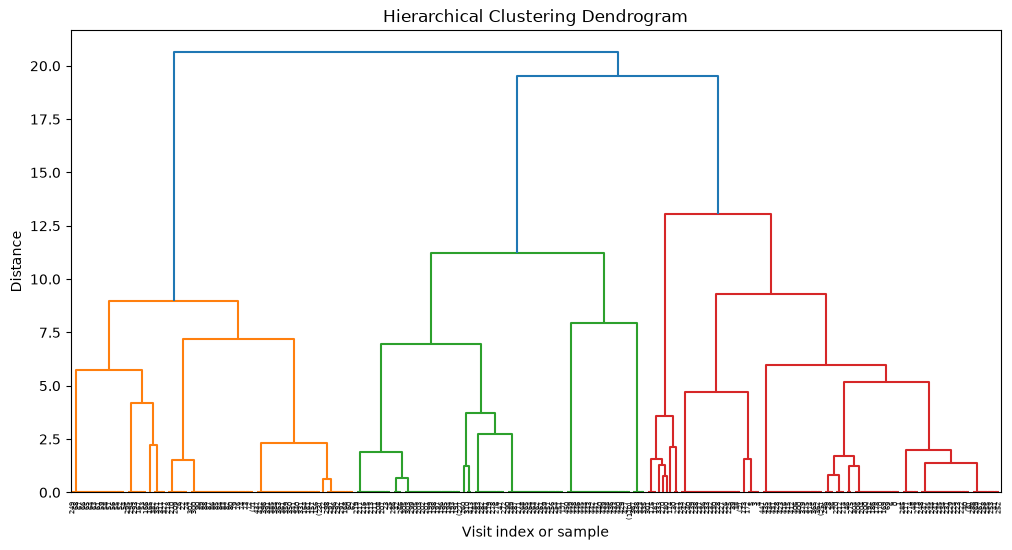

In [8]:
from scipy.cluster.hierarchy import linkage, dendrogram

# Compute linkage matrix (Ward method matches your clustering)
Z = linkage(mca_coords_reduced, method='ward')

# Dendrogram plot
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='level', p=20, leaf_rotation=90)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Visit index or sample')
plt.ylabel('Distance')
plt.show()

In [9]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering

range_n_clusters = range(2, 10)
for n_clusters in range_n_clusters:
    clusterer = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
    cluster_labels = clusterer.fit_predict(mca_coords_reduced)
    silhouette_avg = silhouette_score(mca_coords_reduced, cluster_labels)
    print(f"n_clusters = {n_clusters}, silhouette_score = {silhouette_avg:.3f}")

n_clusters = 2, silhouette_score = 0.370
n_clusters = 3, silhouette_score = 0.457
n_clusters = 4, silhouette_score = 0.479
n_clusters = 5, silhouette_score = 0.528
n_clusters = 6, silhouette_score = 0.564
n_clusters = 7, silhouette_score = 0.600
n_clusters = 8, silhouette_score = 0.616
n_clusters = 9, silhouette_score = 0.667


## Apply hierarchical clustering

In [10]:
# Apply hierarchical clustering
from sklearn.cluster import AgglomerativeClustering

# Choose 5 clusters as initial guess
clusterer = AgglomerativeClustering(n_clusters=5, linkage='ward')
df['visit_type'] = clusterer.fit_predict(mca_coords_reduced)

/tmp/xuleyi11/ipykernel_1312704/2297076448.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['visit_type'] = clusterer.fit_predict(mca_coords_reduced)


In [11]:
df['visit_type'].value_counts()

visit_type
2    131
0    117
1    105
4     89
3      9
Name: count, dtype: int64

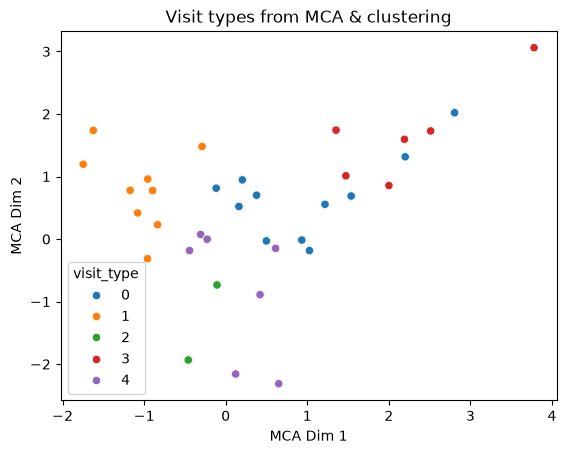

In [12]:
sns.scatterplot(x=mca_coords_reduced.iloc[:, 0],
                y=mca_coords_reduced.iloc[:, 1],
                hue=df['visit_type'],
                palette='tab10')
plt.xlabel('MCA Dim 1')
plt.ylabel('MCA Dim 2')
plt.title('Visit types from MCA & clustering')
plt.show()

## Profile visit type

### Activities

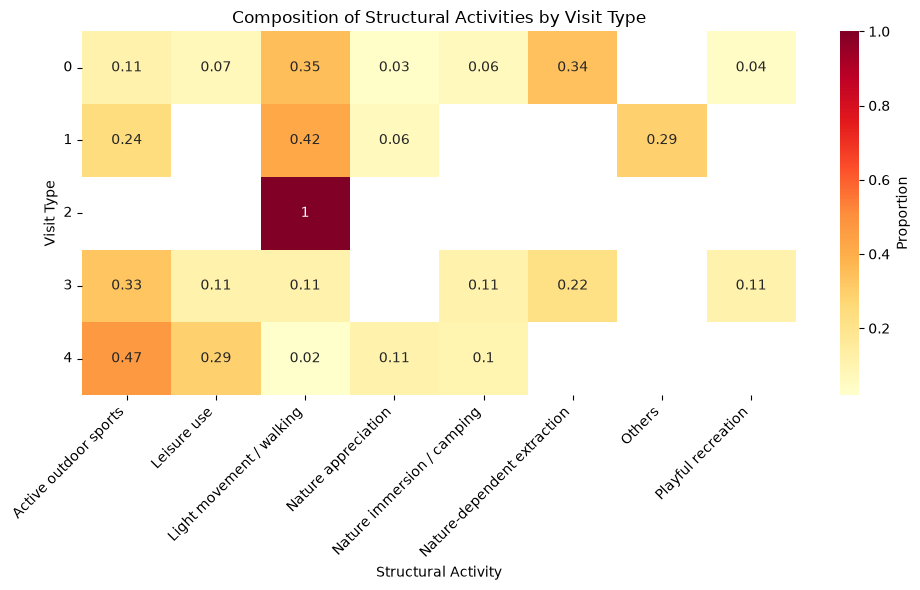

In [13]:
# Compute normalized composition of activities by visit type
activity_profile = df.groupby('visit_type')['activity_structural'].value_counts(normalize=True).unstack().round(2)

plt.figure(figsize=(10, 6))
sns.heatmap(activity_profile, annot=True, cmap='YlOrRd', cbar_kws={'label': 'Proportion'})
plt.title('Composition of Structural Activities by Visit Type')
plt.ylabel('Visit Type')
plt.xlabel('Structural Activity')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

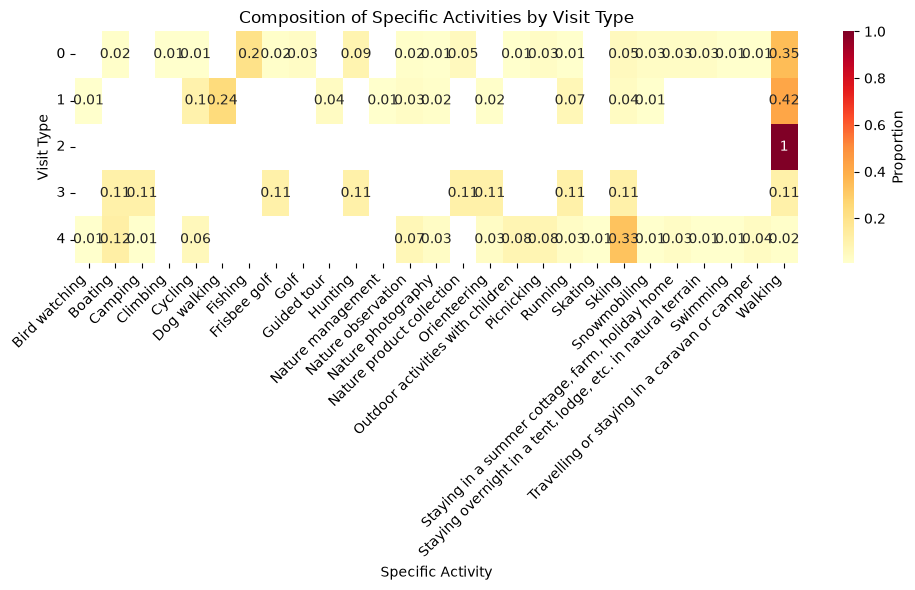

In [14]:
# Compute normalized composition of specific activities by visit type
activity_specific_profile = df.groupby('visit_type')['activity_specific'].value_counts(normalize=True).unstack().round(2)

plt.figure(figsize=(10, 6))
sns.heatmap(activity_specific_profile, annot=True, cmap='YlOrRd', cbar_kws={'label': 'Proportion'})
plt.title('Composition of Specific Activities by Visit Type')
plt.ylabel('Visit Type')
plt.xlabel('Specific Activity')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Accompany patterns

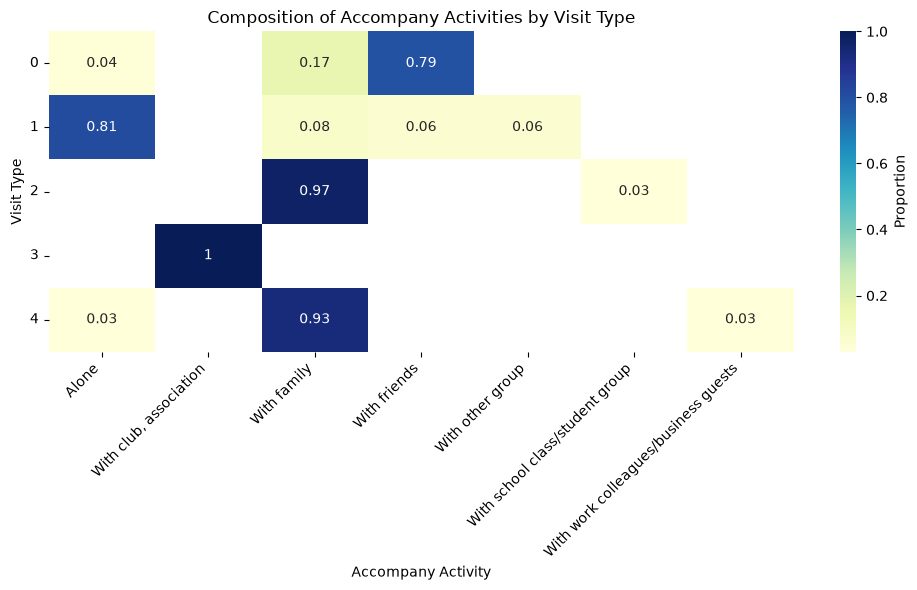

In [15]:
# Compute normalized composition of accompany patterns by visit type
accompany_profile = df.groupby('visit_type')['accompany'].value_counts(normalize=True).unstack().round(2)

plt.figure(figsize=(10, 6))
sns.heatmap(accompany_profile, annot=True, cmap='YlGnBu', cbar_kws={'label': 'Proportion'})
plt.title('Composition of Accompany Activities by Visit Type')
plt.ylabel('Visit Type')
plt.xlabel('Accompany Activity')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Motivations

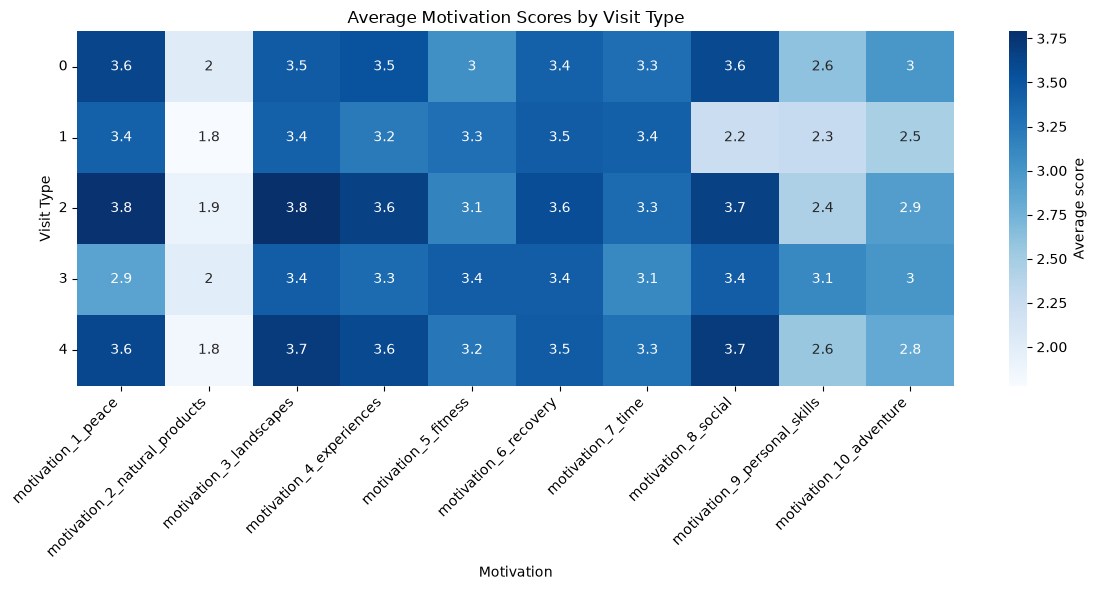

In [16]:
# Motivation columns
motivation_cols = [
    'motivation_1_peace',
    'motivation_2_natural_products',
    'motivation_3_landscapes',
    'motivation_4_experiences',
    'motivation_5_fitness',
    'motivation_6_recovery',
    'motivation_7_time',
    'motivation_8_social',
    'motivation_9_personal_skills',
    'motivation_10_adventure'
]

# Compute averaged values of motivations by visit type
motivation_avg = df.groupby('visit_type')[motivation_cols].mean().round(2)

plt.figure(figsize=(12, 6))
sns.heatmap(motivation_avg, annot=True, cmap='Blues', cbar_kws={'label': 'Average score'})
plt.title('Average Motivation Scores by Visit Type')
plt.xlabel('Motivation')
plt.ylabel('Visit Type')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Gender

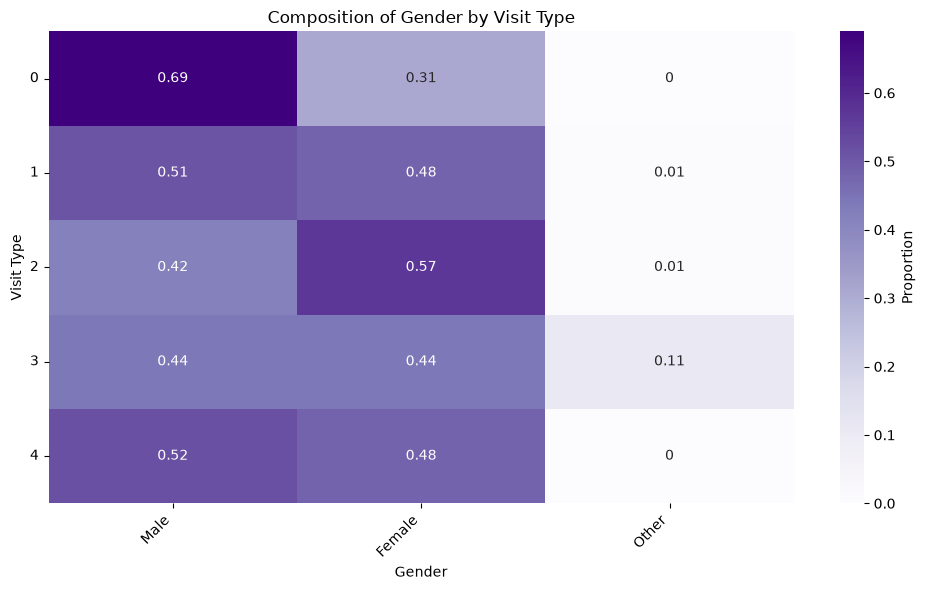

In [17]:
# Compute percent of each gender by visit type
gender_counts = df.groupby('visit_type')['gender'].value_counts().unstack(fill_value=0)
gender_pct = gender_counts.div(gender_counts.sum(axis=1), axis=0).round(2)
gender_pct = gender_pct[['Male', 'Female', 'Other']].fillna(0)
gender_pct

plt.figure(figsize=(10, 6))
sns.heatmap(gender_pct, annot=True, cmap='Purples', cbar_kws={'label': 'Proportion'})
plt.title('Composition of Gender by Visit Type')
plt.ylabel('Visit Type')
plt.xlabel('Gender')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Age

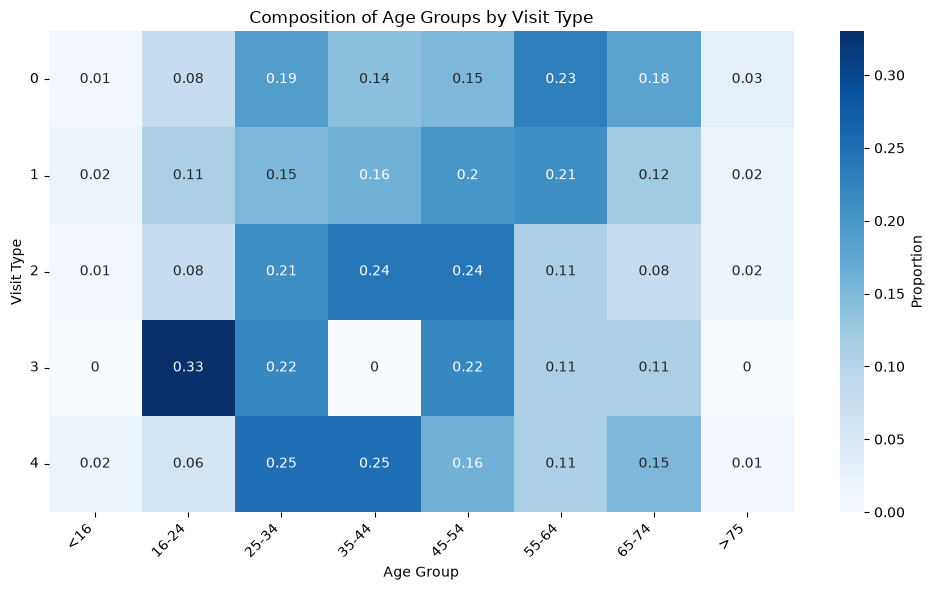

In [18]:
# Compute percent of each age group by visit type
age_counts = df.groupby('visit_type')['age'].value_counts().unstack(fill_value=0)
age_pct = age_counts.div(age_counts.sum(axis=1), axis=0).round(2)
age_pct = age_pct[['<16', '16-24', '25-34', '35-44', '45-54', '55-64', '65-74', '>75']].fillna(0)
age_pct

plt.figure(figsize=(10, 6))
sns.heatmap(age_pct, annot=True, cmap='Blues', cbar_kws={'label': 'Proportion'})
plt.title('Composition of Age Groups by Visit Type')
plt.ylabel('Visit Type')
plt.xlabel('Age Group')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Travel time

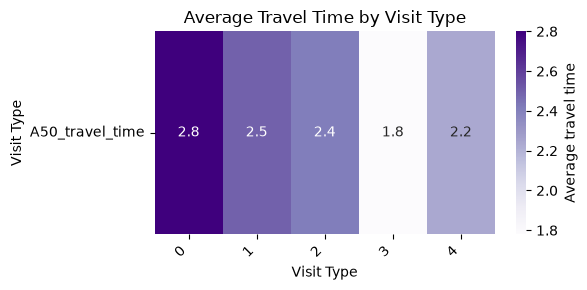

In [19]:
# Compute averaged values of travel time by visit type
travel_time_avg = df.groupby('visit_type')['A50_travel_time'].mean().round(2)

plt.figure(figsize=(6, 3))
sns.heatmap(travel_time_avg.to_frame().T, annot=True, cmap='Purples', cbar_kws={'label': 'Average travel time'})
plt.title('Average Travel Time by Visit Type')
plt.xlabel('Visit Type')
plt.ylabel('Visit Type')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Travel distance

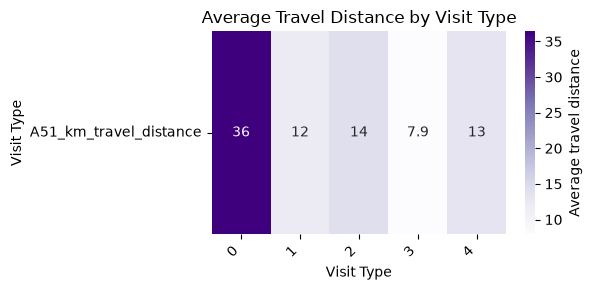

In [20]:
# Compute averaged values of travel distance by visit type
travel_distance_avg = df.groupby('visit_type')['A51_km_travel_distance'].mean().round(2)

plt.figure(figsize=(6, 3))
sns.heatmap(travel_distance_avg.to_frame().T, annot=True, cmap='Purples', cbar_kws={'label': 'Average travel distance'})
plt.title('Average Travel Distance by Visit Type')
plt.xlabel('Visit Type')
plt.ylabel('Visit Type')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Areas

In [21]:
destination_map = {
    1.0: 'Municipal outdoor recreation area or trail',
    2.0: 'State recreation or fishing area or trail',
    3.0: 'National park',
    4.0: 'Wilderness area',
    5.0: 'State nature reserve',
    6.0: 'Municipal nature reserve',
    7.0: 'Other nature reserve',
    8.0: 'Environment of own farm or forestry holding',
    9.0: 'Own recreational dwelling and its surroundings',
    10.0: 'Private forest, water area, etc.',
    11.0: 'State-owned forest, water area, etc.',
    12.0: 'Outdoor recreation area provided by a company or association',
    13.0: 'Rural tourism destination',
    14.0: "Don't know"
}

# Map destination codes to labels in a separate column; keep any unmapped codes as-is
df['area_destination_type'] = df['area_destination'].map(destination_map)
df['area_destination_type'] = df['area_destination_type'].fillna(df['area_destination'])
df['area_destination_type'].value_counts(dropna=False)

/tmp/xuleyi11/ipykernel_1312704/159871718.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['area_destination_type'] = df['area_destination'].map(destination_map)


area_destination_type
National park                                                   230
State recreation or fishing area or trail                        56
Don't know                                                       48
Wilderness area                                                  45
State nature reserve                                             29
State-owned forest, water area, etc.                             18
Municipal outdoor recreation area or trail                       13
Outdoor recreation area provided by a company or association      6
Private forest, water area, etc.                                  2
Municipal nature reserve                                          2
Rural tourism destination                                         1
Other nature reserve                                              1
Name: count, dtype: int64

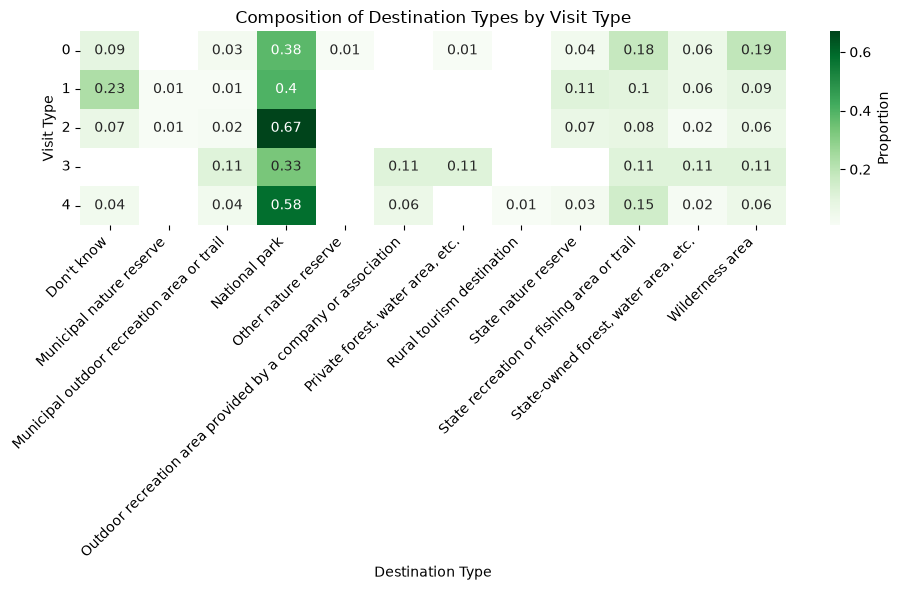

In [22]:
# Compute normalized composition of destination types by visit type
destination_profile = df.groupby('visit_type')['area_destination_type'].value_counts(normalize=True).unstack().round(2)

plt.figure(figsize=(10, 6))
sns.heatmap(destination_profile, annot=True, cmap='Greens', cbar_kws={'label': 'Proportion'})
plt.title('Composition of Destination Types by Visit Type')
plt.ylabel('Visit Type')
plt.xlabel('Destination Type')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

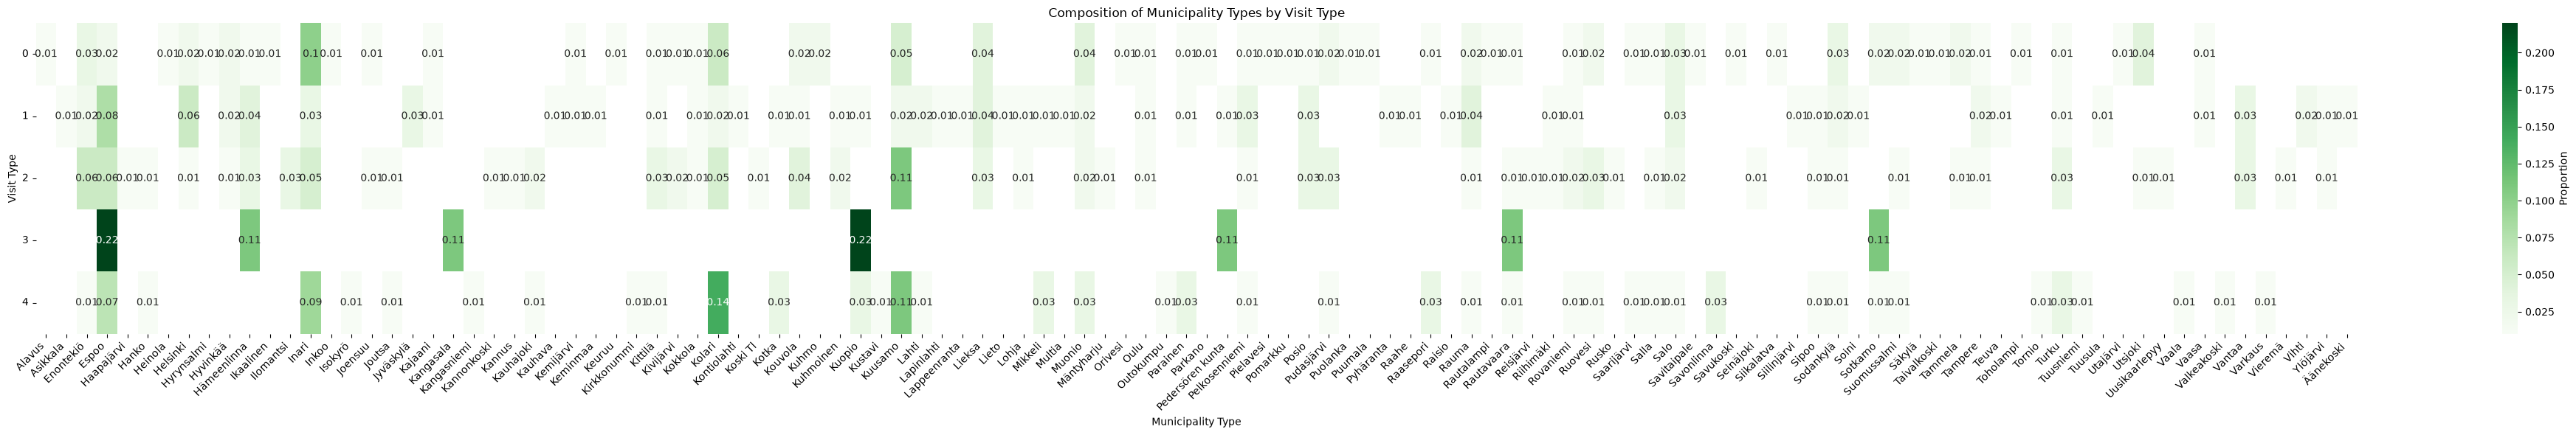

In [23]:
# Compute normalized composition of municipality by visit type
municipality_profile = df.groupby('visit_type')['area_municipality'].value_counts(normalize=True).unstack().round(2)

plt.figure(figsize=(40, 6))
sns.heatmap(municipality_profile, annot=True, cmap='Greens', cbar_kws={'label': 'Proportion'})
plt.title('Composition of Municipality Types by Visit Type')
plt.ylabel('Visit Type')
plt.xlabel('Municipality Type')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Opinions

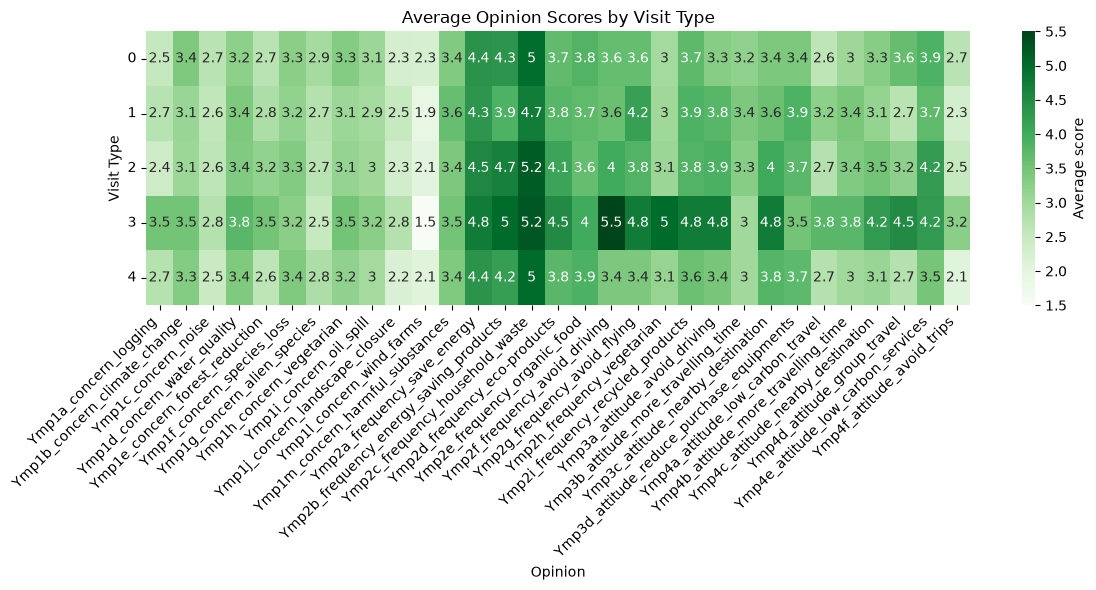

In [24]:
opinion_cols = [
    'Ymp1a_concern_logging',
    'Ymp1b_concern_climate_change',
    'Ymp1c_concern_noise',
    'Ymp1d_concern_water_quality',
    'Ymp1e_concern_forest_reduction',
    'Ymp1f_concern_species_loss',
    'Ymp1g_concern_alien_species',
    'Ymp1h_concern_vegetarian',
    'Ymp1i_concern_oil_spill',
    'Ymp1j_concern_landscape_closure',
    'Ymp1l_concern_wind_farms',
    'Ymp1m_concern_harmful_substances',
    'Ymp2a_frequency_save_energy',
    'Ymp2b_frequency_energy_saving_products',
    'Ymp2c_frequency_household_waste',
    'Ymp2d_frequency_eco-products',
    'Ymp2e_frequency_organic_food',
    'Ymp2f_frequency_avoid_driving',
    'Ymp2g_frequency_avoid_flying',
    'Ymp2h_frequency_vegetarian',
    'Ymp2i_frequency_recycled_products',
    'Ymp3a_attitude_avoid_driving',
    'Ymp3b_attitude_more_travelling_time',
    'Ymp3c_attitude_nearby_destination',
    'Ymp3d_attitude_reduce_purchase_equipments',
    'Ymp4a_attitude_low_carbon_travel',
    'Ymp4b_attitude_more_travelling_time',
    'Ymp4c_attitude_nearby_destination',
    'Ymp4d_attitude_group_travel',
    'Ymp4e_attitude_low_carbon_services',
    'Ymp4f_attitude_avoid_trips'
]

# Compute averaged values of opinions by visit type
opinion_avg = df.groupby('visit_type')[opinion_cols].mean().round(2)

plt.figure(figsize=(12, 6))
sns.heatmap(opinion_avg, annot=True, cmap='Greens', cbar_kws={'label': 'Average score'})
plt.title('Average Opinion Scores by Visit Type')
plt.xlabel('Opinion')
plt.ylabel('Visit Type')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Exploratory data analysis of NBT and OR datasets

*Note: the former pandas-profiling cells (`ProfileReport`) were dropped — the module is not installed in the kernel environment. The section-wise plots below serve the same profiling purpose.*

# Demographics

## Gender

In [25]:
# Frequency counts by gender label (daytrip vs. multiday trip visitors)
gender_counts_or = df_or['gender'].value_counts(dropna=True)
gender_counts_nbt = df_nbt['gender'].value_counts(dropna=True)
df_gender = pd.DataFrame({'Daytrip': gender_counts_or, 'Multiday_trip': gender_counts_nbt}).fillna(0).astype(int)
df_gender

,Daytrip,Multiday_trip
gender,,
Female,63,145
Male,101,139
Other,1,2


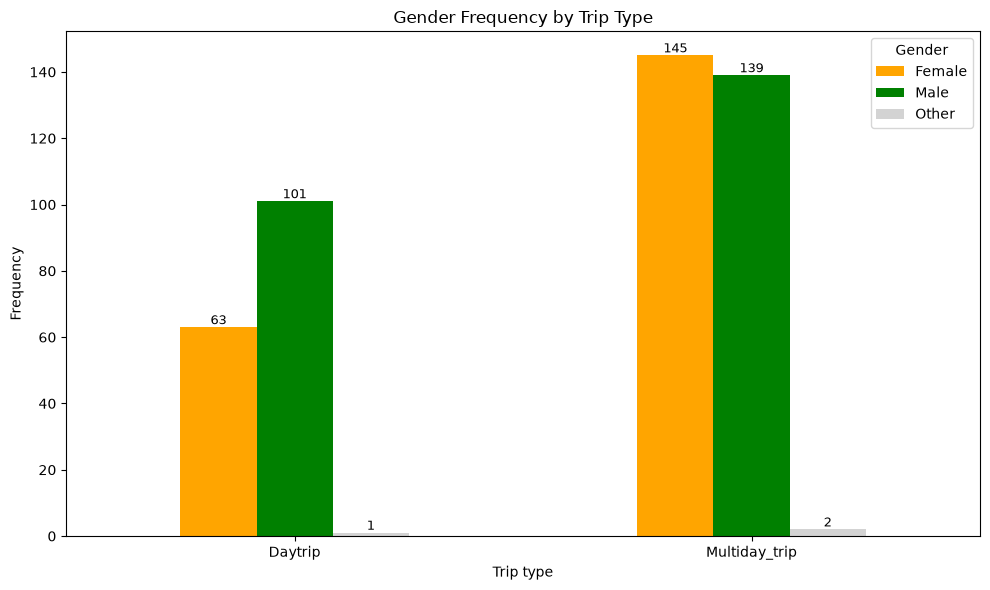

In [26]:
# Transpose so trip type is on x-axis and gender is legend
df_plot = df_gender.T

colors = ['orange', 'green', 'lightgrey']

ax = df_plot.plot(
    kind='bar',
    figsize=(10, 6),
    color=colors
)

ax.set_xlabel('Trip type')
ax.set_ylabel('Frequency')
ax.set_title('Gender Frequency by Trip Type')
ax.legend(title='Gender')

plt.xticks(rotation=0)

# Optional: annotate bar values
for p in ax.patches:
    ax.annotate(
        int(p.get_height()),
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()
plt.show()

## Age group

In [27]:
age_order = ['<16', '16-24', '25-34', '35-44', '45-54', '55-64', '65-74', '>75']

age_counts_or = df_or['age'].value_counts(dropna=True).reindex(age_order)
age_counts_nbt = df_nbt['age'].value_counts(dropna=True).reindex(age_order)
df_age = pd.DataFrame({'Daytrip': age_counts_or, 'Multiday_trip': age_counts_nbt}).fillna(0).astype(int)
df_age

,Daytrip,Multiday_trip
age,,
<16,1,5
16-24,19,20
25-34,27,63
35-44,31,56
45-54,24,61
55-64,32,43
65-74,25,34
>75,6,4


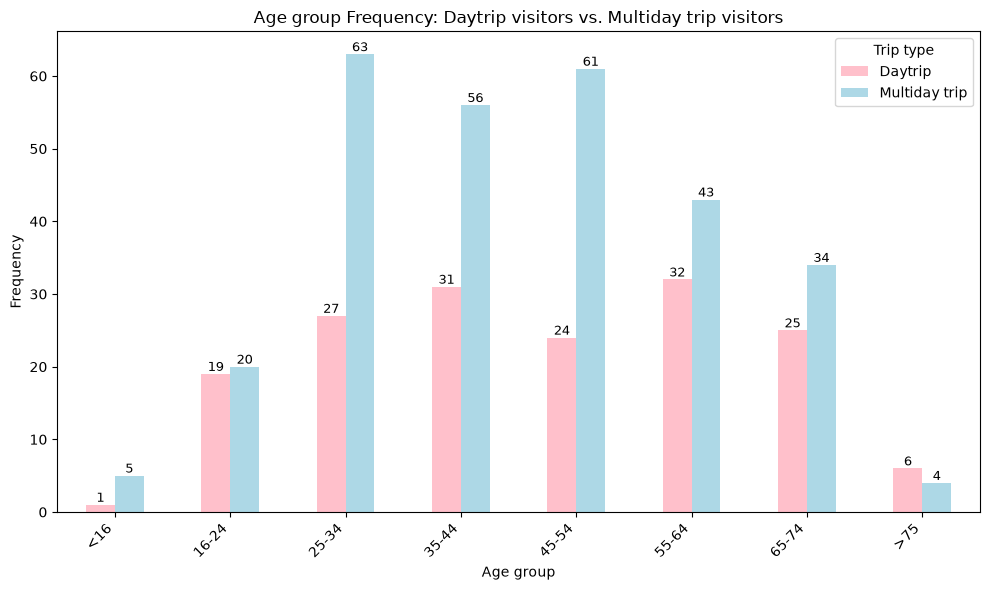

In [28]:
# Plot age group frequencies for daytrips and multiday trips side-by-side
colors = ['pink', 'lightblue']
ax = df_age.plot(kind='bar', figsize=(10, 6), color=colors)
ax.set_xlabel('Age group')
ax.set_ylabel('Frequency')
ax.set_title('Age group Frequency: Daytrip visitors vs. Multiday trip visitors')
ax.legend(['Daytrip', 'Multiday trip'], title='Trip type')
plt.xticks(rotation=45, ha='right')

# optional: annotate bar values
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Activities

## Activities

In [29]:
# Get the frequency counts for activities
act_counts_or = df_or.activity.value_counts(dropna=True).sort_index()
act_counts_nbt = df_nbt.activity.value_counts(dropna=True).sort_index()

df_act = pd.DataFrame({'Daytrip': act_counts_or, 'Multiday_trip': act_counts_nbt}).fillna(0).astype(int)
df_act = df_act.sort_values(by=['Daytrip', 'Multiday_trip'], ascending=False)
df_act

,Daytrip,Multiday_trip
activity,,
Walking,74,145
Dog walking,17,8
Cycling,14,3
Skiing,10,30
Running,8,4
Hunting,6,6
Fishing,5,18
Picnicking,4,7
Orienteering,4,2


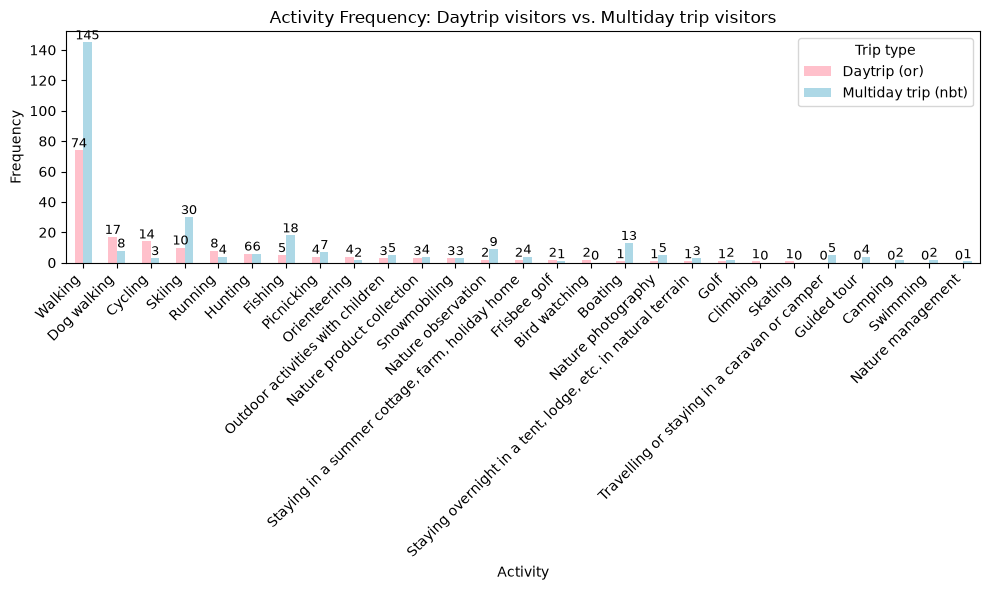

In [30]:
# Plot activity frequencies for daytrips and multiday trips side-by-side
colors = ['pink', 'lightblue']
ax = df_act.plot(kind='bar', figsize=(10, 6), color=colors)
ax.set_xlabel('Activity')
ax.set_ylabel('Frequency')
ax.set_title('Activity Frequency: Daytrip visitors vs. Multiday trip visitors')
ax.legend(['Daytrip (or)', 'Multiday trip (nbt)'], title='Trip type')
plt.xticks(rotation=45, ha='right')

# optional: annotate bar values
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [31]:
# Frequency counts for activities across the full dataset
act_counts = df.activity.value_counts(dropna=True).sort_index()
print(act_counts)
act_counts

activity
Bird watching                                                    2
Boating                                                         14
Camping                                                          2
Climbing                                                         1
Cycling                                                         17
Dog walking                                                     25
Fishing                                                         23
Frisbee golf                                                     3
Golf                                                             3
Guided tour                                                      4
Hunting                                                         12
Nature management                                                1
Nature observation                                              11
Nature photography                                               6
Nature product collection                            

activity
Bird watching                                                    2
Boating                                                         14
Camping                                                          2
Climbing                                                         1
Cycling                                                         17
Dog walking                                                     25
Fishing                                                         23
Frisbee golf                                                     3
Golf                                                             3
Guided tour                                                      4
Hunting                                                         12
Nature management                                                1
Nature observation                                              11
Nature photography                                               6
Nature product collection                            

## Sub-activities

In [32]:
# Get the frequency counts for sub_activities
sub_act_counts_or = df_or.sub_activity.value_counts(dropna=True).sort_index()
sub_act_counts_nbt = df_nbt.sub_activity.value_counts(dropna=True).sort_index()

df_sub_act = pd.DataFrame({'Daytrip': sub_act_counts_or, 'Multiday_trip': sub_act_counts_nbt}).fillna(0).astype(int)

df_sub_act = df_sub_act.sort_values(by=['Daytrip', 'Multiday_trip'], ascending=False)
df_sub_act

,Daytrip,Multiday_trip
sub_activity,,
Walking,53,50
Hiking,17,91
Dog walking,17,8
Cycling,14,0
Cross-country skiing,8,23
Jogging,7,2
Bird hunting,5,4
Trolling,4,11
Nordic walking,4,4


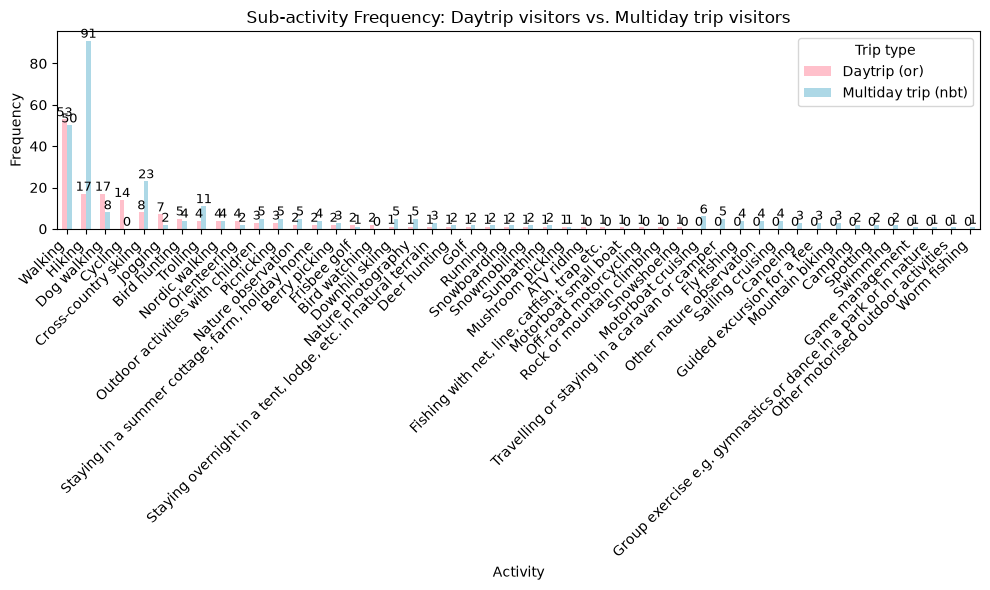

In [33]:
# Plot sub-activity frequencies for daytrips and multiday trips side-by-side
colors = ['pink', 'lightblue']
ax = df_sub_act.plot(kind='bar', figsize=(10, 6), color=colors)
ax.set_xlabel('Activity')
ax.set_ylabel('Frequency')
ax.set_title('Sub-activity Frequency: Daytrip visitors vs. Multiday trip visitors')
ax.legend(['Daytrip (or)', 'Multiday trip (nbt)'], title='Trip type')
plt.xticks(rotation=45, ha='right')

# optional: annotate bar values
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Hobbies

In [34]:
# Get the frequency counts for hobbies
hobby_counts_or = df_or.hobby.value_counts(dropna=True).sort_index()
hobby_counts_nbt = df_nbt.hobby.value_counts(dropna=True).sort_index()

df_hobby = pd.DataFrame({'Daytrip': hobby_counts_or, 'Multiday_trip': hobby_counts_nbt}).fillna(0).astype(int)

df_hobby = df_hobby.sort_values(by=['Daytrip', 'Multiday_trip'], ascending=False)
df_hobby

,Daytrip,Multiday_trip
hobby,,
Other activities,56,67
Walking,53,50
Outdoor activities with dogs,17,8
Cycling,14,0
Cross-country skiing,8,23
Running,7,0
Nordic walking,4,0
Outdoor activities with children,3,5
Nature product collection,3,4


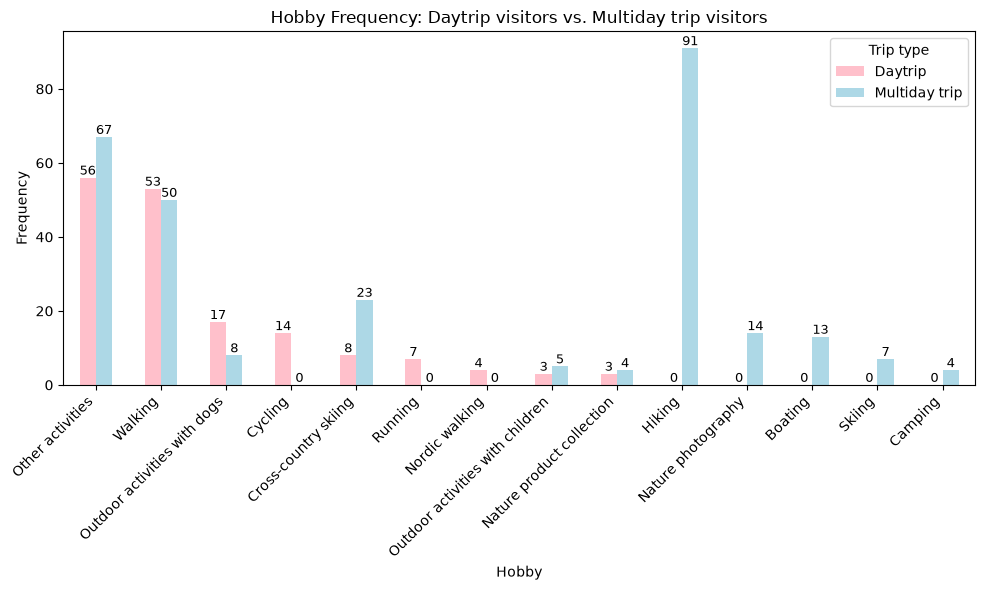

In [35]:
# Plot hobby frequencies for daytrips and multiday trips side-by-side
colors = ['pink', 'lightblue']
ax = df_hobby.plot(kind='bar', figsize=(10, 6), color=colors)
ax.set_xlabel('Hobby')
ax.set_ylabel('Frequency')
ax.set_title('Hobby Frequency: Daytrip visitors vs. Multiday trip visitors')
ax.legend(['Daytrip', 'Multiday trip'], title='Trip type')
plt.xticks(rotation=45, ha='right')

# optional: annotate bar values
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Motivations

## Daytrip visitors

Motivation patterns

In [36]:
motivation_col = ['motivation_1_peace', 'motivation_2_natural_products', 'motivation_3_landscapes',
                  'motivation_4_experiences', 'motivation_5_fitness', 'motivation_6_recovery',
                  'motivation_7_time', 'motivation_8_social', 'motivation_9_personal_skills',
                  'motivation_10_adventure']


def explore_motivation(df, motivation_col):
    # Rename numeric values for readability
    mapping = {
        1: "Not at all important",
        2: "Somewhat important",
        3: "Fairly important",
        4: "Very important",
        5: "Don't know"
    }

    df_m = df[motivation_col].apply(lambda s: s.map(mapping))

    # Count responses per category
    counts = df_m.apply(lambda x: x.value_counts()).fillna(0)

    # Reorder categories
    order = ["Not at all important", "Somewhat important", "Fairly important", "Very important", "Don't know"]
    counts = counts.reindex(order).fillna(0)

    # Define a color palette
    colors = ["#d73027", "#fc8d59", "#fee08b", "#1a9850", "#bdbdbd"]

    # Plot
    ax = counts.T.plot(kind="barh", stacked=True, figsize=(10, 8), color=colors)

    plt.xlabel("Number of respondents")
    plt.ylabel("Motivation")
    plt.title("Motivation Importance (Stacked Likert Visualization)")

    # Legend outside the plot
    plt.legend(
        title="Response",
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        ncol=3
    )

    plt.tight_layout()
    plt.show()

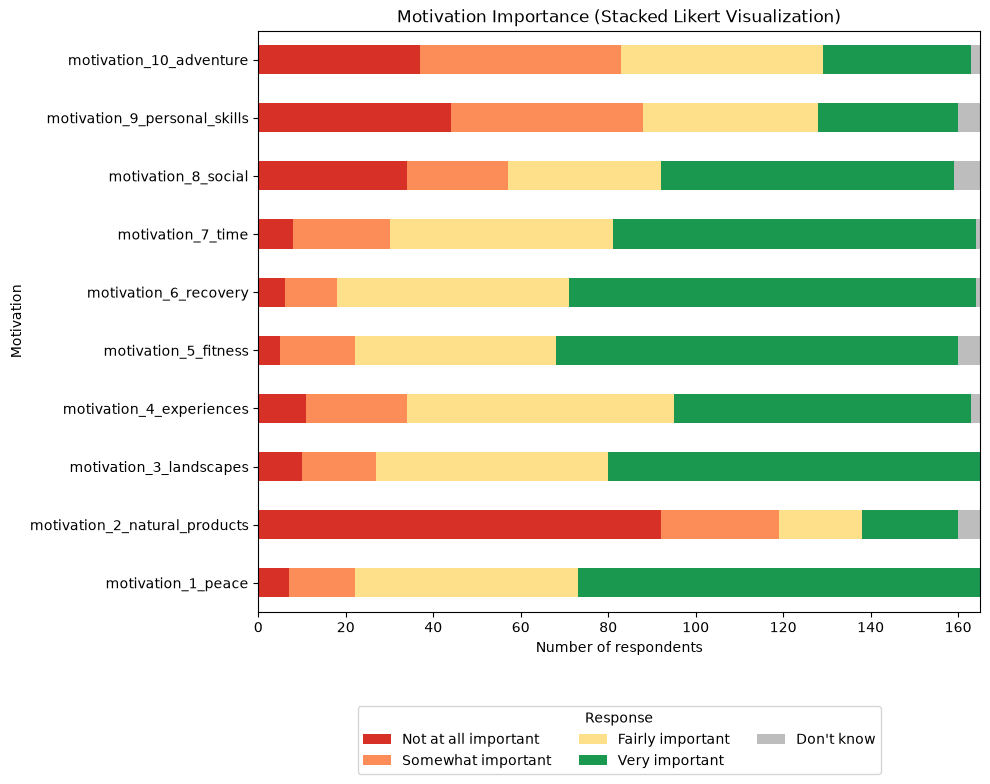

In [37]:
explore_motivation(df_or, motivation_col)

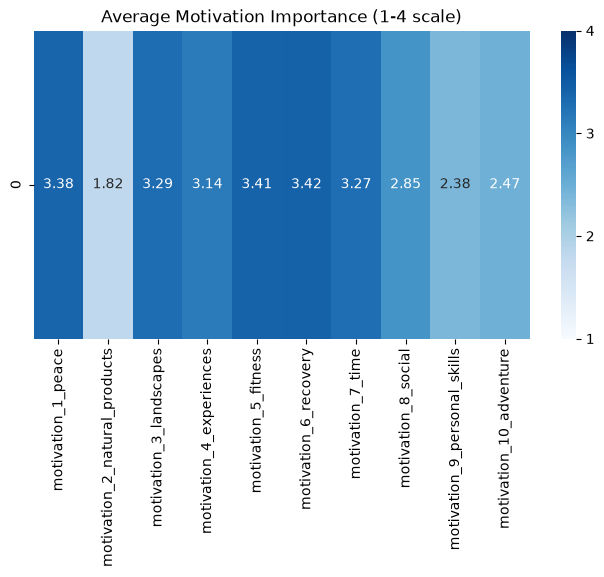

In [38]:
df_clean = df_or[motivation_col].replace(5, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8, 4))
ax = sns.heatmap(
    avg.to_frame().T,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=1,
    vmax=4,
    cbar_kws={'ticks': [1, 2, 3, 4]}
)
plt.title("Average Motivation Importance (1-4 scale)")
plt.show()

Visitor clustering based on motivations

In [39]:
# Replace 5 with NaN for motivation columns
df_or_motivation = df_or[motivation_col].replace(5, np.nan)

# Impute with column mean
df_or_motivation = df_or_motivation.fillna(df_or_motivation.mean())

In [40]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_or = scaler.fit_transform(df_or_motivation)

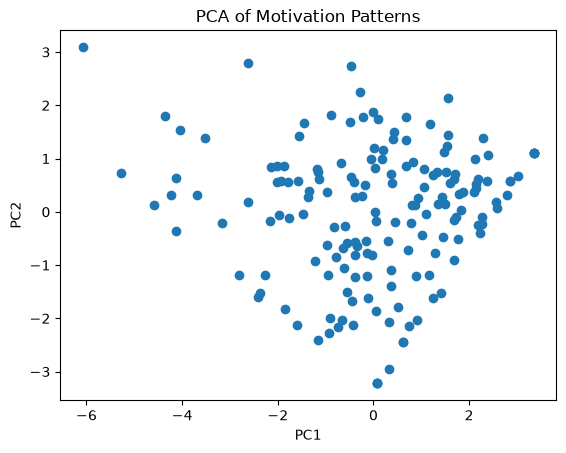

In [41]:
# PCA on motivations
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
coords = pca.fit_transform(X_or)

plt.scatter(coords[:, 0], coords[:, 1])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Motivation Patterns")
plt.show()

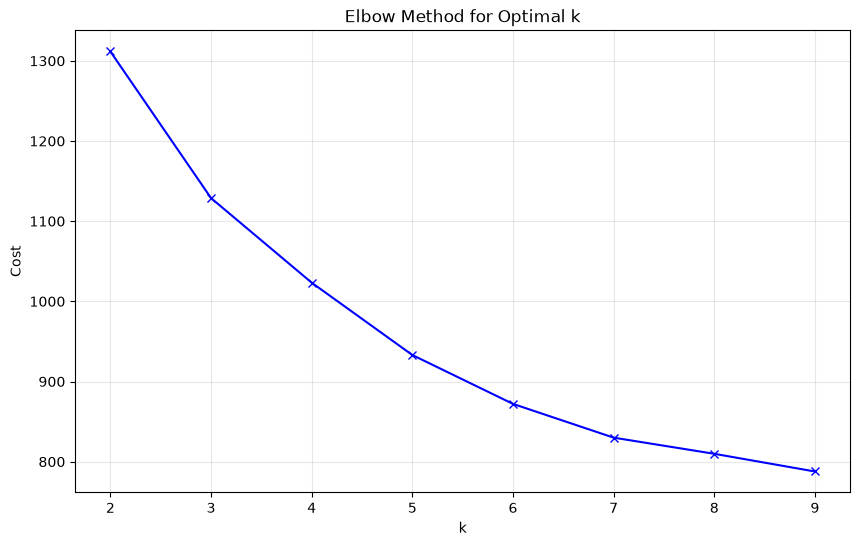

In [42]:
from sklearn.cluster import KMeans
# Find optimal number of clusters using elbow method
cost = []
k_range = range(2, 10)

for k in k_range:
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(X_or)
    cost.append(model.inertia_)

# Plot elbow curve
plt.figure(figsize=(10, 6))
plt.plot(k_range, cost, 'bx-')
plt.xlabel('k')
plt.ylabel('Cost')
plt.title('Elbow Method for Optimal k')
plt.grid(True, alpha=0.3)
plt.show()

In [43]:
# Apply KMeans clustering with chosen k
k = 4
model = KMeans(n_clusters=k, random_state=42)
clusters = model.fit_predict(X_or)

# Add cluster labels to the original dataframe
df_or["motivation_cluster"] = clusters

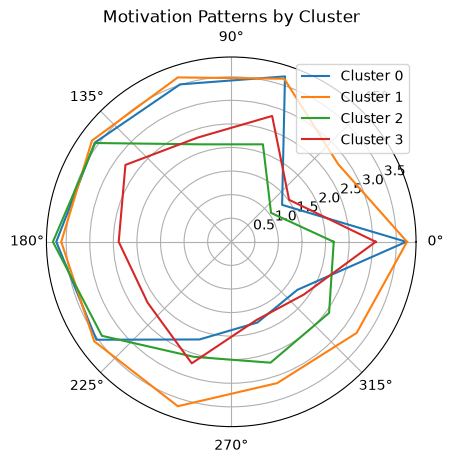

In [44]:
cluster_means = df_or.groupby("motivation_cluster")[motivation_col].mean()

# Radar plot
labels = motivation_col
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False)

for cluster in cluster_means.index:
    stats = cluster_means.loc[cluster].tolist()
    stats += stats[:1]  # close loop
    ang = np.concatenate((angles, [angles[0]]))

    plt.polar(ang, stats, label=f"Cluster {cluster}")

plt.legend()
plt.title("Motivation Patterns by Cluster")
plt.show()

## Multiday trip visitors

Motivation patterns

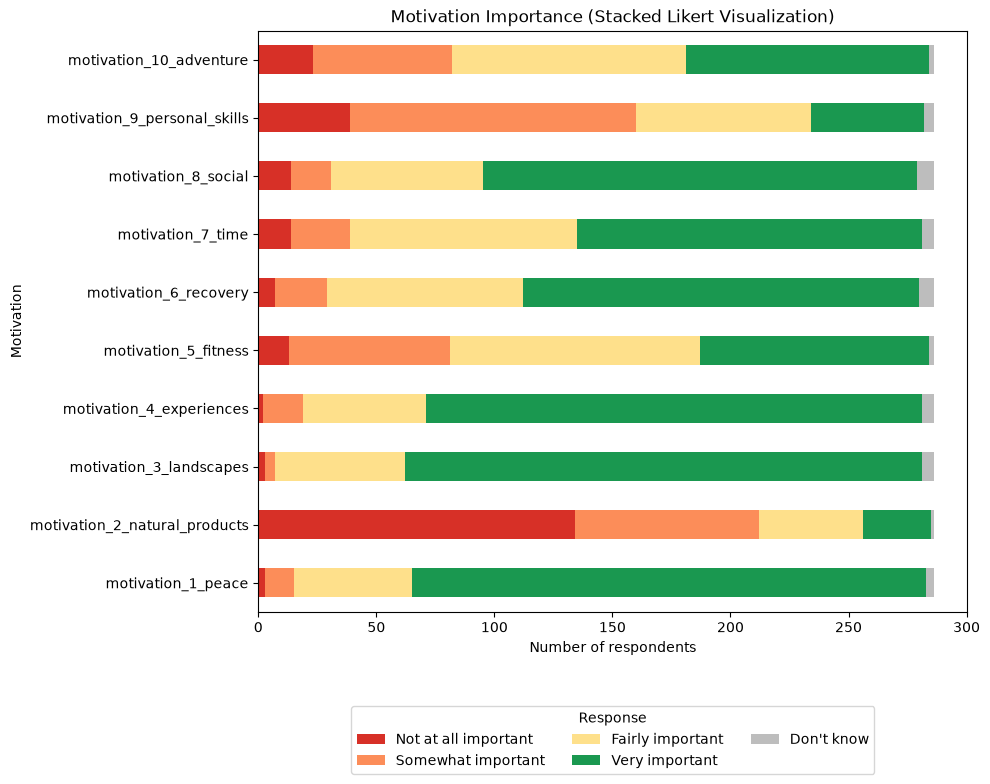

In [45]:
explore_motivation(df_nbt, motivation_col)

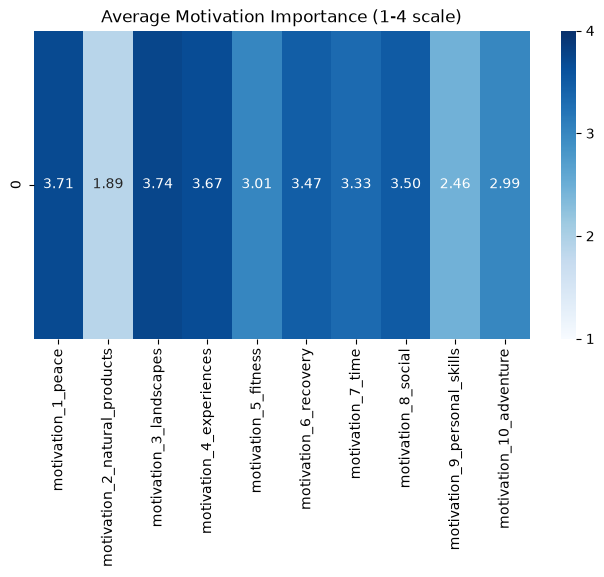

In [46]:
df_clean = df_nbt[motivation_col].replace(5, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8, 4))
ax = sns.heatmap(
    avg.to_frame().T,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=1,
    vmax=4,
    cbar_kws={'ticks': [1, 2, 3, 4]}
)
plt.title("Average Motivation Importance (1-4 scale)")
plt.show()

Visitor clustering based on motivations

In [47]:
# Replace 5 with NaN for motivation columns
df_nbt_motivation = df_nbt[motivation_col].replace(5, np.nan)

# Impute with column mean
df_nbt_motivation = df_nbt_motivation.fillna(df_nbt_motivation.mean())

In [48]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_nbt = scaler.fit_transform(df_nbt_motivation)

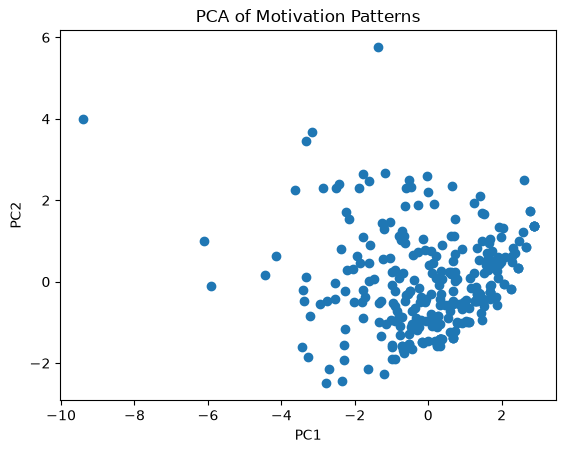

In [49]:
# PCA on motivation data
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
coords = pca.fit_transform(X_nbt)

plt.scatter(coords[:, 0], coords[:, 1])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Motivation Patterns")
plt.show()

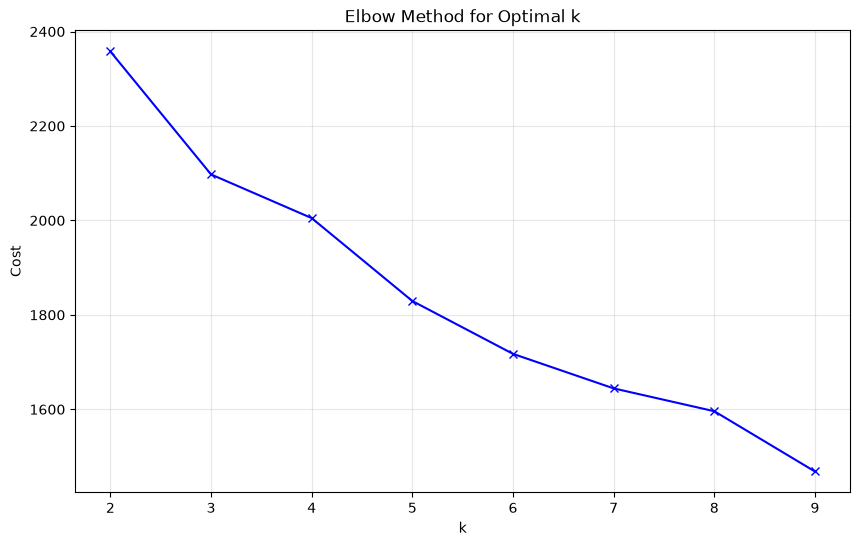

In [50]:
from sklearn.cluster import KMeans
# Find optimal number of clusters using elbow method
cost = []
k_range = range(2, 10)

for k in k_range:
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(X_nbt)
    cost.append(model.inertia_)

# Plot elbow curve
plt.figure(figsize=(10, 6))
plt.plot(k_range, cost, 'bx-')
plt.xlabel('k')
plt.ylabel('Cost')
plt.title('Elbow Method for Optimal k')
plt.grid(True, alpha=0.3)
plt.show()

In [51]:
# Apply KMeans clustering with chosen k
k = 4
model = KMeans(n_clusters=k, random_state=42)
clusters = model.fit_predict(X_nbt)

# Add cluster labels to the original dataframe
df_nbt["motivation_cluster"] = clusters

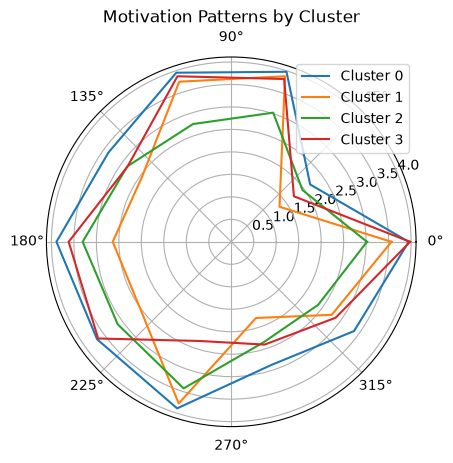

In [52]:
cluster_means = df_nbt.groupby("motivation_cluster")[motivation_col].mean()

# Radar plot
labels = motivation_col
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False)

for cluster in cluster_means.index:
    stats = cluster_means.loc[cluster].tolist()
    stats += stats[:1]  # close loop
    ang = np.concatenate((angles, [angles[0]]))

    plt.polar(ang, stats, label=f"Cluster {cluster}")

plt.legend()
plt.title("Motivation Patterns by Cluster")
plt.show()

## All visitors

Motivation patterns

In [53]:
df_motivation = df[motivation_col]
df_motivation

,motivation_1_peace,motivation_2_natural_products,motivation_3_landscapes,motivation_4_experiences,motivation_5_fitness,motivation_6_recovery,motivation_7_time,motivation_8_social,motivation_9_personal_skills,motivation_10_adventure
0,4.0,1.0,4.0,3.0,4.0,4.0,4.0,4.0,4.0,4.0
1,4.0,2.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0
2,2.0,1.0,3.0,3.0,2.0,4.0,4.0,2.0,4.0,4.0
3,3.0,2.0,3.0,2.0,4.0,4.0,3.0,4.0,4.0,3.0
4,3.0,1.0,2.0,1.0,4.0,4.0,4.0,4.0,4.0,4.0
...,...,...,...,...,...,...,...,...,...,...
446,4.0,1.0,4.0,4.0,3.0,4.0,3.0,4.0,2.0,3.0
447,4.0,1.0,4.0,4.0,3.0,3.0,3.0,3.0,2.0,4.0
448,4.0,1.0,4.0,3.0,2.0,4.0,2.0,4.0,3.0,3.0
449,4.0,1.0,4.0,4.0,3.0,4.0,3.0,4.0,2.0,3.0


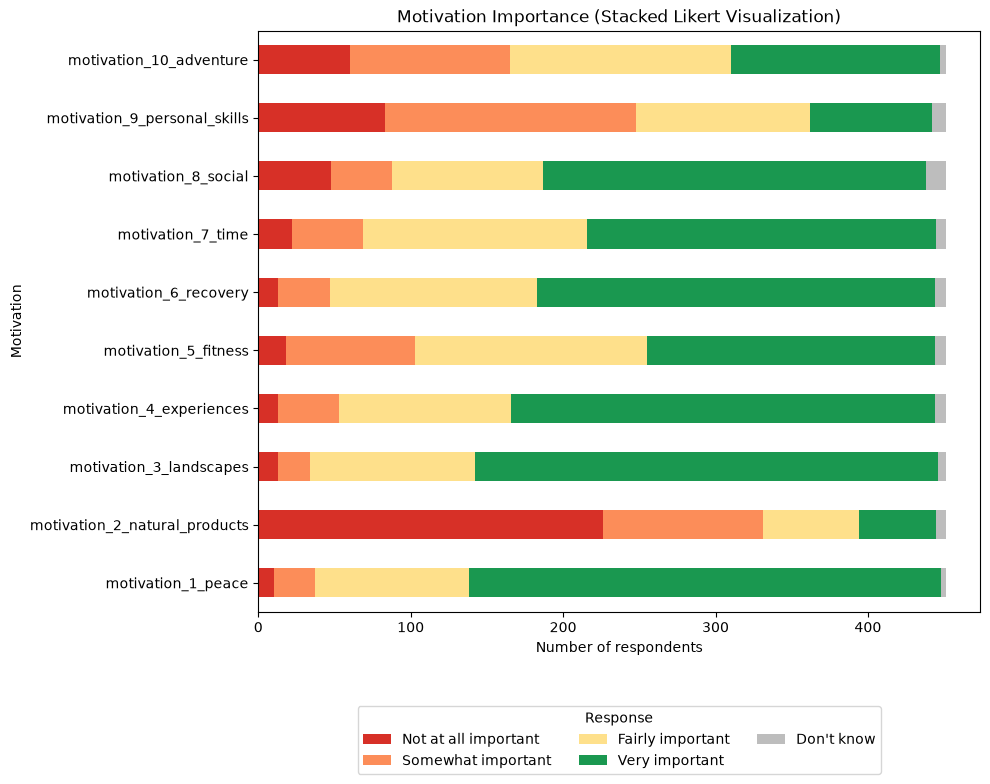

In [54]:
explore_motivation(df, motivation_col)

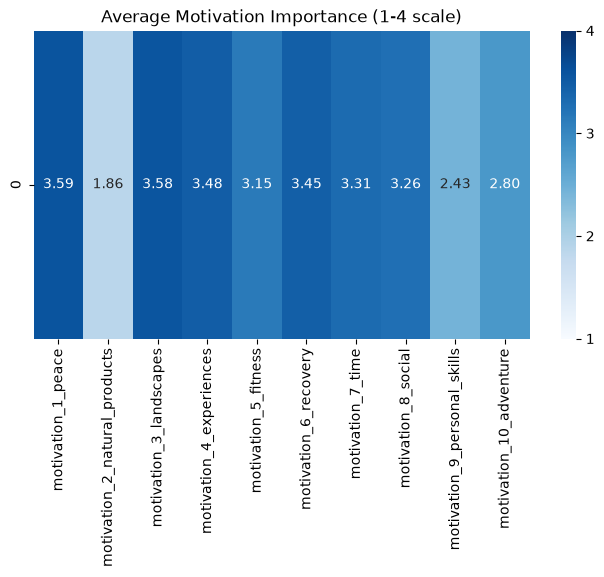

In [55]:
df_clean = df_motivation.replace(5, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8, 4))
ax = sns.heatmap(
    avg.to_frame().T,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=1,
    vmax=4,
    cbar_kws={'ticks': [1, 2, 3, 4]}
)
plt.title("Average Motivation Importance (1-4 scale)")
plt.show()

Visitor clustering based on motivations

In [56]:
# Replace 5 with NaN for motivation columns
df_motivation_clean = df_motivation.replace(5, np.nan)

# Impute with column mean
df_motivation_clean = df_motivation_clean.fillna(df_motivation_clean.mean())

In [57]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_all = scaler.fit_transform(df_motivation_clean)

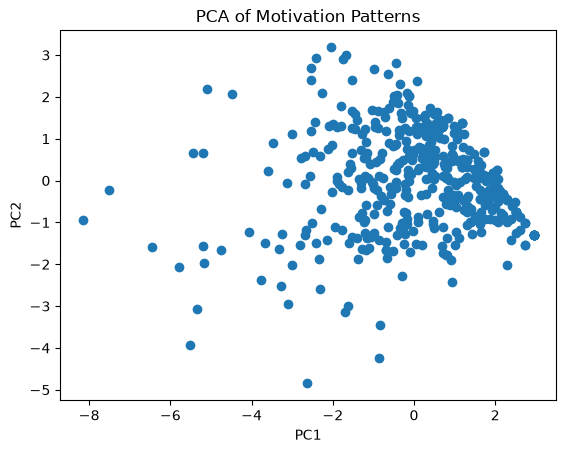

In [58]:
# PCA on motivation data
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
coords = pca.fit_transform(X_all)

plt.scatter(coords[:, 0], coords[:, 1])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Motivation Patterns")
plt.show()

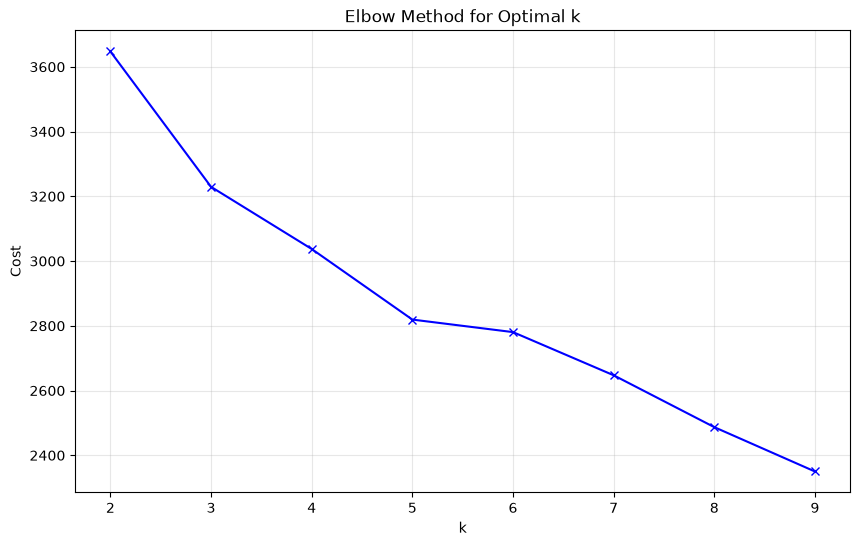

In [59]:
from sklearn.cluster import KMeans
# Find optimal number of clusters using elbow method
cost = []
k_range = range(2, 10)

for k in k_range:
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(X_all)
    cost.append(model.inertia_)

# Plot elbow curve
plt.figure(figsize=(10, 6))
plt.plot(k_range, cost, 'bx-')
plt.xlabel('k')
plt.ylabel('Cost')
plt.title('Elbow Method for Optimal k')
plt.grid(True, alpha=0.3)
plt.show()

In [60]:
# Apply KMeans clustering with chosen k
k = 5
model = KMeans(n_clusters=k, random_state=42)
clusters = model.fit_predict(X_all)

# Add cluster labels to the original dataframe
df_motivation["motivation_cluster"] = clusters

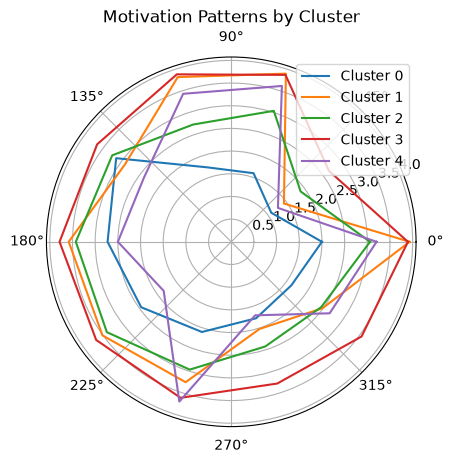

In [61]:
cluster_means = df_motivation.groupby("motivation_cluster")[motivation_col].mean()

# Radar plot
labels = motivation_col
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False)

for cluster in cluster_means.index:
    stats = cluster_means.loc[cluster].tolist()
    stats += stats[:1]  # close loop
    ang = np.concatenate((angles, [angles[0]]))

    plt.polar(ang, stats, label=f"Cluster {cluster}")

plt.legend()
plt.title("Motivation Patterns by Cluster")
plt.show()

# Activities across areas

The area splits use `area_destination` destination-type codes (2 = state recreation/fishing area, 3 = national park, 4 = wilderness area, 5 = state nature reserve, 11 = state-owned forest/water area).

## Daytrip visitors

Activities across areas

In [62]:
# Analyze activities based on area type
df_or_state_recreation = df_or[df_or['area_destination'] == 2]
df_or_state_nature_reserve = df_or[df_or['area_destination'] == 5]
df_or_wilderness_area = df_or[df_or['area_destination'] == 4]
df_or_national_park = df_or[df_or['area_destination'] == 3]
df_or_state_forest = df_or[df_or['area_destination'] == 11]

print(f'State recreation area count: {df_or_state_recreation.shape[0]}')
print(f'State nature reserve count: {df_or_state_nature_reserve.shape[0]}')
print(f'Wilderness area count: {df_or_wilderness_area.shape[0]}')
print(f'National park count: {df_or_national_park.shape[0]}')
print(f'State forest count: {df_or_state_forest.shape[0]}')

# Get the frequency counts for activities
act_counts_or_state_recreation = df_or_state_recreation['activity'].value_counts(dropna=True).sort_index()
act_counts_or_nature_reserve = df_or_state_nature_reserve['activity'].value_counts(dropna=True).sort_index()
act_counts_or_wilderness_area = df_or_wilderness_area['activity'].value_counts(dropna=True).sort_index()
act_counts_or_national_park = df_or_national_park['activity'].value_counts(dropna=True).sort_index()
act_counts_or_state_forest = df_or_state_forest['activity'].value_counts(dropna=True).sort_index()
df_or_act = pd.DataFrame({'state_recreation': act_counts_or_state_recreation, 'state_nature_reserve': act_counts_or_nature_reserve,
                          'wilderness_area': act_counts_or_wilderness_area,
                          'national_park': act_counts_or_national_park, 'state_forest': act_counts_or_state_forest}).fillna(0).astype(int)

df_or_act = df_or_act[df_or_act.index.notnull()]
df_or_act

State recreation area count: 18
State nature reserve count: 21
Wilderness area count: 14
National park count: 59
State forest count: 11


,state_recreation,state_nature_reserve,wilderness_area,national_park,state_forest
activity,,,,,
Bird watching,0,1,0,0,1
Boating,0,0,0,1,0
Cycling,0,1,0,5,2
Dog walking,1,5,0,3,1
Fishing,3,0,1,0,1
Frisbee golf,1,0,0,0,0
Hunting,0,0,2,0,1
Nature observation,0,1,0,0,1
Nature photography,0,0,1,0,0


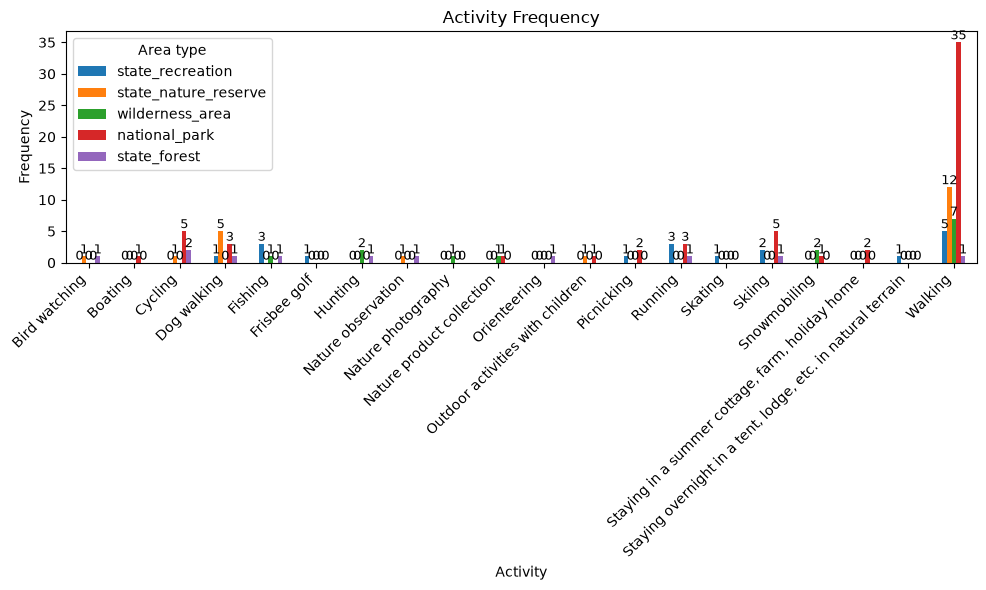

In [63]:
# Plot activity frequencies across area types
ax = df_or_act.plot(kind='bar', figsize=(10, 6))
ax.set_xlabel('Activity')
ax.set_ylabel('Frequency')
ax.set_title('Activity Frequency')
ax.legend(title='Area type')
plt.xticks(rotation=45, ha='right')

# optional: annotate bar values
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## Multiday trip visitors

Activities across areas

In [64]:
# Analyze activities based on area type
df_nbt_state_recreation = df_nbt[df_nbt['area_destination'] == 2]
df_nbt_state_nature_reserve = df_nbt[df_nbt['area_destination'] == 5]
df_nbt_wilderness_area = df_nbt[df_nbt['area_destination'] == 4]
df_nbt_national_park = df_nbt[df_nbt['area_destination'] == 3]
df_nbt_state_forest = df_nbt[df_nbt['area_destination'] == 11]

print(f'State recreation area count: {df_nbt_state_recreation.shape[0]}')
print(f'State nature reserve count: {df_nbt_state_nature_reserve.shape[0]}')
print(f'Wilderness area count: {df_nbt_wilderness_area.shape[0]}')
print(f'National park count: {df_nbt_national_park.shape[0]}')
print(f'State forest count: {df_nbt_state_forest.shape[0]}')

# Get the frequency counts for activities
act_counts_nbt_state_recreation = df_nbt_state_recreation['activity'].value_counts(dropna=True).sort_index()
act_counts_nbt_nature_reserve = df_nbt_state_nature_reserve['activity'].value_counts(dropna=True).sort_index()
act_counts_nbt_wilderness_area = df_nbt_wilderness_area['activity'].value_counts(dropna=True).sort_index()
act_counts_nbt_national_park = df_nbt_national_park['activity'].value_counts(dropna=True).sort_index()
act_counts_nbt_state_forest = df_nbt_state_forest['activity'].value_counts(dropna=True).sort_index()

df_nbt_act = pd.DataFrame({'state_recreation': act_counts_nbt_state_recreation, 'state_nature_reserve': act_counts_nbt_nature_reserve,
                           'wilderness_area': act_counts_nbt_wilderness_area,
                           'national_park': act_counts_nbt_national_park, 'state_forest': act_counts_nbt_state_forest}).fillna(0).astype(int)

df_nbt_act = df_nbt_act[df_nbt_act.index.notnull()]
df_nbt_act

State recreation area count: 38
State nature reserve count: 8
Wilderness area count: 31
National park count: 171
State forest count: 7


,state_recreation,state_nature_reserve,wilderness_area,national_park,state_forest
activity,,,,,
Boating,4,1,1,5,0
Camping,0,0,0,1,0
Cycling,0,0,0,1,0
Dog walking,2,0,1,3,0
Fishing,8,0,6,1,3
Frisbee golf,0,0,0,0,1
Golf,0,0,0,1,0
Guided tour,0,0,1,3,0
Hunting,2,0,3,0,1


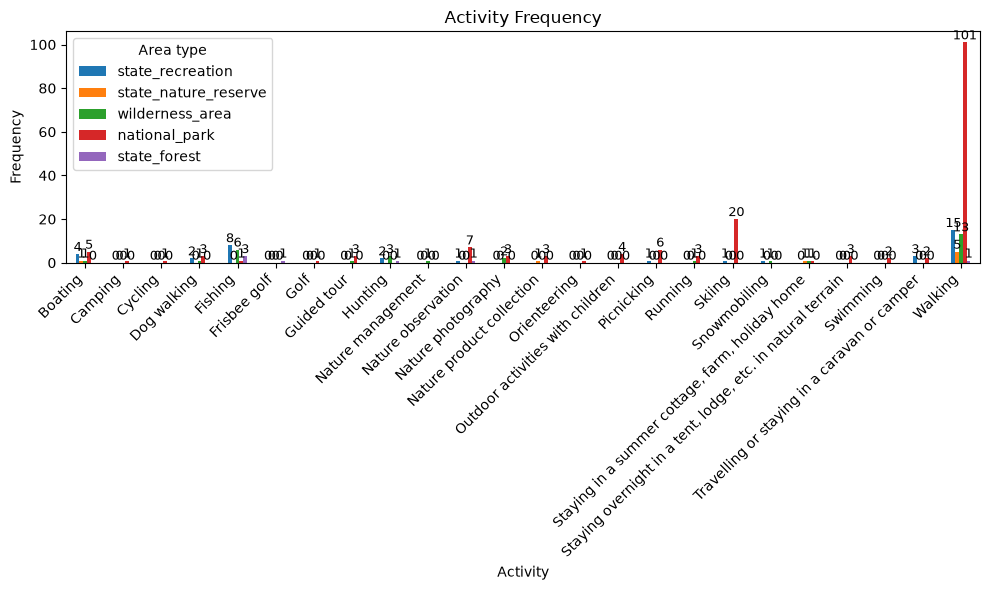

In [65]:
# Plot activity frequencies across area types
ax = df_nbt_act.plot(kind='bar', figsize=(10, 6))
ax.set_xlabel('Activity')
ax.set_ylabel('Frequency')
ax.set_title('Activity Frequency')
ax.legend(title='Area type')
plt.xticks(rotation=45, ha='right')

# optional: annotate bar values
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## All visitors

In [66]:
# Analyze activities based on area type
df_state_recreation = df[df['area_destination'] == 2]
df_state_nature_reserve = df[df['area_destination'] == 5]
df_wilderness_area = df[df['area_destination'] == 4]
df_national_park = df[df['area_destination'] == 3]
df_state_forest = df[df['area_destination'] == 11]

print(f'State recreation area count: {df_state_recreation.shape[0]}')
print(f'State nature reserve count: {df_state_nature_reserve.shape[0]}')
print(f'Wilderness area count: {df_wilderness_area.shape[0]}')
print(f'National park count: {df_national_park.shape[0]}')
print(f'State forest count: {df_state_forest.shape[0]}')

# Get the frequency counts for activities
act_counts_state_recreation = df_state_recreation['activity'].value_counts(dropna=True).sort_index()
act_counts_state_nature_reserve = df_state_nature_reserve['activity'].value_counts(dropna=True).sort_index()
act_counts_wilderness_area = df_wilderness_area['activity'].value_counts(dropna=True).sort_index()
act_counts_national_park = df_national_park['activity'].value_counts(dropna=True).sort_index()
act_counts_state_forest = df_state_forest['activity'].value_counts(dropna=True).sort_index()
df_act_areas = pd.DataFrame({'state_recreation': act_counts_state_recreation, 'state_nature_reserve': act_counts_state_nature_reserve,
                             'wilderness_area': act_counts_wilderness_area,
                             'national_park': act_counts_national_park, 'state_forest': act_counts_state_forest}).fillna(0).astype(int)

df_act_areas = df_act_areas[df_act_areas.index.notnull()]
df_act_areas

State recreation area count: 56
State nature reserve count: 29
Wilderness area count: 45
National park count: 230
State forest count: 18


,state_recreation,state_nature_reserve,wilderness_area,national_park,state_forest
activity,,,,,
Bird watching,0,1,0,0,1
Boating,4,1,1,6,0
Camping,0,0,0,1,0
Cycling,0,1,0,6,2
Dog walking,3,5,1,6,1
Fishing,11,0,7,1,4
Frisbee golf,1,0,0,0,1
Golf,0,0,0,1,0
Guided tour,0,0,1,3,0


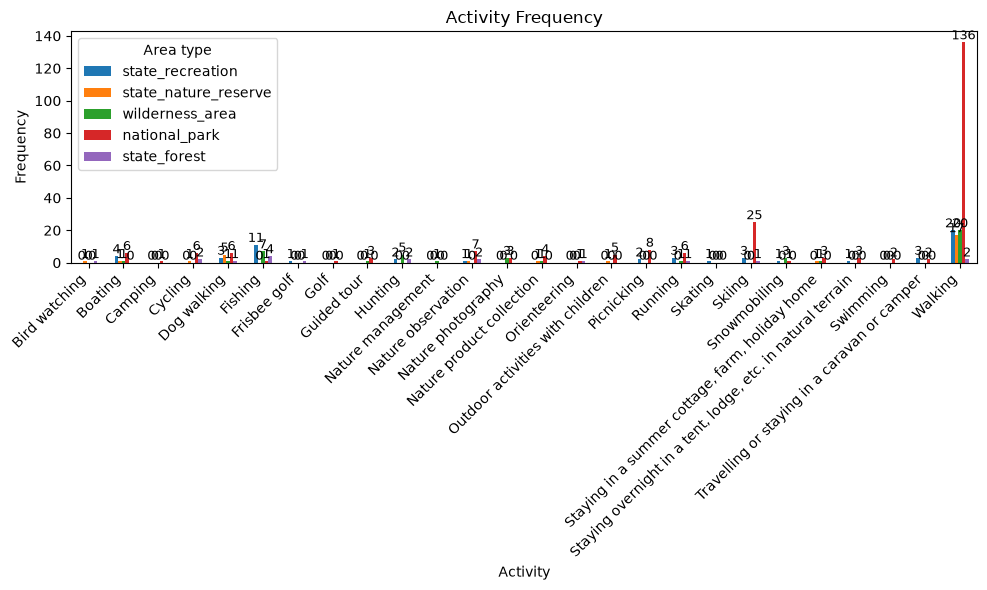

In [67]:
# Plot activity frequencies across area types
ax = df_act_areas.plot(kind='bar', figsize=(10, 6))
ax.set_xlabel('Activity')
ax.set_ylabel('Frequency')
ax.set_title('Activity Frequency')
ax.legend(title='Area type')
plt.xticks(rotation=45, ha='right')

# optional: annotate bar values
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Motivations across areas

## Daytrip visitors

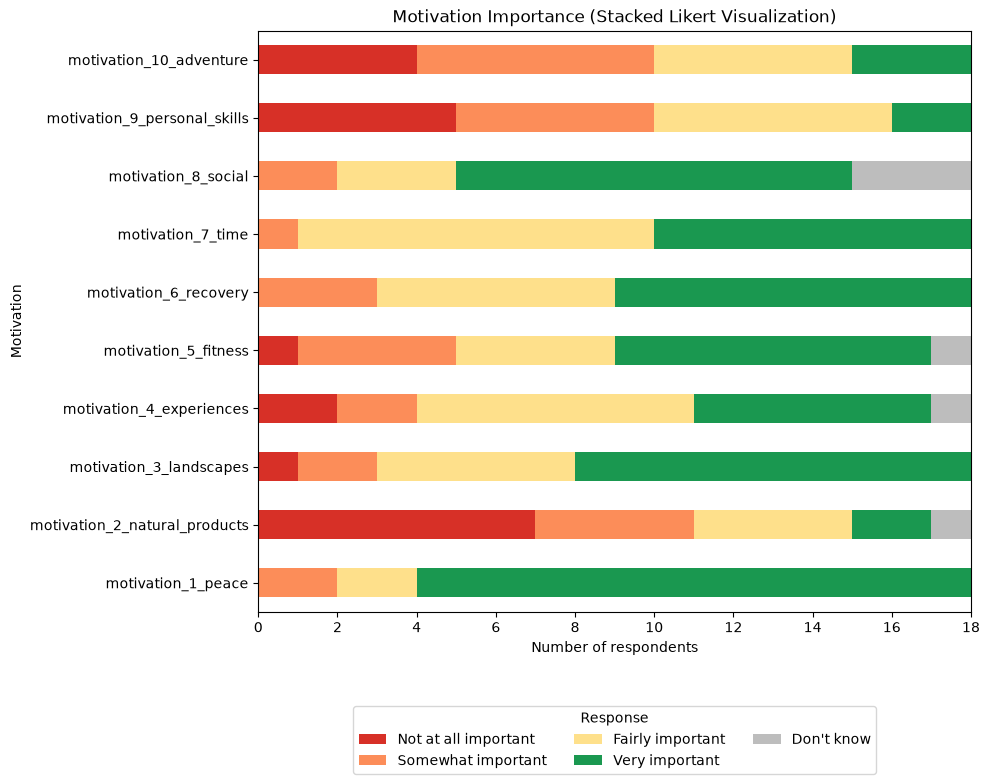

In [68]:
explore_motivation(df_or_state_recreation, motivation_col)

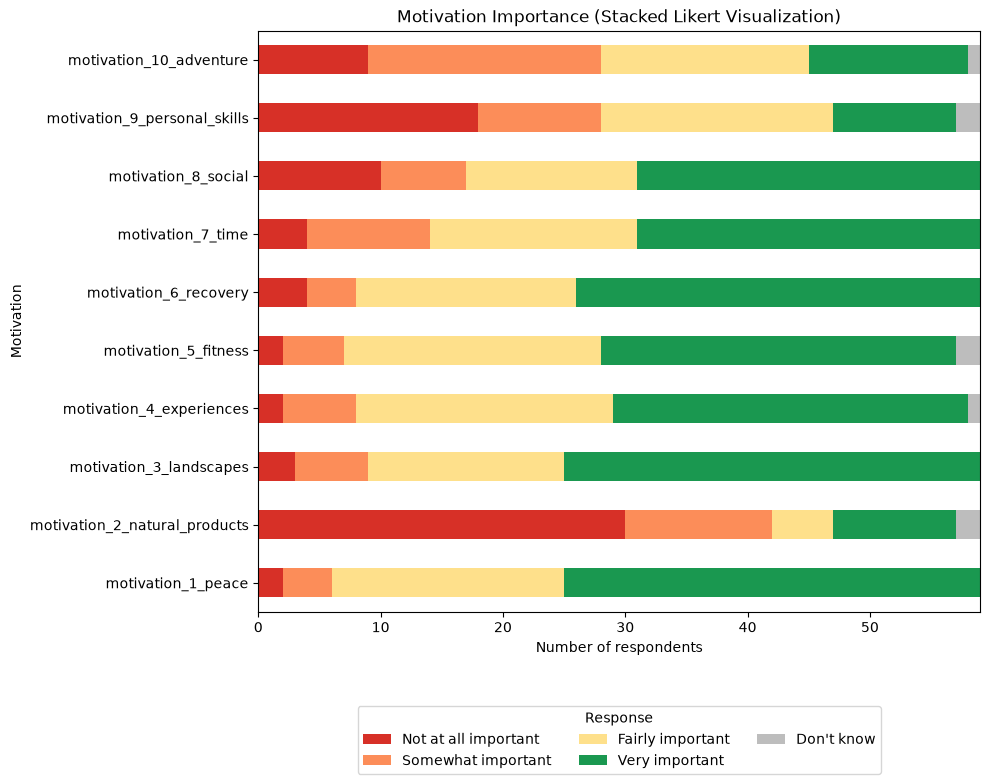

In [69]:
explore_motivation(df_or_national_park, motivation_col)

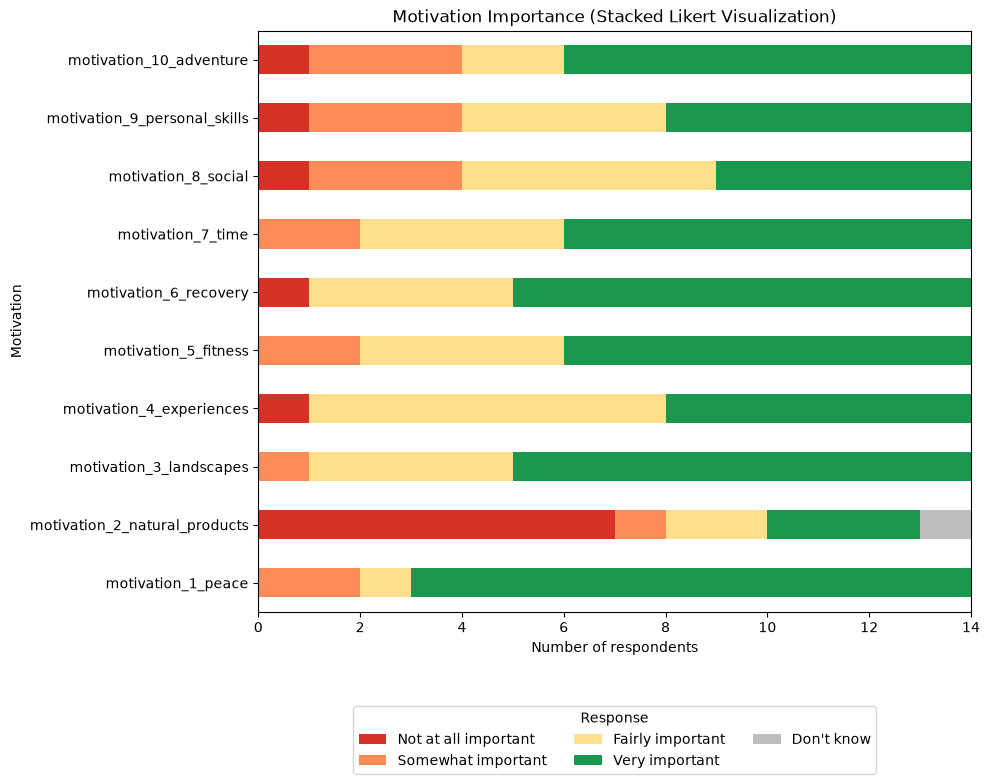

In [70]:
explore_motivation(df_or_wilderness_area, motivation_col)

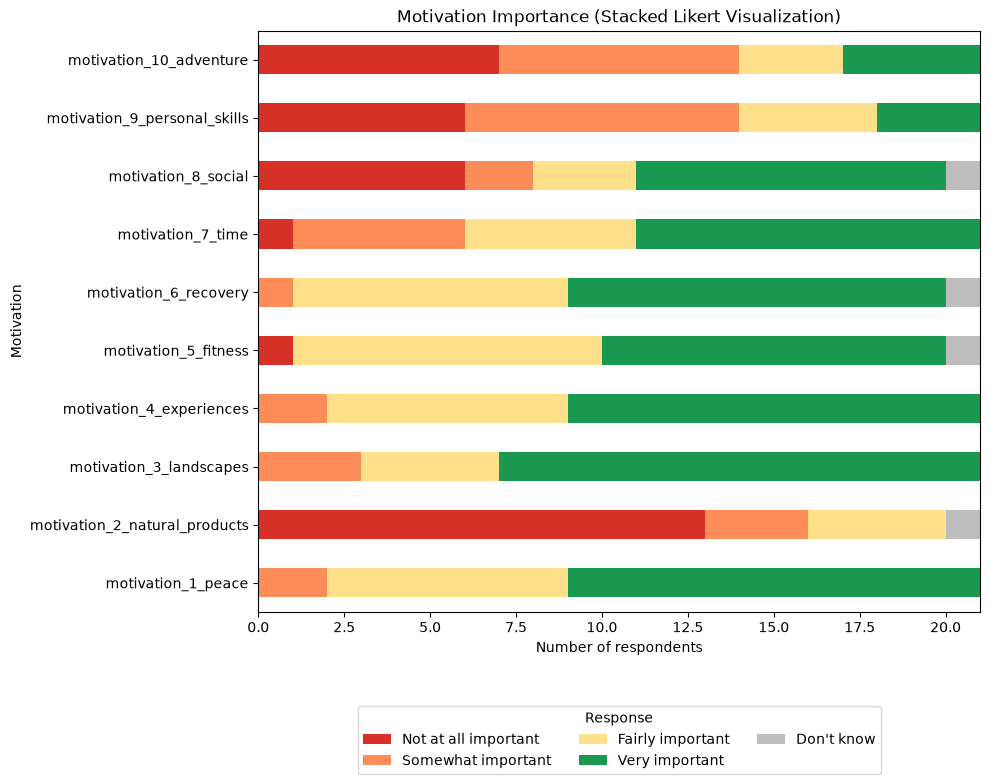

In [71]:
explore_motivation(df_or_state_nature_reserve, motivation_col)

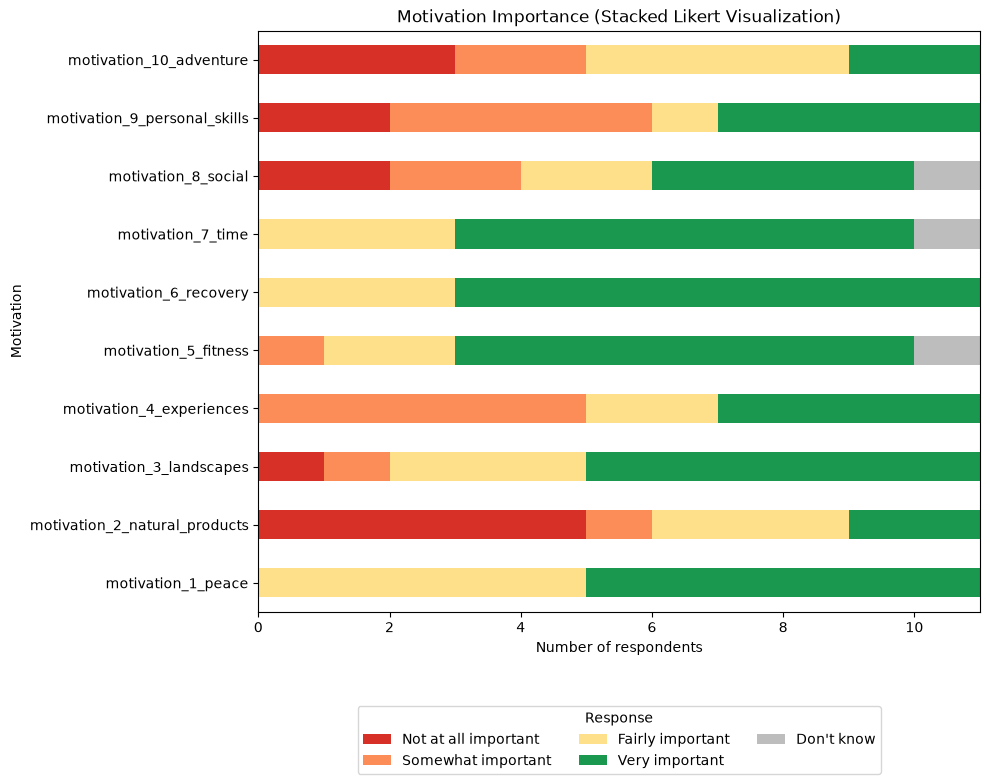

In [72]:
explore_motivation(df_or_state_forest, motivation_col)

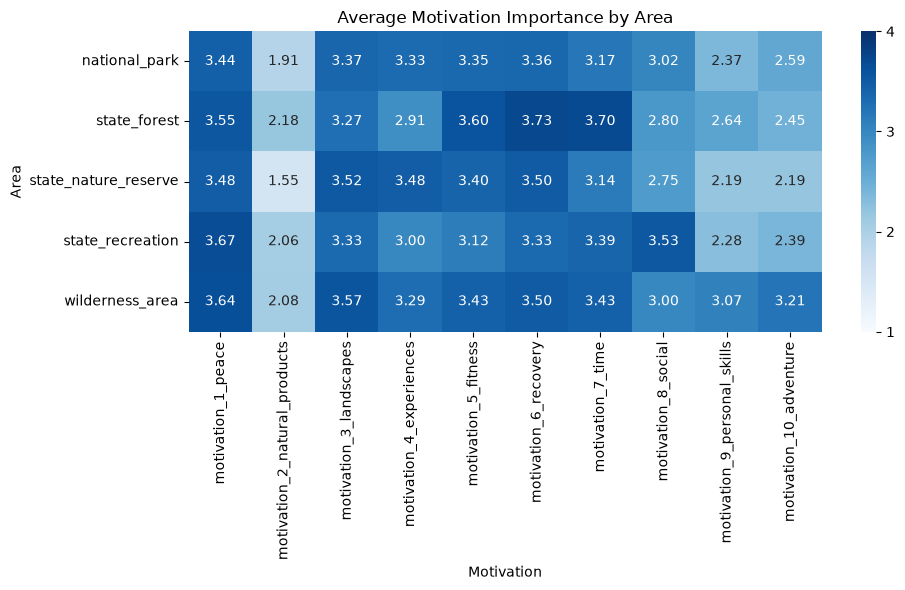

In [73]:
df_or_area_motivation = pd.concat([
    df_or_state_recreation[motivation_col].assign(area='state_recreation'),
    df_or_state_nature_reserve[motivation_col].assign(area='state_nature_reserve'),
    df_or_wilderness_area[motivation_col].assign(area='wilderness_area'),
    df_or_national_park[motivation_col].assign(area='national_park'),
    df_or_state_forest[motivation_col].assign(area='state_forest'),
], ignore_index=True)

# Clean motivation values
df_clean = df_or_area_motivation.copy()
df_clean[motivation_col] = (
    df_clean[motivation_col]
    .replace(5, np.nan)
    .apply(pd.to_numeric, errors='coerce')
)

# Average motivation by area (already a DataFrame)
avg_by_area = df_clean.groupby('area')[motivation_col].mean()

# Plot heatmap
plt.figure(figsize=(10, 6))

ax = sns.heatmap(
    avg_by_area,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=1,
    vmax=4,
    cbar_kws={'ticks': [1, 2, 3, 4]}
)

plt.title("Average Motivation Importance by Area")
plt.xlabel("Motivation")
plt.ylabel("Area")
plt.tight_layout()
plt.show()

## Multiday trip visitors

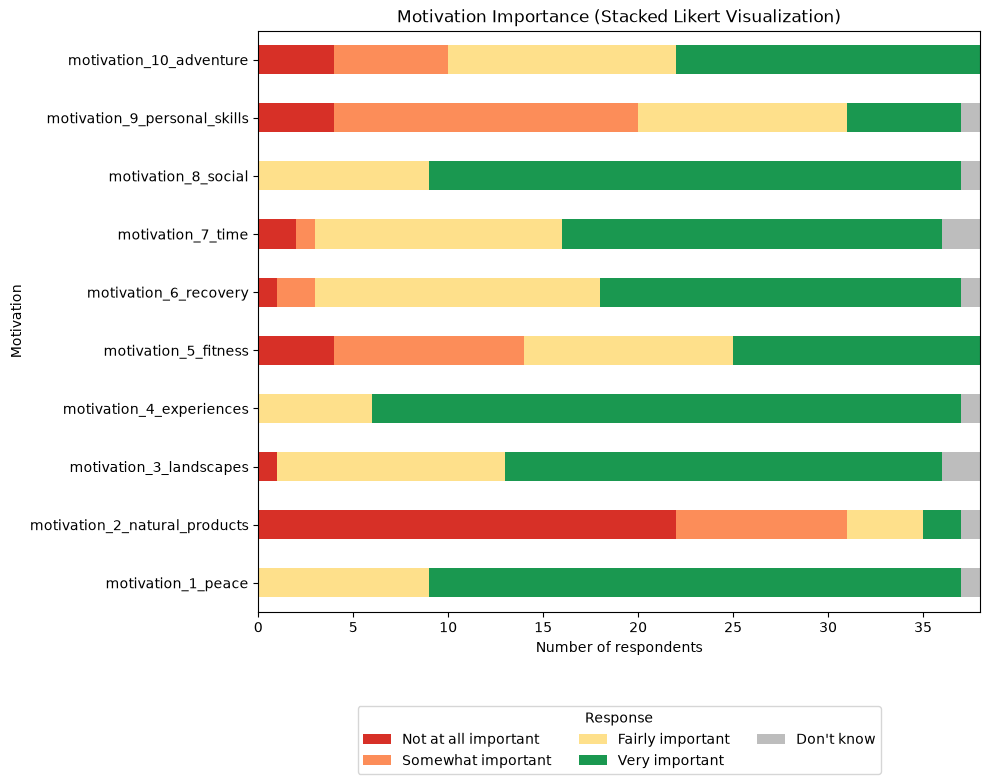

In [74]:
explore_motivation(df_nbt_state_recreation, motivation_col)

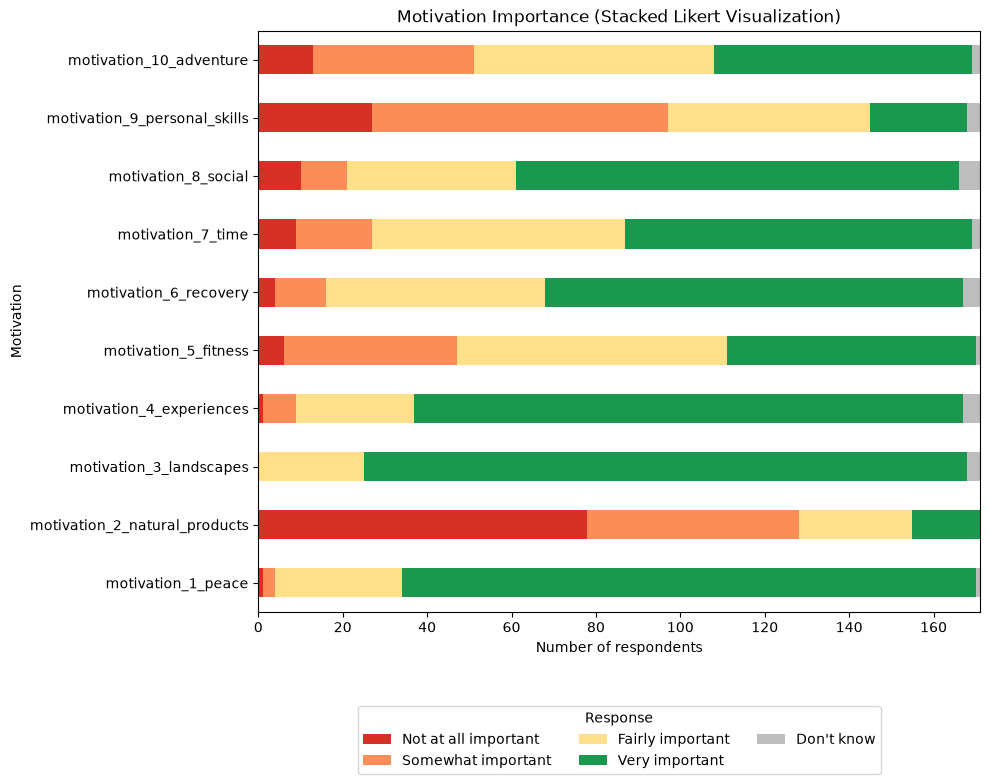

In [75]:
explore_motivation(df_nbt_national_park, motivation_col)

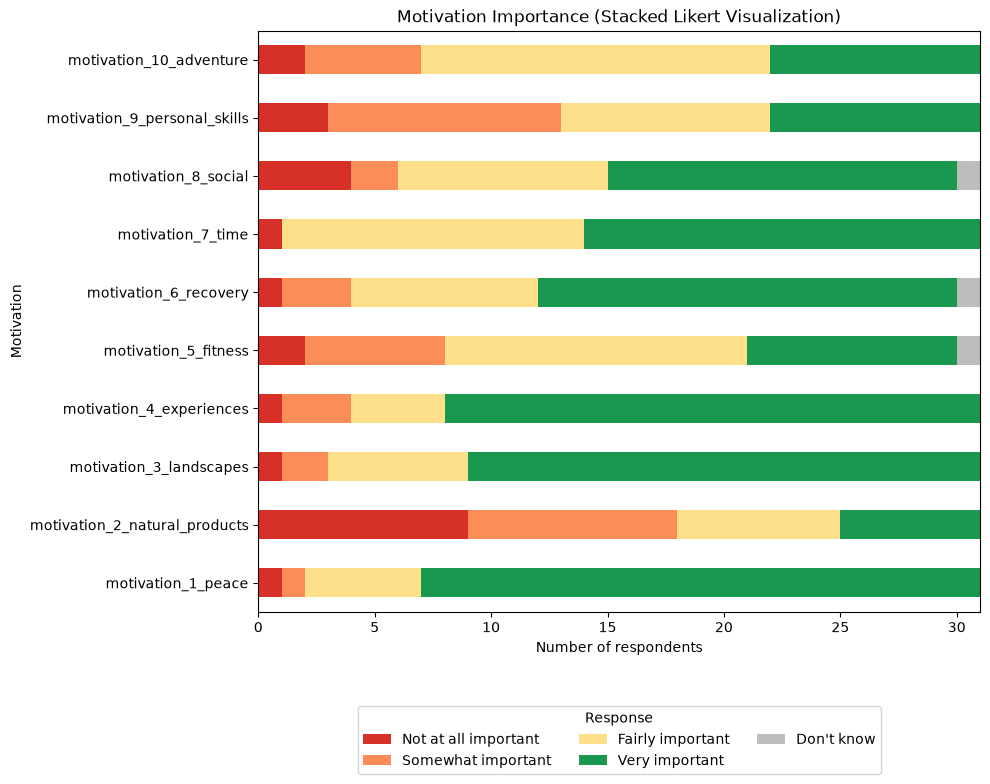

In [76]:
explore_motivation(df_nbt_wilderness_area, motivation_col)

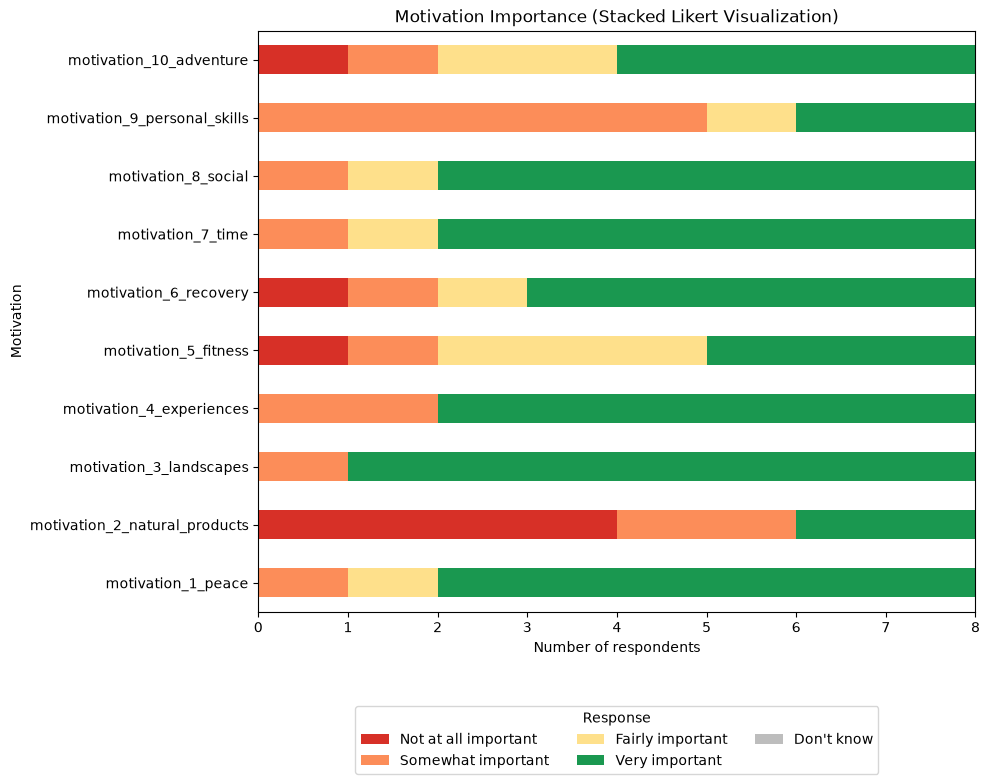

In [77]:
explore_motivation(df_nbt_state_nature_reserve, motivation_col)

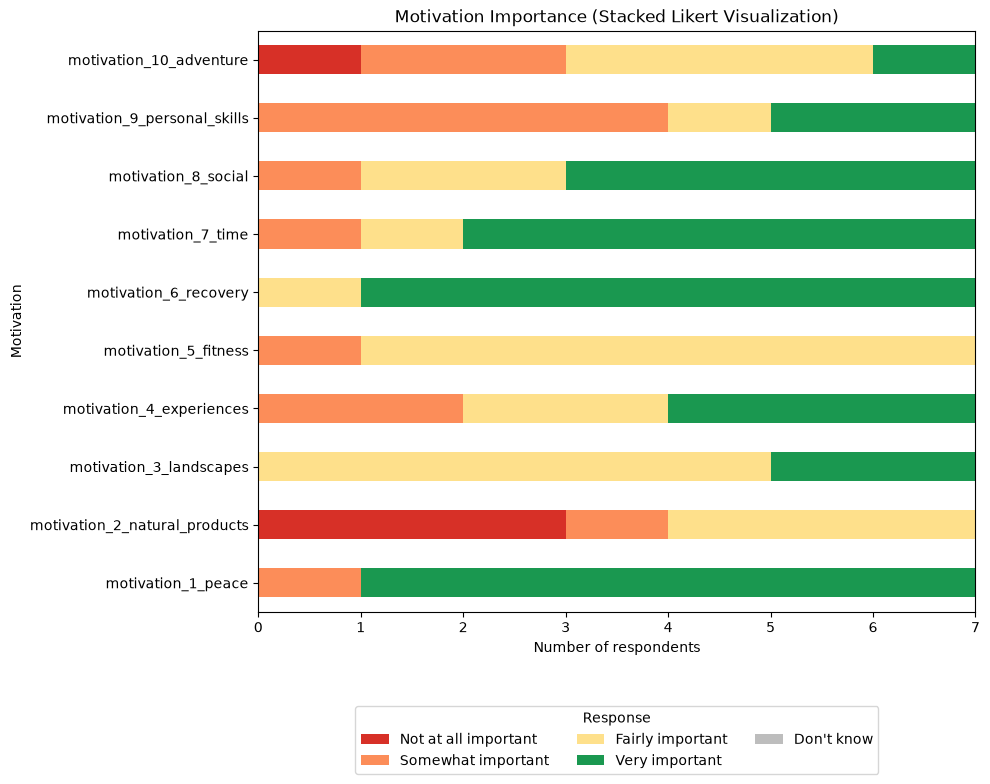

In [78]:
explore_motivation(df_nbt_state_forest, motivation_col)

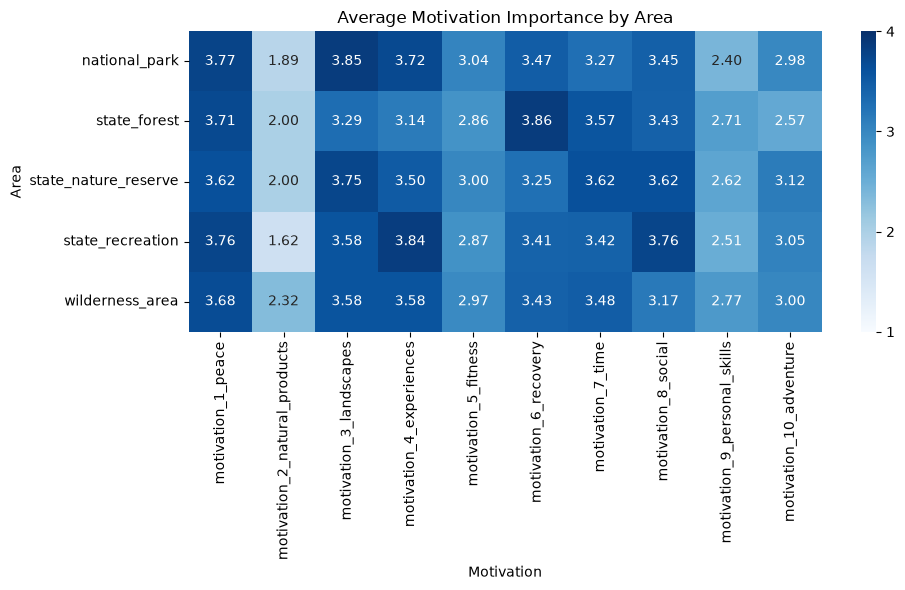

In [79]:
df_nbt_area_motivation = pd.concat([
    df_nbt_state_recreation[motivation_col].assign(area='state_recreation'),
    df_nbt_state_nature_reserve[motivation_col].assign(area='state_nature_reserve'),
    df_nbt_wilderness_area[motivation_col].assign(area='wilderness_area'),
    df_nbt_national_park[motivation_col].assign(area='national_park'),
    df_nbt_state_forest[motivation_col].assign(area='state_forest'),
], ignore_index=True)

# Clean motivation values
df_clean = df_nbt_area_motivation.copy()
df_clean[motivation_col] = (
    df_clean[motivation_col]
    .replace(5, np.nan)
    .apply(pd.to_numeric, errors='coerce')
)

# Average motivation by area (already a DataFrame)
avg_by_area = df_clean.groupby('area')[motivation_col].mean()

# Plot heatmap
plt.figure(figsize=(10, 6))

ax = sns.heatmap(
    avg_by_area,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=1,
    vmax=4,
    cbar_kws={'ticks': [1, 2, 3, 4]}
)

plt.title("Average Motivation Importance by Area")
plt.xlabel("Motivation")
plt.ylabel("Area")
plt.tight_layout()
plt.show()

## All visitors

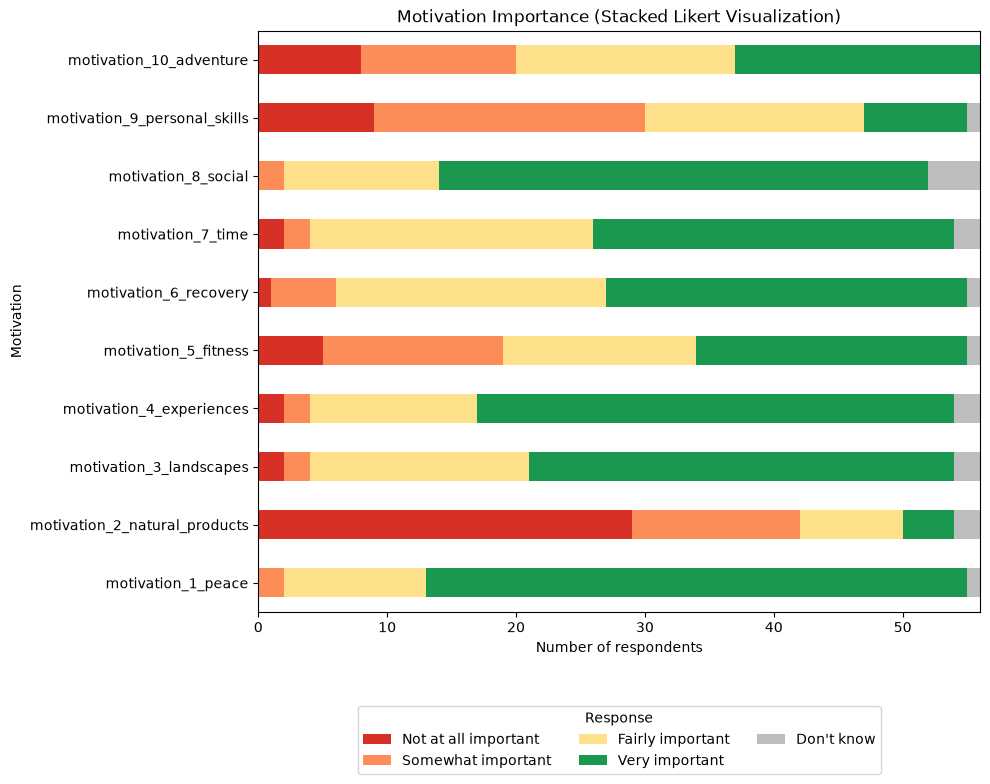

In [80]:
explore_motivation(df_state_recreation, motivation_col)

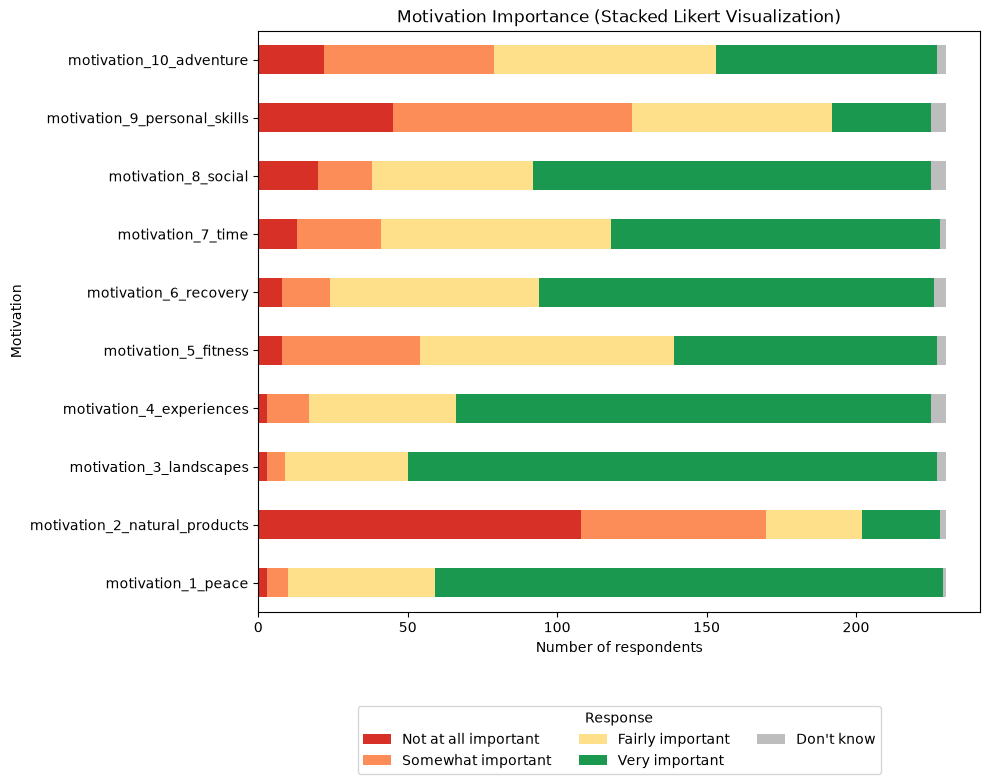

In [81]:
explore_motivation(df_national_park, motivation_col)

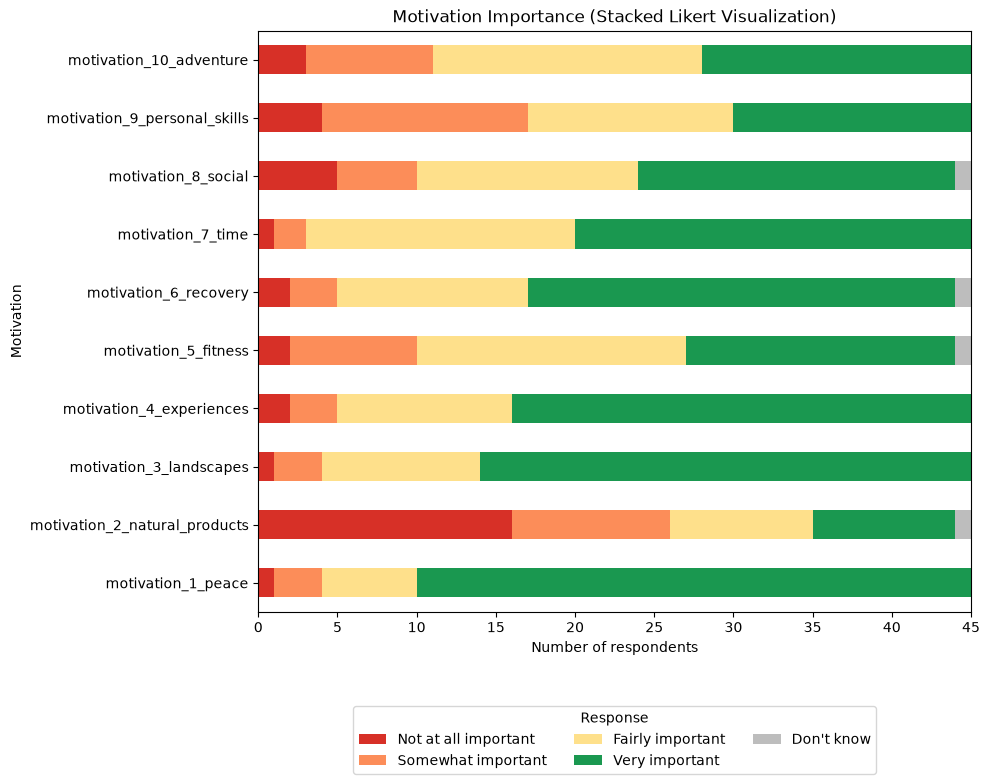

In [82]:
explore_motivation(df_wilderness_area, motivation_col)

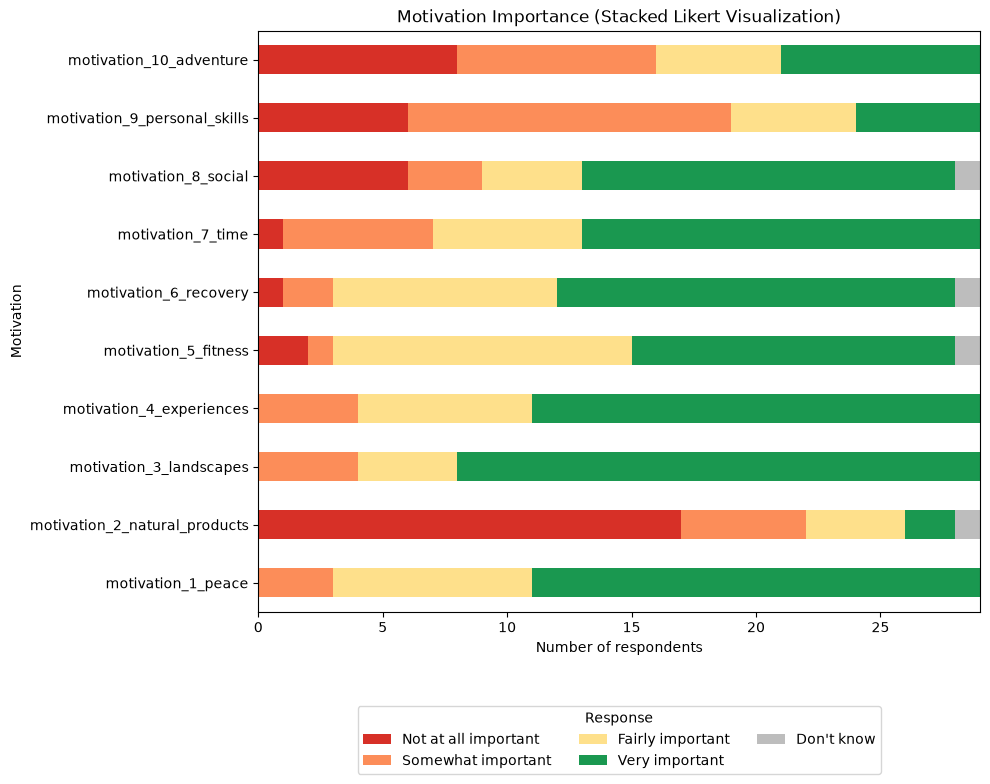

In [83]:
explore_motivation(df_state_nature_reserve, motivation_col)

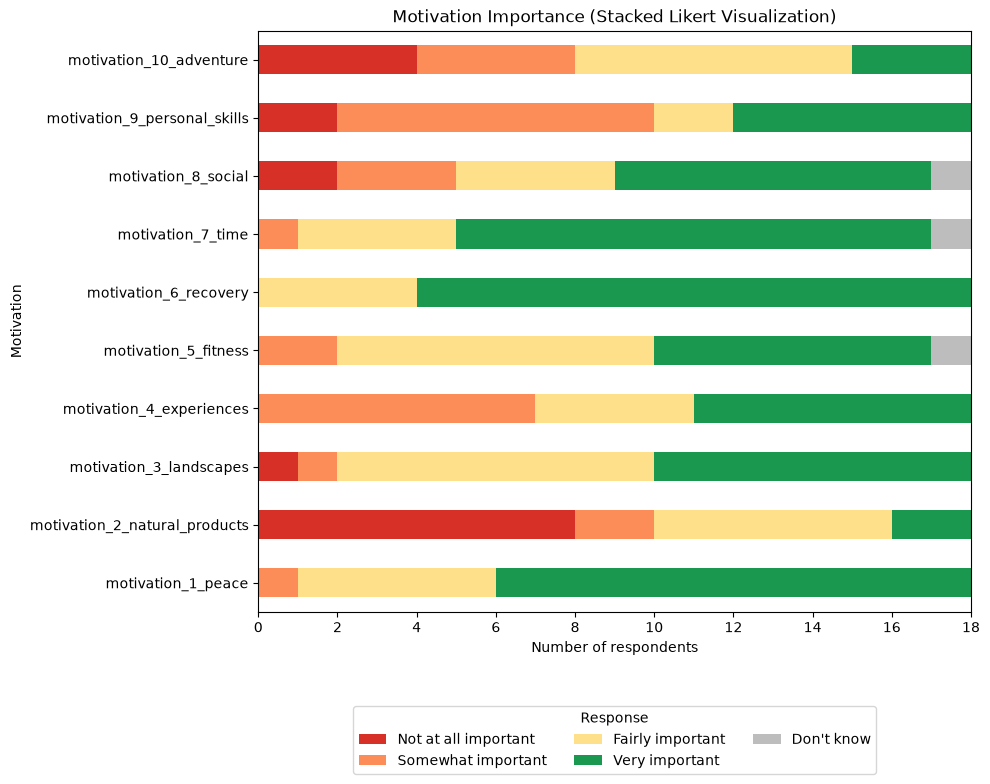

In [84]:
explore_motivation(df_state_forest, motivation_col)

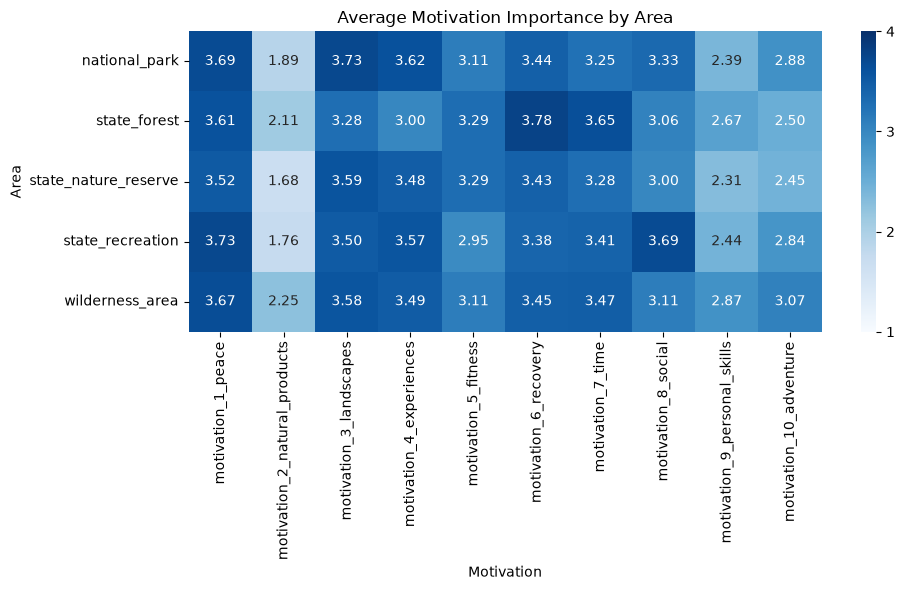

In [85]:
df_area_motivation = pd.concat([
    df_state_recreation[motivation_col].assign(area='state_recreation'),
    df_state_nature_reserve[motivation_col].assign(area='state_nature_reserve'),
    df_wilderness_area[motivation_col].assign(area='wilderness_area'),
    df_national_park[motivation_col].assign(area='national_park'),
    df_state_forest[motivation_col].assign(area='state_forest'),
], ignore_index=True)

# Clean motivation values
df_clean = df_area_motivation.copy()
df_clean[motivation_col] = (
    df_clean[motivation_col]
    .replace(5, np.nan)
    .apply(pd.to_numeric, errors='coerce')
)

# Average motivation by area (already a DataFrame)
avg_by_area = df_clean.groupby('area')[motivation_col].mean()

# Plot heatmap
plt.figure(figsize=(10, 6))

ax = sns.heatmap(
    avg_by_area,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=1,
    vmax=4,
    cbar_kws={'ticks': [1, 2, 3, 4]}
)

plt.title("Average Motivation Importance by Area")
plt.xlabel("Motivation")
plt.ylabel("Area")
plt.tight_layout()
plt.show()

# Travel time & distance
- A50. How much time did you spend travelling to an outdoor area or nature site?
- A51_km. How far was the distance from the starting point to the outdoor area or nature reserve: km

## Daytrip visitors

In [86]:
df_or[['A50_travel_time', 'A51_km_travel_distance']].describe()

,A50_travel_time,A51_km_travel_distance
count,165.000000,165.000000
mean,2.830303,26.332430
std,1.568066,67.710691
min,1.000000,0.000000
25%,2.000000,0.500000
50%,2.000000,4.000000
75%,4.000000,22.000000
max,6.000000,500.000000


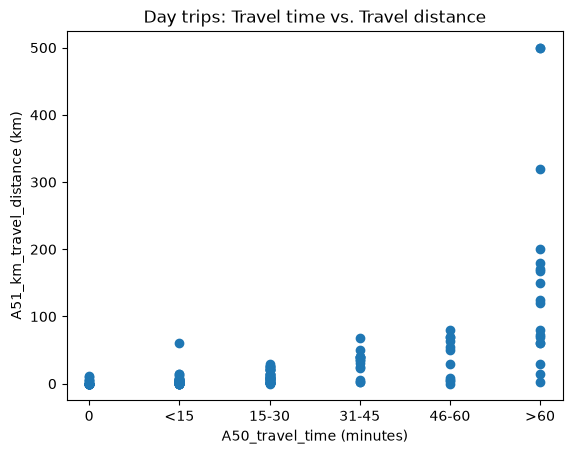

In [87]:
plt.scatter(df_or['A50_travel_time'], df_or['A51_km_travel_distance'])
plt.xlabel('A50_travel_time (minutes)')
plt.ylabel('A51_km_travel_distance (km)')

labels = {
    1: '0',
    2: '<15',
    3: '15-30',
    4: '31-45',
    5: '46-60',
    6: '>60',
}

ax = plt.gca()
ax.set_xticks(list(labels.keys()))
ax.set_xticklabels(list(labels.values()))

plt.title('Day trips: Travel time vs. Travel distance')
plt.show()

## Multiday trip visitors

In [88]:
df_nbt[['A50_travel_time', 'A51_km_travel_distance']].describe()

,A50_travel_time,A51_km_travel_distance
count,286.000000,286.000000
mean,2.286713,15.022836
std,1.404866,73.462492
min,1.000000,0.000000
25%,1.000000,0.100000
50%,2.000000,2.000000
75%,3.000000,7.000000
max,6.000000,900.000000


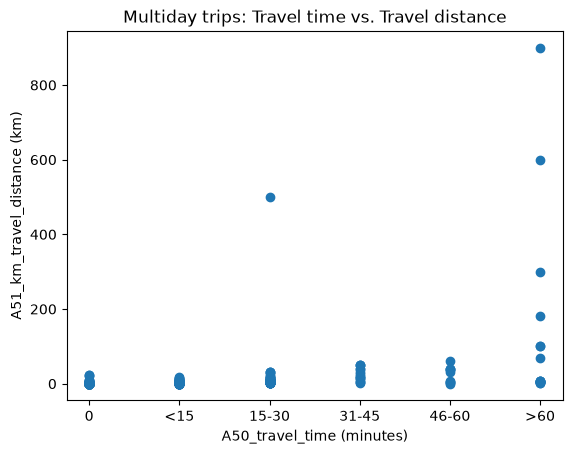

In [89]:
plt.scatter(df_nbt['A50_travel_time'], df_nbt['A51_km_travel_distance'])
plt.xlabel('A50_travel_time (minutes)')
plt.ylabel('A51_km_travel_distance (km)')

labels = {
    1: '0',
    2: '<15',
    3: '15-30',
    4: '31-45',
    5: '46-60',
    6: '>60',
}

ax = plt.gca()
ax.set_xticks(list(labels.keys()))
ax.set_xticklabels(list(labels.values()))

plt.title('Multiday trips: Travel time vs. Travel distance')
plt.show()

## All visitors

In [90]:
df[['A50_travel_time', 'A51_km_travel_distance']].describe()

,A50_travel_time,A51_km_travel_distance
count,451.000000,451.000000
mean,2.485588,19.160492
std,1.488218,71.544092
min,1.000000,0.000000
25%,1.000000,0.200000
50%,2.000000,2.000000
75%,3.000000,10.000000
max,6.000000,900.000000


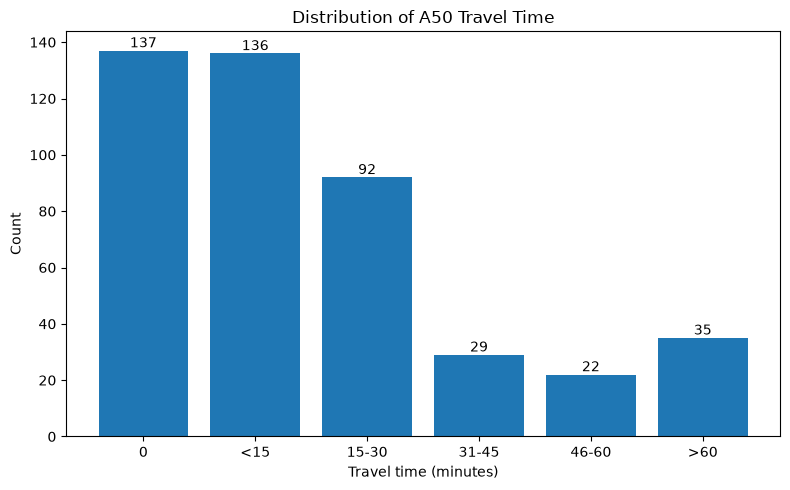

In [91]:
labels = {
    1: '0',
    2: '<15',
    3: '15-30',
    4: '31-45',
    5: '46-60',
    6: '>60',
}

fig, ax = plt.subplots(figsize=(8, 5))

# Plot histogram and capture counts
counts, bins, patches = ax.hist(
    df['A50_travel_time'],
    bins=6,
    rwidth=0.8
)

# Set custom x-axis labels at bin centers
bin_centers = 0.5 * (bins[:-1] + bins[1:])
ax.set_xticks(bin_centers)
ax.set_xticklabels(labels.values())

# Add value annotations on top of each bin
for count, x in zip(counts, bin_centers):
    ax.text(x, count, int(count), ha='center', va='bottom')

# Add title and axis labels
ax.set_title('Distribution of A50 Travel Time')
ax.set_xlabel('Travel time (minutes)')
ax.set_ylabel('Count')

# Ensure no legend
ax.legend_.remove() if ax.legend_ else None

plt.tight_layout()
plt.show()

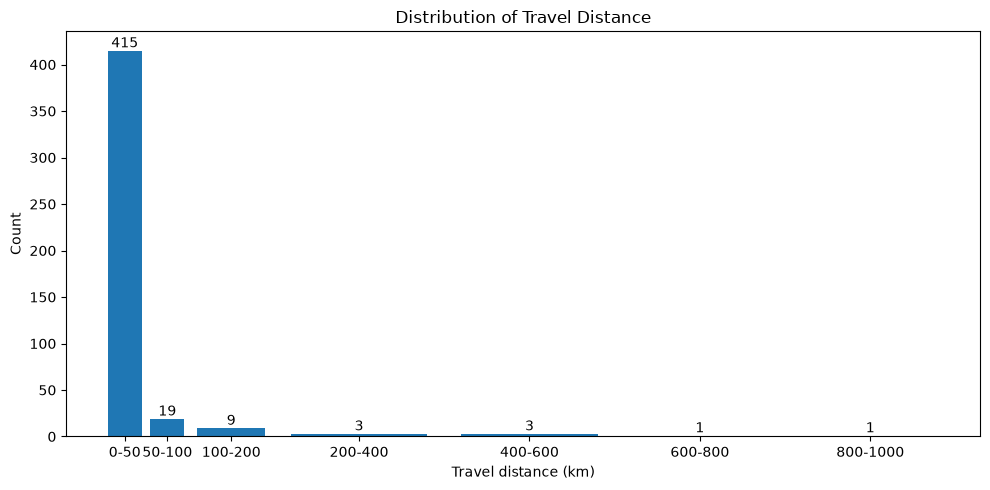

In [92]:
# Distance intervals (km)
bins = [0, 50, 100, 200, 400, 600, 800, 1000]
labels = ['0-50', '50-100', '100-200', '200-400', '400-600', '600-800', '800-1000']

fig, ax = plt.subplots(figsize=(10, 5))

counts, bin_edges, patches = ax.hist(
    df['A51_km_travel_distance'],
    bins=bins,
    rwidth=0.8
)

# Bin centers for labeling
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# X-axis labels
ax.set_xticks(bin_centers)
ax.set_xticklabels(labels)

# Add count annotations
for count, x in zip(counts, bin_centers):
    ax.text(x, count, int(count), ha='center', va='bottom')

# Titles and labels
ax.set_title('Distribution of Travel Distance')
ax.set_xlabel('Travel distance (km)')
ax.set_ylabel('Count')

# Remove legend if any
ax.legend_.remove() if ax.legend_ else None

plt.tight_layout()
plt.show()

# Trip duration

## Daytrip visitors

In [93]:
# TA49h. Duration of last outdoor activity or excursion in hours
df_or[['TA49h_last_activity_duration']].describe()

,TA49h_last_activity_duration
count,165.000000
mean,2.760505
std,2.585787
min,0.266667
25%,1.000000
50%,2.000000
75%,3.166667
max,14.000000


<Axes: xlabel='Duration (hours)', ylabel='Frequency'>

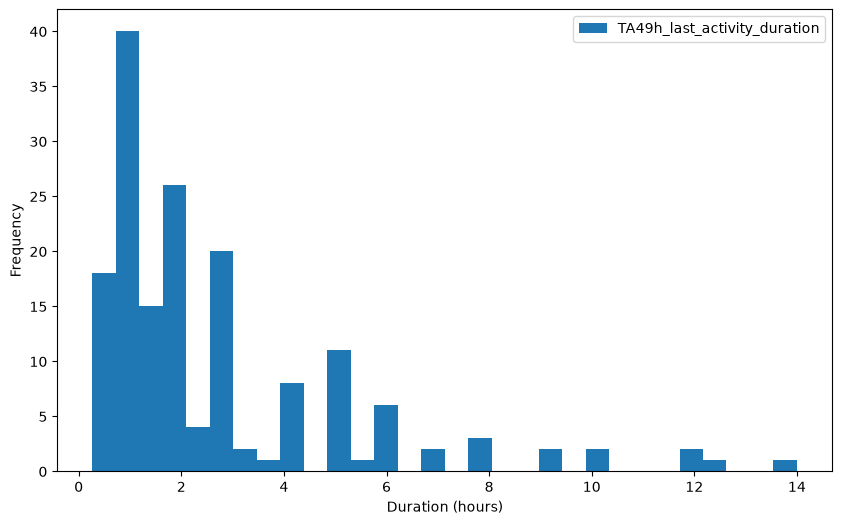

In [94]:
df_or[['TA49h_last_activity_duration']].plot(kind='hist', bins=30, figsize=(10, 6), xlabel='Duration (hours)')

## Multiday trip visitors

In [95]:
# A55. Duration of the multi-day trip in days
df_nbt[['A55_last_multi_day_trip_duration']].describe()

,A55_last_multi_day_trip_duration
count,283.000000
mean,5.473498
std,3.822549
min,0.000000
25%,3.000000
50%,5.000000
75%,7.000000
max,30.000000


<Axes: xlabel='Duration (days)', ylabel='Frequency'>

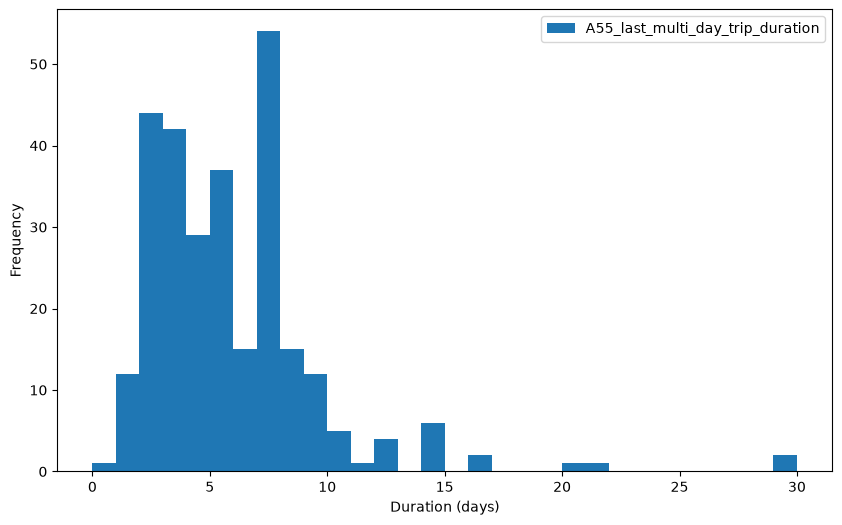

In [96]:
df_nbt[['A55_last_multi_day_trip_duration']].plot(kind='hist', bins=30, figsize=(10, 6), xlabel='Duration (days)')

# Opinions

In [97]:
concern_col = ['Ymp1a_concern_logging', 'Ymp1b_concern_climate_change', 'Ymp1c_concern_noise',
               'Ymp1d_concern_water_quality', 'Ymp1e_concern_forest_reduction', 'Ymp1f_concern_species_loss',
               'Ymp1g_concern_alien_species', 'Ymp1h_concern_vegetarian', 'Ymp1i_concern_oil_spill',
               'Ymp1j_concern_landscape_closure', 'Ymp1l_concern_wind_farms', 'Ymp1m_concern_harmful_substances']


def explore_concern(df, concern_col):
    # Rename numeric values for readability
    mapping = {
        1: "Not at all worrying",
        2: "Somewhat worrying",
        3: "Very worrying",
        4: "Extremely worrying",
        5: "Don't know"
    }

    df_c = df[concern_col].apply(lambda s: s.map(mapping))

    # Count responses per category
    counts = df_c.apply(lambda x: x.value_counts()).fillna(0)

    # Reorder categories
    order = ["Not at all worrying", "Somewhat worrying", "Very worrying", "Extremely worrying", "Don't know"]
    counts = counts.reindex(order).fillna(0)

    # Define a color palette
    colors = ["#d73027", "#fc8d59", "#fee08b", "#1a9850", "#bdbdbd"]

    # Plot
    ax = counts.T.plot(kind="barh", stacked=True, figsize=(10, 8), color=colors)

    plt.xlabel("Number of respondents")
    plt.ylabel("Concern")
    plt.title("Concern (Stacked Likert Visualization)")

    # Legend outside the plot
    plt.legend(
        title="Response",
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        ncol=3
    )

    plt.tight_layout()
    plt.show()

In [98]:
frequency_col = ['Ymp2a_frequency_save_energy', 'Ymp2b_frequency_energy_saving_products', 'Ymp2c_frequency_household_waste',
                 'Ymp2d_frequency_eco-products', 'Ymp2e_frequency_organic_food', 'Ymp2f_frequency_avoid_driving',
                 'Ymp2g_frequency_avoid_flying', 'Ymp2h_frequency_vegetarian', 'Ymp2i_frequency_recycled_products']


def explore_frequency(df, frequency_col):
    # Rename numeric values for readability
    mapping = {
        1: "Never",
        2: "Very rarely",
        3: "Quite rarely",
        4: "Quite often",
        5: "Very often",
        6: "Always",
        7: "Don't know",
        8: "Does not concern me"
    }

    df_f = df[frequency_col].apply(lambda s: s.map(mapping))

    # Count responses per category
    counts = df_f.apply(lambda x: x.value_counts()).fillna(0)

    # Reorder categories
    order = ["Never", "Very rarely", "Quite rarely", "Quite often", "Very often", "Always", "Don't know", "Does not concern me"]
    counts = counts.reindex(order).fillna(0)

    # Define a color palette
    colors = ["#d73027", "#fc8d59", "#fee08b", "#97dbb5", "#1a9850", "#0b6632", "#bdbdbd", "#946588"]

    # Plot
    ax = counts.T.plot(kind="barh", stacked=True, figsize=(10, 8), color=colors)

    plt.xlabel("Number of respondents")
    plt.ylabel("Frequency")
    plt.title("Frequency (Stacked Likert Visualization)")

    # Legend outside the plot
    plt.legend(
        title="Response",
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        ncol=3
    )

    plt.tight_layout()
    plt.show()

In [99]:
attitude_col = ['Ymp3a_attitude_avoid_driving', 'Ymp3b_attitude_more_travelling_time', 'Ymp3c_attitude_nearby_destination',
                'Ymp3d_attitude_reduce_purchase_equipments', 'Ymp4a_attitude_low_carbon_travel', 'Ymp4b_attitude_more_travelling_time',
                'Ymp4c_attitude_nearby_destination', 'Ymp4d_attitude_group_travel', 'Ymp4e_attitude_low_carbon_services',
                'Ymp4f_attitude_avoid_trips']


def explore_attitude(df, attitude_col):
    # Rename numeric values for readability
    mapping = {
        1: "Strongly disagree",
        2: "Somewhat disagree",
        3: "Neither agree nor disagree",
        4: "Somewhat agree",
        5: "Strongly agree",
        6: "Not relevant for me"
    }

    df_a = df[attitude_col].apply(lambda s: s.map(mapping))

    # Count responses per category
    counts = df_a.apply(lambda x: x.value_counts()).fillna(0)

    # Reorder categories
    order = ["Strongly disagree", "Somewhat disagree", "Neither agree nor disagree", "Somewhat agree", "Strongly agree", "Not relevant for me"]
    counts = counts.reindex(order).fillna(0)

    # Define a color palette
    colors = ["#d73027", "#fc8d59", "#fee08b", "#97dbb5", "#1a9850", "#bdbdbd"]

    # Plot
    ax = counts.T.plot(kind="barh", stacked=True, figsize=(10, 8), color=colors)

    plt.xlabel("Number of respondents")
    plt.ylabel("Attitude")
    plt.title("Attitude (Stacked Likert Visualization)")

    # Legend outside the plot
    plt.legend(
        title="Response",
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        ncol=3
    )

    plt.tight_layout()
    plt.show()

## Daytrip visitors

### Concern

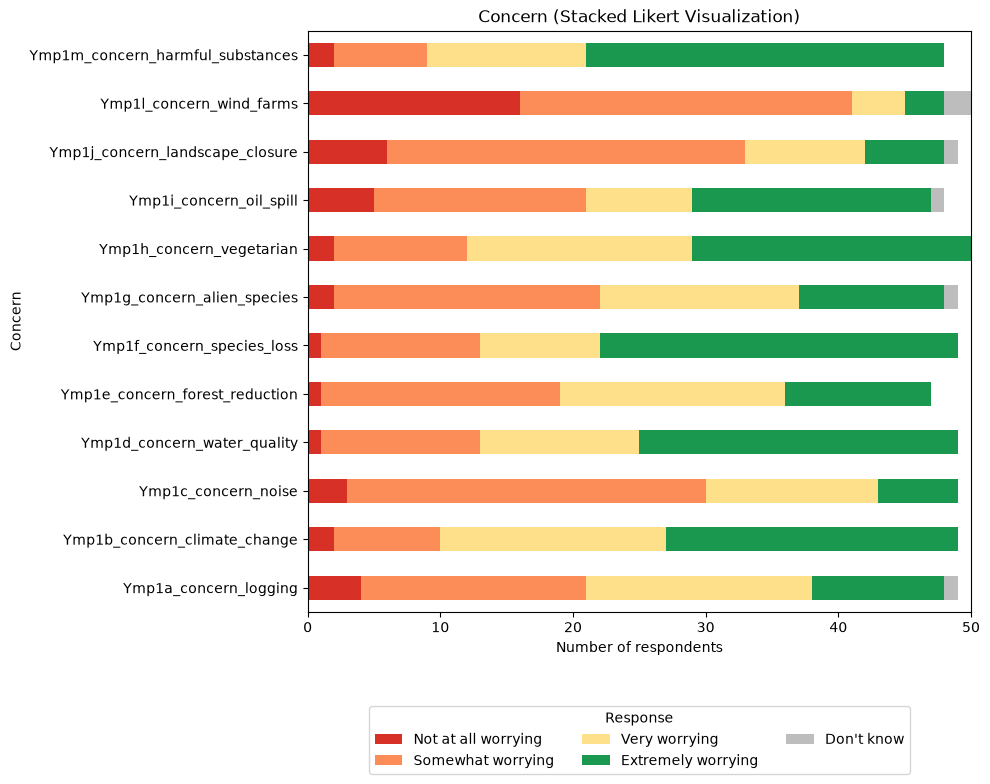

In [100]:
explore_concern(df_or, concern_col)

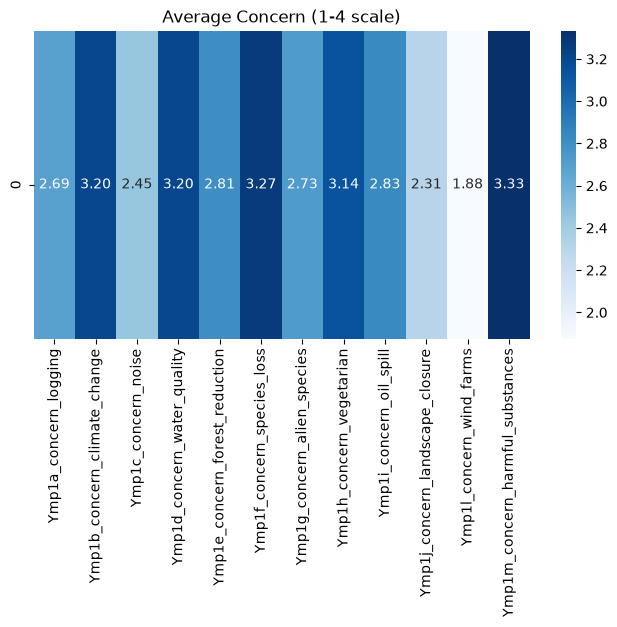

In [101]:
df_clean = df_or[concern_col].replace(5, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8, 4))
sns.heatmap(avg.to_frame().T, annot=True, fmt=".2f", cmap="Blues")
plt.title("Average Concern (1-4 scale)")
plt.show()

### Frequency

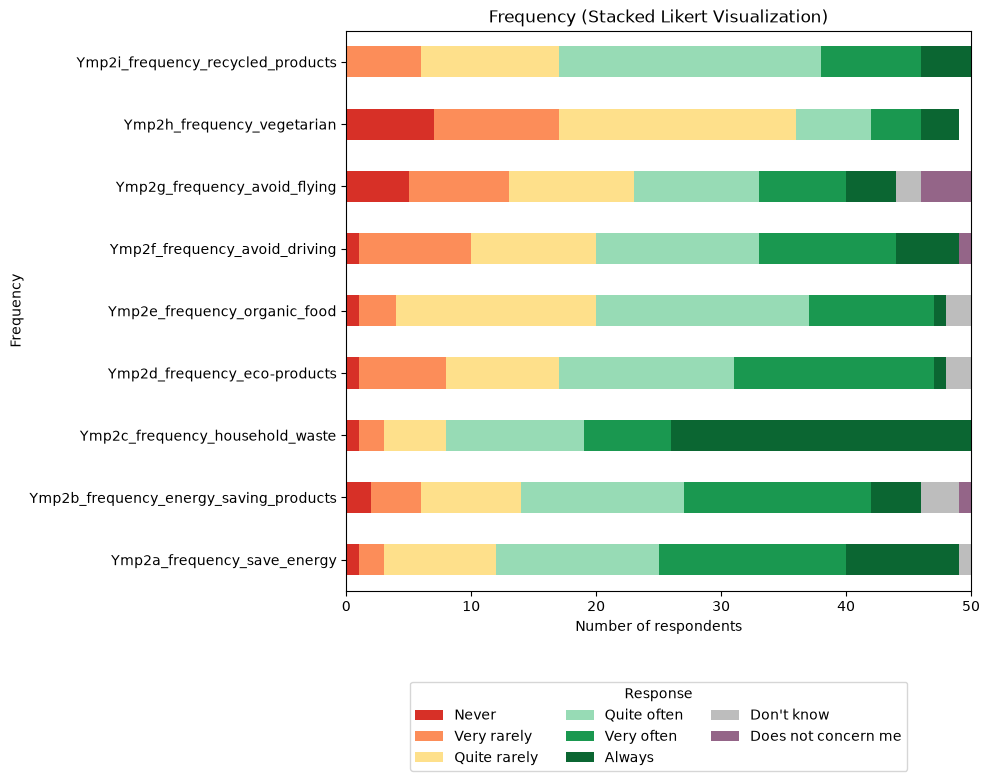

In [102]:
explore_frequency(df_or, frequency_col)

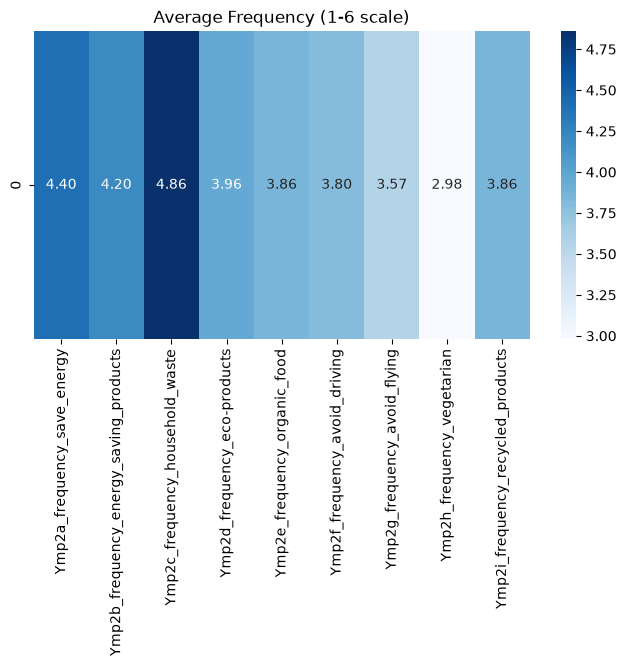

In [103]:
df_clean = df_or[frequency_col].replace(8, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8, 4))
sns.heatmap(avg.to_frame().T, annot=True, fmt=".2f", cmap="Blues")
plt.title("Average Frequency (1-6 scale)")
plt.show()

### Attitude

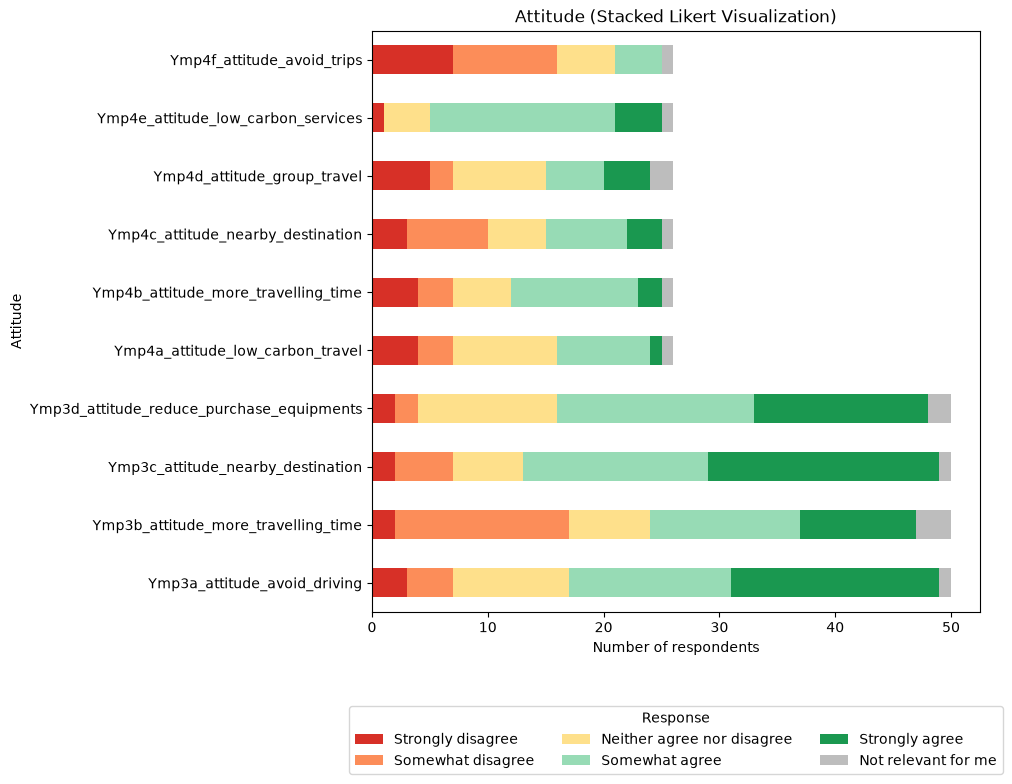

In [104]:
explore_attitude(df_or, attitude_col)

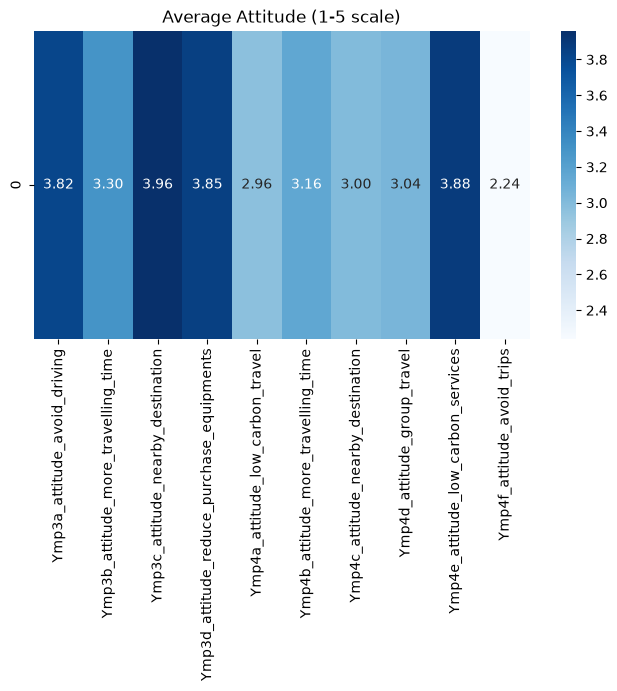

In [105]:
df_clean = df_or[attitude_col].replace(6, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8, 4))
sns.heatmap(avg.to_frame().T, annot=True, fmt=".2f", cmap="Blues")
plt.title("Average Attitude (1-5 scale)")
plt.show()

## Multiday trip visitors

### Concern

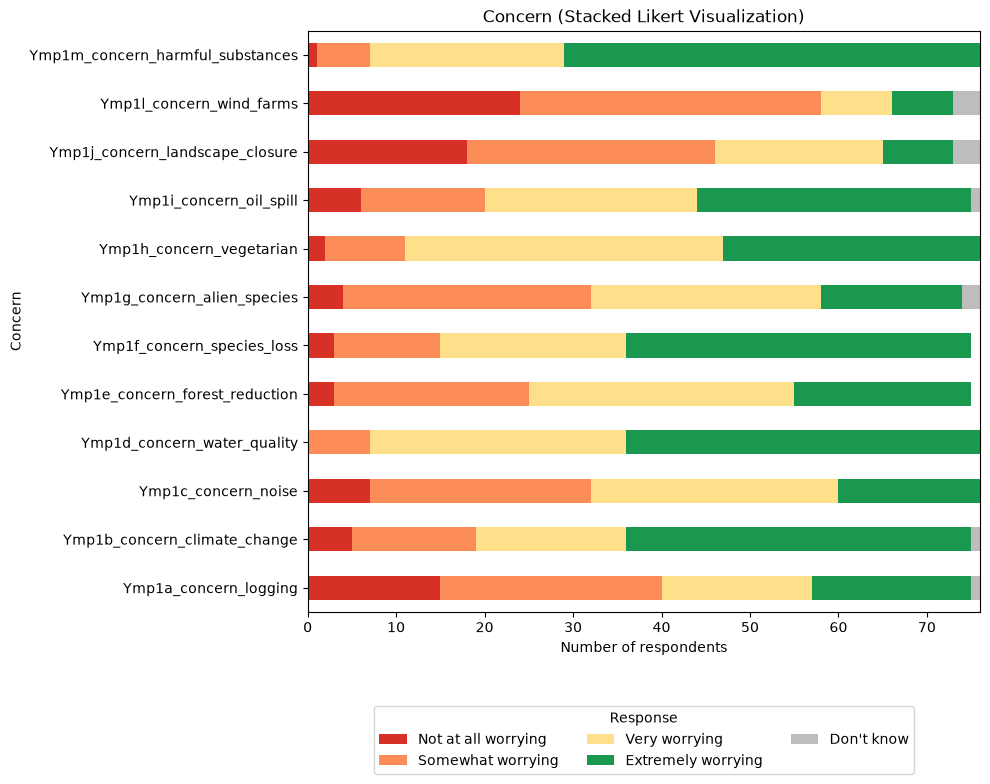

In [106]:
explore_concern(df_nbt, concern_col)

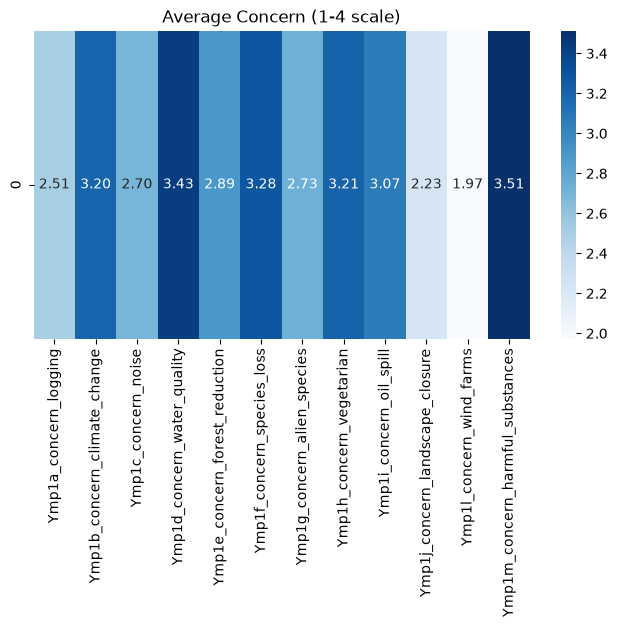

In [107]:
df_clean = df_nbt[concern_col].replace(5, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8, 4))
sns.heatmap(avg.to_frame().T, annot=True, fmt=".2f", cmap="Blues")
plt.title("Average Concern (1-4 scale)")
plt.show()

### Frequency

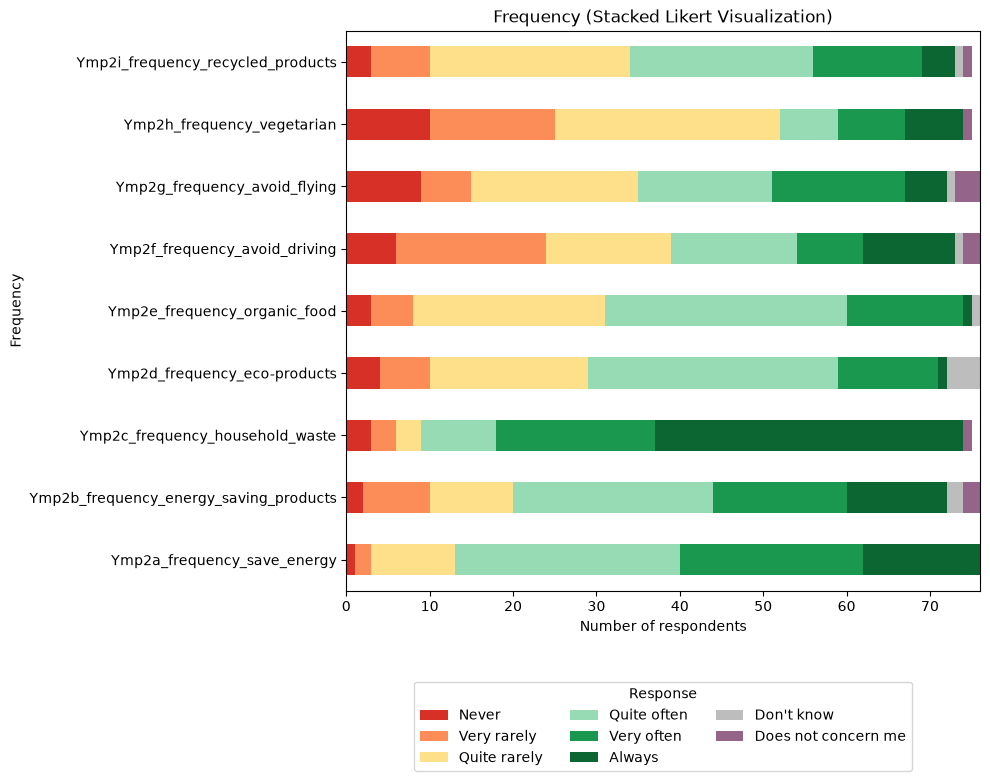

In [108]:
explore_frequency(df_nbt, frequency_col)

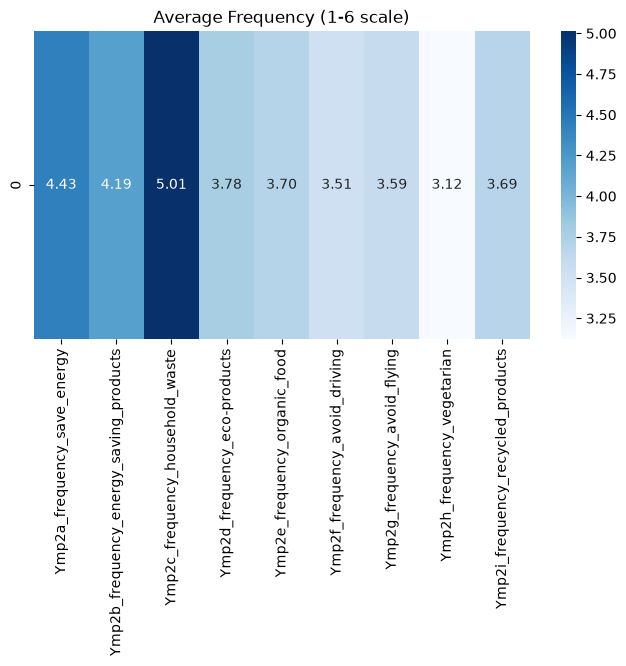

In [109]:
df_clean = df_nbt[frequency_col].replace(8, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8, 4))
sns.heatmap(avg.to_frame().T, annot=True, fmt=".2f", cmap="Blues")
plt.title("Average Frequency (1-6 scale)")
plt.show()

### Attitude

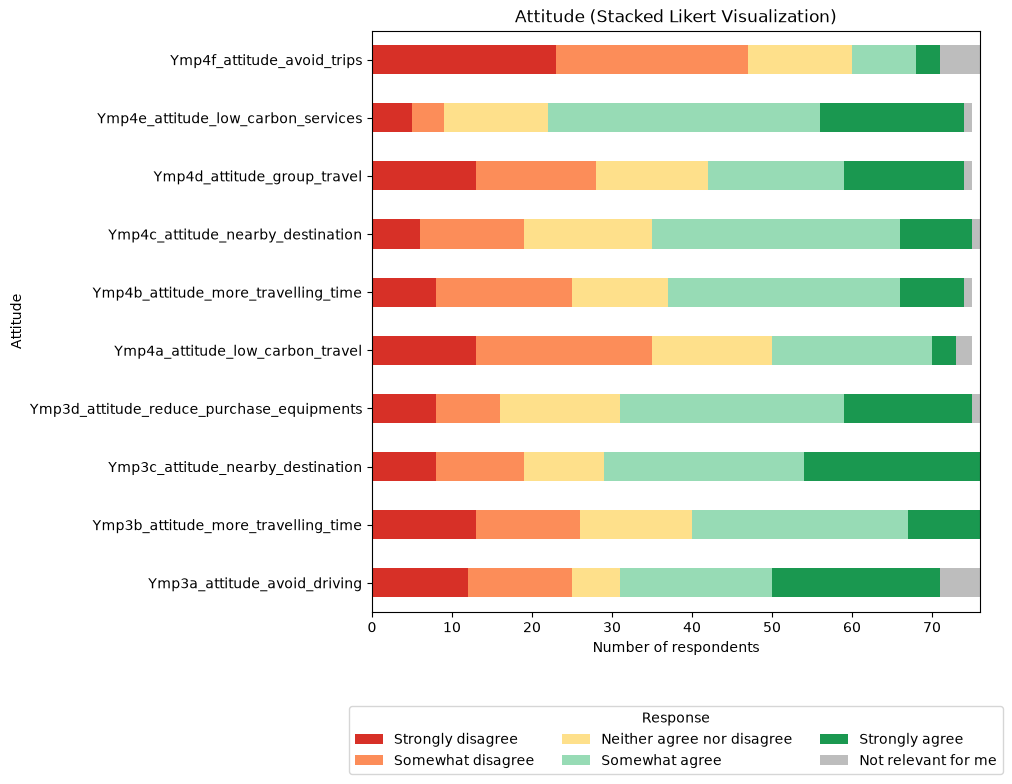

In [110]:
explore_attitude(df_nbt, attitude_col)

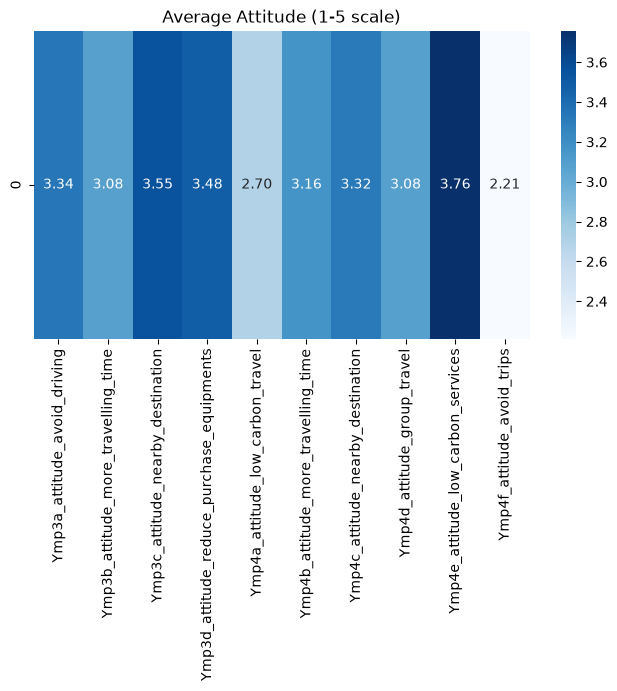

In [111]:
df_clean = df_nbt[attitude_col].replace(6, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8, 4))
sns.heatmap(avg.to_frame().T, annot=True, fmt=".2f", cmap="Blues")
plt.title("Average Attitude (1-5 scale)")
plt.show()

## All visitors

### Concern

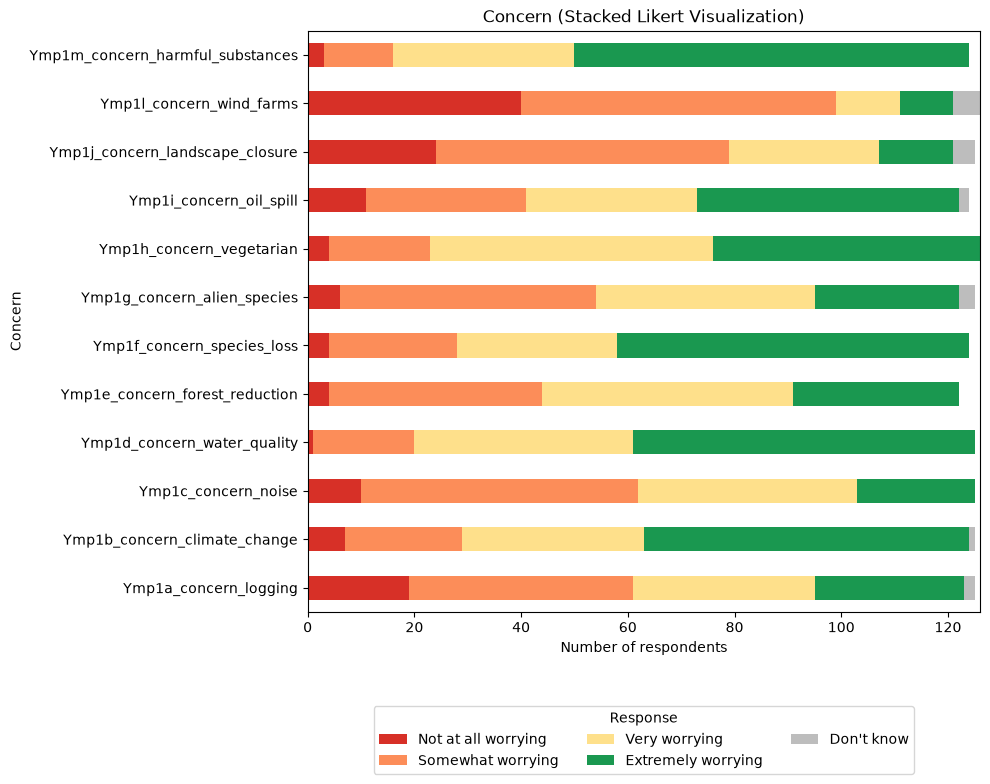

In [112]:
explore_concern(df, concern_col)

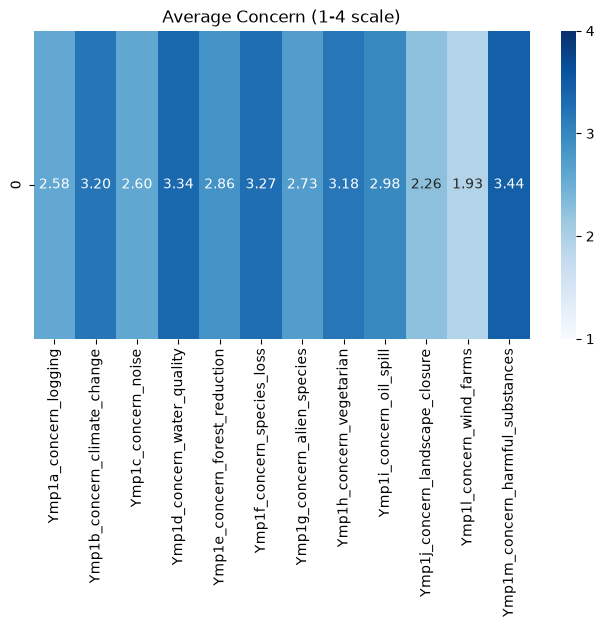

In [113]:
df_clean = df[concern_col].replace(5, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8, 4))
ax = sns.heatmap(
    avg.to_frame().T,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=1,
    vmax=4,
    cbar_kws={'ticks': [1, 2, 3, 4]}
)
plt.title("Average Concern (1-4 scale)")
plt.show()

### Frequency

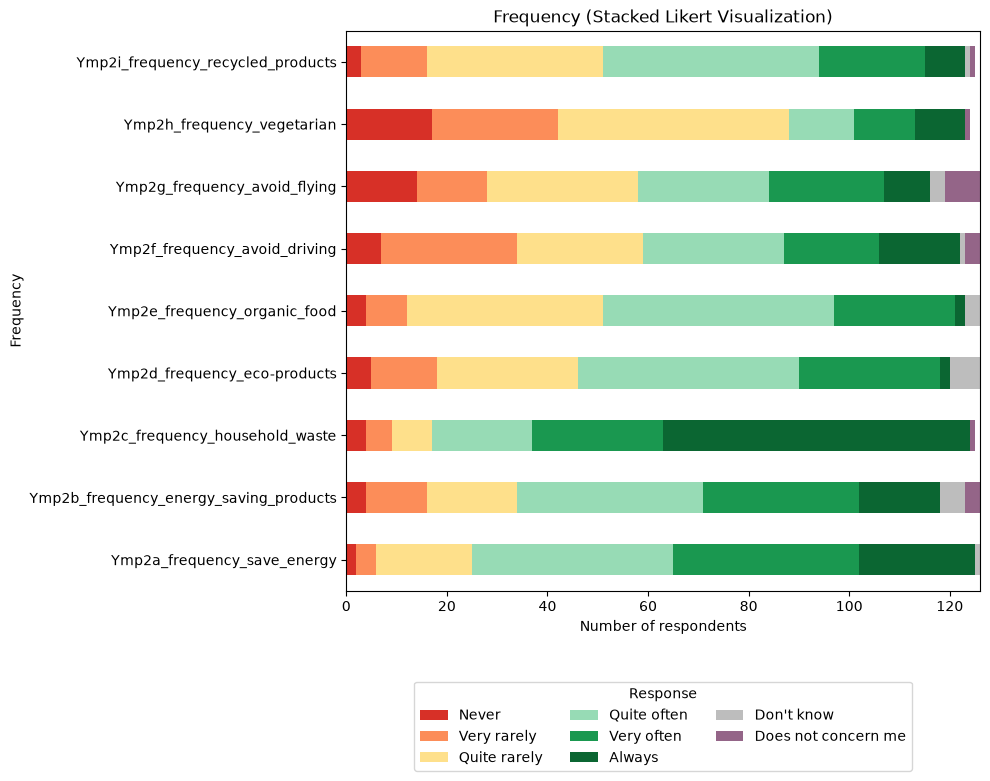

In [114]:
explore_frequency(df, frequency_col)

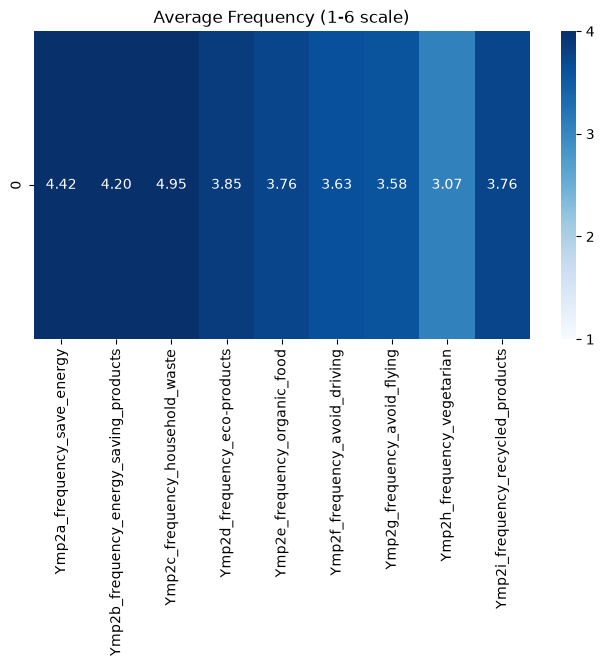

In [115]:
df_clean = df[frequency_col].replace(8, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8, 4))
ax = sns.heatmap(
    avg.to_frame().T,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=1,
    vmax=4,
    cbar_kws={'ticks': [1, 2, 3, 4]}
)
plt.title("Average Frequency (1-6 scale)")
plt.show()

### Attitude

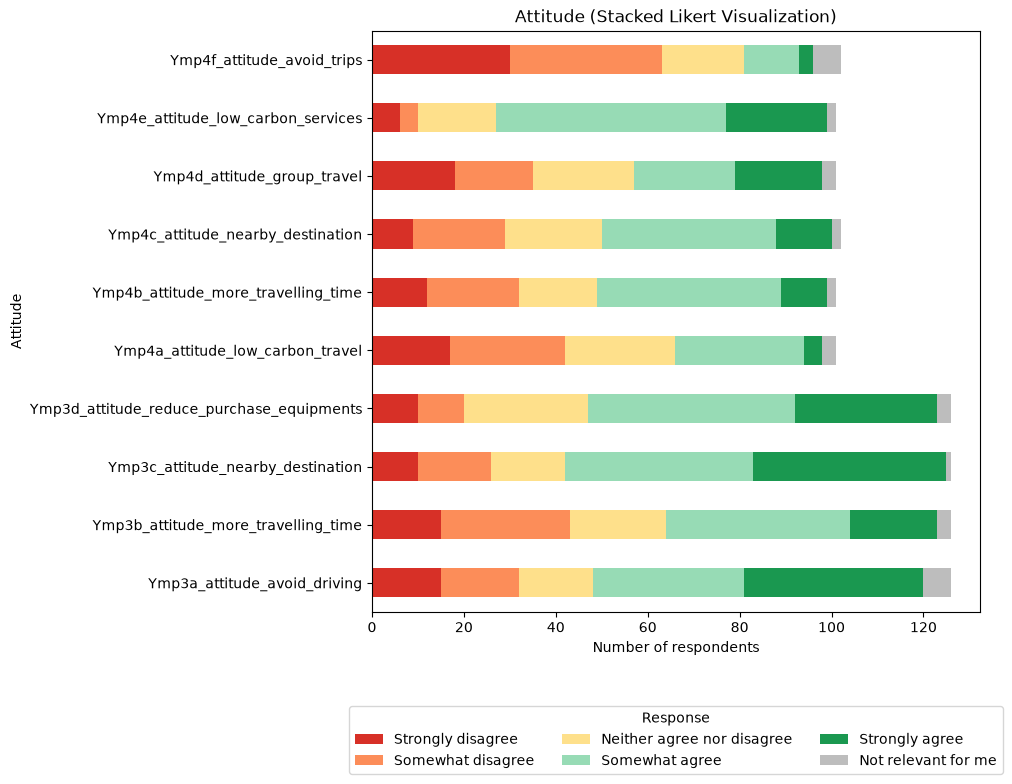

In [116]:
explore_attitude(df, attitude_col)

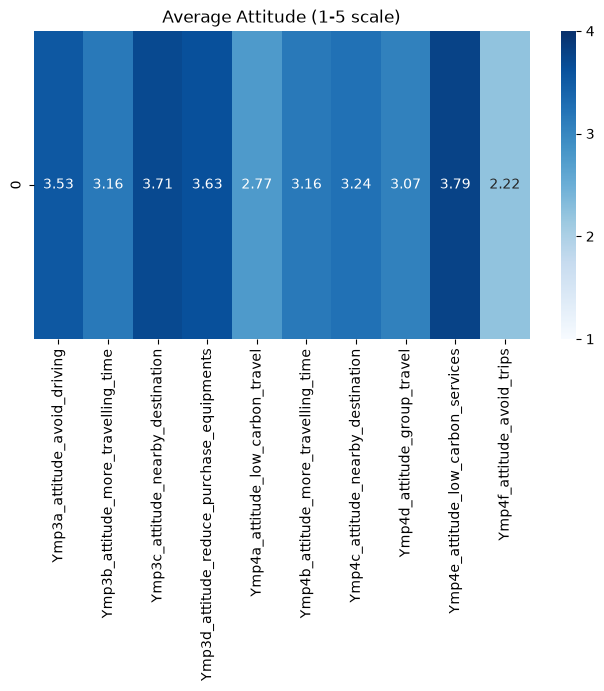

In [117]:
df_clean = df[attitude_col].replace(6, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8, 4))
ax = sns.heatmap(
    avg.to_frame().T,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=1,
    vmax=4,
    cbar_kws={'ticks': [1, 2, 3, 4]}
)
plt.title("Average Attitude (1-5 scale)")
plt.show()

# Area characteristics

In [118]:
area_characteristics_col = [
    'B_6a_area_footpath', 'B_6b_area_built_path', 'B_6c_area_references', 'B_6d_area_signposting', 'B_6e_area_visitor_center', 'B_6f_area_outdoor_house',
    'B_6g_area_deserted_house', 'B_6h_area_fireplace', 'B_6i_area_beach', 'B_6j_area_camping_area', 'B_6k_area_ski_trail', 'B_6l_area_ski_slope',
    'B_6m_area_boat_dock', 'B_6n_area_other', 'B_7a_lawn', 'B_7b_forest', 'B_7suo_swamp', 'B_7c_cultivated_field',
    'B_7d_meadow', 'B_7e_mountain', 'B_7f_lake', 'B_7g_sea', 'B_7h_river', 'B_7i_berry', 'B_7j_mushroom', 'B_7k_hunting', 'B_7l_fishing',
    'B_7m_natural_attraction', 'B_7n_other']

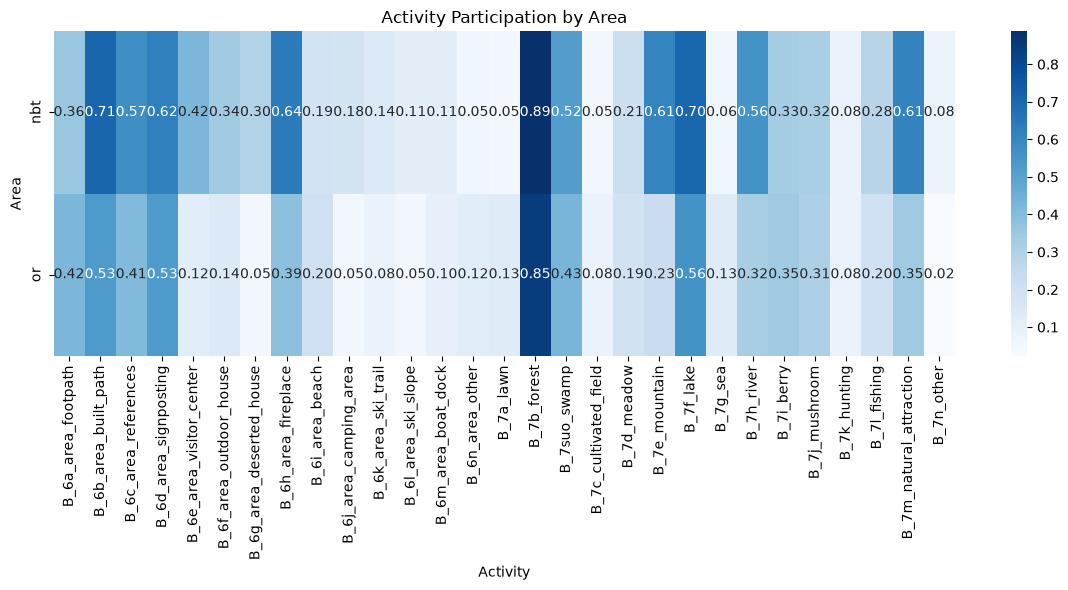

In [119]:
group_means = df.groupby('source')[area_characteristics_col].mean()

plt.figure(figsize=(12, 6))
sns.heatmap(
    group_means,
    annot=True,
    fmt=".2f",
    cmap='Blues'
)

plt.title('Activity Participation by Area')
plt.xlabel('Activity')
plt.ylabel('Area')
plt.tight_layout()
plt.show()

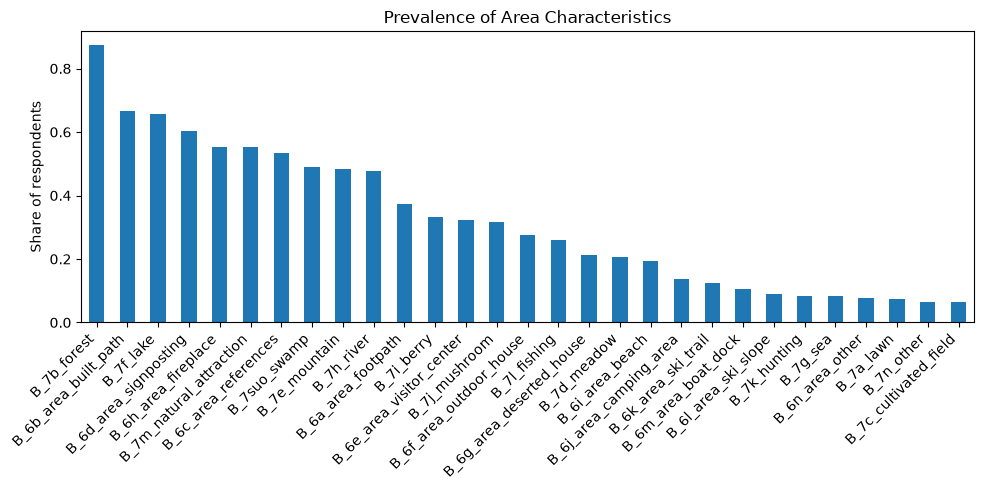

In [120]:
shares = df[area_characteristics_col].mean().sort_values(ascending=False)

ax = shares.plot(kind='bar', figsize=(10, 5))
ax.set_ylabel('Share of respondents')
ax.set_title('Prevalence of Area Characteristics')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Accompany

## Daytrip visitors

B_2_accompany
1.0    70
2.0    69
3.0    24
6.0     1
7.0     1
Name: count, dtype: int64


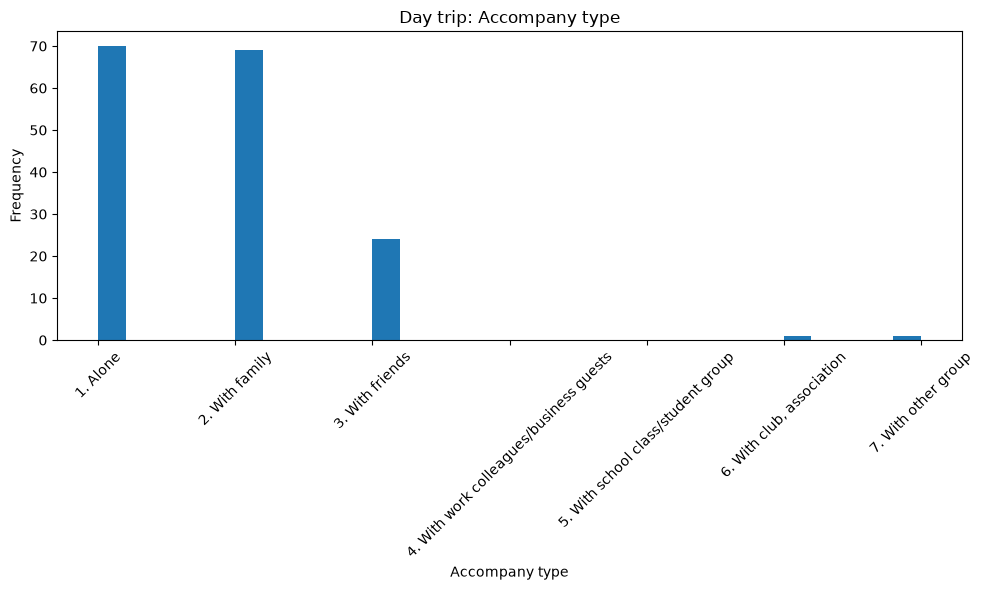

In [121]:
# Plot accompany type for daytrip visitors
print(df_or['B_2_accompany'].value_counts().sort_index())

ax = df_or['B_2_accompany'].plot(
    kind='hist',
    bins=30,
    figsize=(10, 6),
    xlabel='Accompany type'
)

# Replace x ticks
ax.set_xticks([1, 2, 3, 4, 5, 6, 7])
ax.set_xticklabels(['1. Alone', '2. With family', '3. With friends', '4. With work colleagues/business guests',
                    '5. With school class/student group', '6. With club, association', '7. With other group'],
                   rotation=45)
ax.set_title('Day trip: Accompany type')

plt.tight_layout()
plt.show()

In [122]:
# Average number of accompany for each accompany type
df_or.groupby('B_2_accompany')['B_2a_accompany_num'].mean()

B_2_accompany
1.0         NaN
2.0    1.676471
3.0    2.250000
6.0    5.000000
7.0    6.000000
Name: B_2a_accompany_num, dtype: float64

In [123]:
# Frequency counts for accompany with children (1. yes, 2. no)
df_or[['B_2b_accompany_children']].value_counts()

B_2b_accompany_children
2.0                        74
1.0                        21
Name: count, dtype: int64

In [124]:
# Gender distribution by accompany type
df_or.groupby('B_2_accompany')['gender'].value_counts(normalize=True).unstack()

gender,Female,Male,Other
B_2_accompany,,,
1.0,0.385714,0.600000,0.014286
2.0,0.434783,0.565217,NaN
3.0,0.208333,0.791667,NaN
6.0,NaN,1.000000,NaN
7.0,1.000000,NaN,NaN


In [125]:
# Age distribution by accompany type
df_or.groupby('B_2_accompany')['age'].value_counts(normalize=True).unstack()

age,16-24,25-34,35-44,45-54,55-64,65-74,<16,>75
B_2_accompany,,,,,,,,
1.0,0.128571,0.128571,0.200000,0.128571,0.257143,0.114286,0.014286,0.028571
2.0,0.086957,0.202899,0.231884,0.144928,0.144928,0.144928,NaN,0.043478
3.0,0.166667,0.166667,0.041667,0.208333,0.125000,0.250000,NaN,0.041667
6.0,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN
7.0,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN


## Multiday trip visitors

B_2_accompany
1.0     23
2.0    169
3.0     74
4.0      3
5.0      4
6.0      8
7.0      5
Name: count, dtype: int64


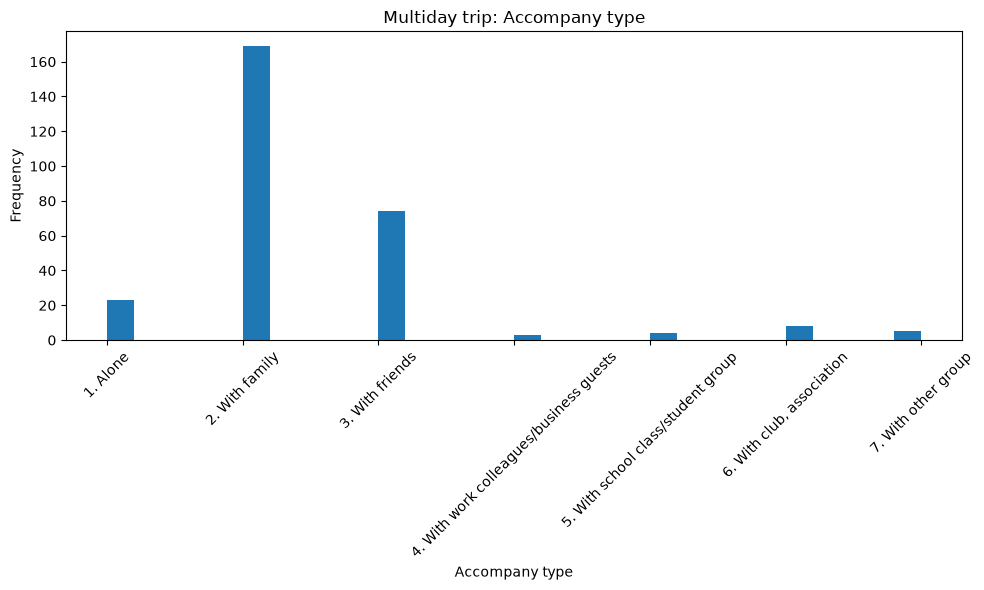

In [126]:
# Plot accompany type for multiday trip visitors
print(df_nbt['B_2_accompany'].value_counts().sort_index())

ax = df_nbt['B_2_accompany'].plot(
    kind='hist',
    bins=30,
    figsize=(10, 6),
    xlabel='Accompany type'
)

# Replace x ticks
ax.set_xticks([1, 2, 3, 4, 5, 6, 7])
ax.set_xticklabels(['1. Alone', '2. With family', '3. With friends', '4. With work colleagues/business guests',
                    '5. With school class/student group', '6. With club, association', '7. With other group'],
                   rotation=45)
ax.set_title('Multiday trip: Accompany type')

plt.tight_layout()
plt.show()

In [127]:
# Average number of accompany for each accompany type
df_nbt.groupby('B_2_accompany')['B_2a_accompany_num'].mean()

B_2_accompany
1.0         NaN
2.0    1.881657
3.0    2.662162
4.0    4.333333
5.0    5.000000
6.0    5.250000
7.0    4.800000
Name: B_2a_accompany_num, dtype: float64

In [128]:
# Frequency counts for accompany with children (1. yes, 2. no)
df_nbt[['B_2b_accompany_children']].value_counts()

B_2b_accompany_children
2.0                        211
1.0                         51
Name: count, dtype: int64

In [129]:
# Gender distribution by accompany type
df_nbt.groupby('B_2_accompany')['gender'].value_counts(normalize=True).unstack()

gender,Female,Male,Other
B_2_accompany,,,
1.0,0.434783,0.565217,NaN
2.0,0.556213,0.437870,0.005917
3.0,0.405405,0.594595,NaN
4.0,0.333333,0.666667,NaN
5.0,0.750000,0.250000,NaN
6.0,0.500000,0.375000,0.125000
7.0,0.600000,0.400000,NaN


In [130]:
# Age distribution by accompany type
df_nbt.groupby('B_2_accompany')['age'].value_counts(normalize=True).unstack()

age,16-24,25-34,35-44,45-54,55-64,65-74,<16,>75
B_2_accompany,,,,,,,,
1.0,NaN,0.173913,0.086957,0.391304,0.260870,0.086957,NaN,NaN
2.0,0.041420,0.218935,0.248521,0.230769,0.112426,0.112426,0.023669,0.011834
3.0,0.067568,0.243243,0.135135,0.135135,0.243243,0.148649,NaN,0.027027
4.0,NaN,0.333333,0.666667,NaN,NaN,NaN,NaN,NaN
5.0,0.750000,0.250000,NaN,NaN,NaN,NaN,NaN,NaN
6.0,0.375000,0.250000,NaN,0.250000,NaN,0.125000,NaN,NaN
7.0,0.400000,NaN,NaN,0.200000,NaN,0.200000,0.200000,NaN


## All visitors

B_2_accompany
1.0     93
2.0    238
3.0     98
4.0      3
5.0      4
6.0      9
7.0      6
Name: count, dtype: int64


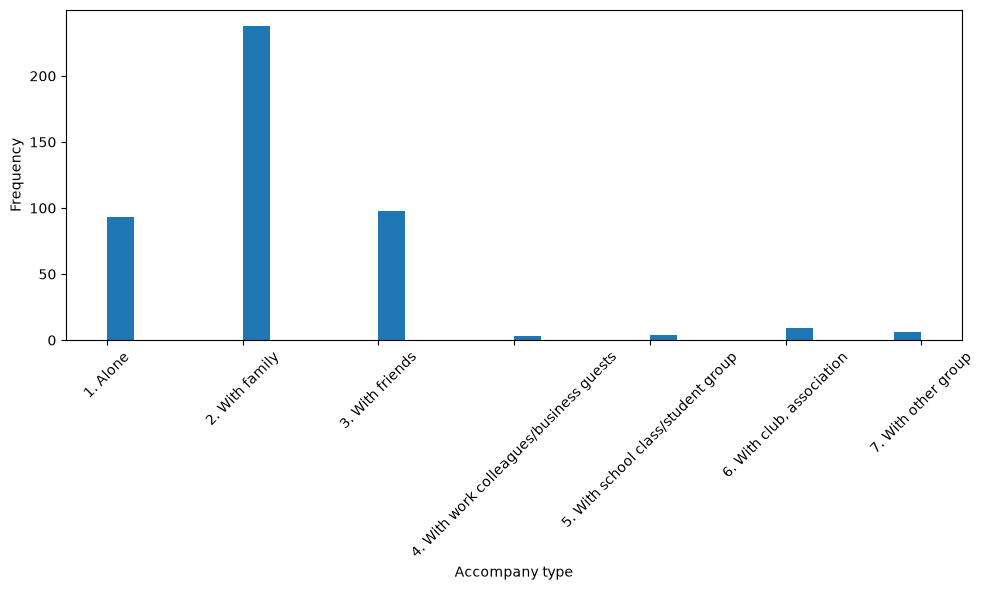

In [131]:
# Plot accompany type for the full dataset
print(df['B_2_accompany'].value_counts().sort_index())

ax = df['B_2_accompany'].plot(
    kind='hist',
    bins=30,
    figsize=(10, 6),
    xlabel='Accompany type'
)

# Replace x ticks
ax.set_xticks([1, 2, 3, 4, 5, 6, 7])
ax.set_xticklabels(['1. Alone', '2. With family', '3. With friends', '4. With work colleagues/business guests',
                    '5. With school class/student group', '6. With club, association', '7. With other group'],
                   rotation=45)

plt.tight_layout()
plt.show()

In [132]:
# Average number of accompany for each accompany type
df.groupby('B_2_accompany')['B_2a_accompany_num'].mean()

B_2_accompany
1.0         NaN
2.0    1.822785
3.0    2.561224
4.0    4.333333
5.0    5.000000
6.0    5.222222
7.0    5.000000
Name: B_2a_accompany_num, dtype: float64

In [133]:
# Frequency counts for accompany with children (1. yes, 2. no)
df[['B_2b_accompany_children']].value_counts()

B_2b_accompany_children
2.0                        285
1.0                         72
Name: count, dtype: int64

In [134]:
# Gender distribution by accompany type
df.groupby('B_2_accompany')['gender'].value_counts(normalize=True).unstack()

gender,Female,Male,Other
B_2_accompany,,,
1.0,0.397849,0.591398,0.010753
2.0,0.521008,0.474790,0.004202
3.0,0.357143,0.642857,NaN
4.0,0.333333,0.666667,NaN
5.0,0.750000,0.250000,NaN
6.0,0.444444,0.444444,0.111111
7.0,0.666667,0.333333,NaN


In [135]:
# Age distribution by accompany type
df.groupby('B_2_accompany')['age'].value_counts(normalize=True).unstack()

age,16-24,25-34,35-44,45-54,55-64,65-74,<16,>75
B_2_accompany,,,,,,,,
1.0,0.096774,0.139785,0.172043,0.193548,0.258065,0.107527,0.010753,0.021505
2.0,0.054622,0.214286,0.243697,0.205882,0.121849,0.121849,0.016807,0.021008
3.0,0.091837,0.224490,0.112245,0.153061,0.214286,0.173469,NaN,0.030612
4.0,NaN,0.333333,0.666667,NaN,NaN,NaN,NaN,NaN
5.0,0.750000,0.250000,NaN,NaN,NaN,NaN,NaN,NaN
6.0,0.333333,0.222222,NaN,0.222222,0.111111,0.111111,NaN,NaN
7.0,0.333333,NaN,NaN,0.166667,NaN,0.333333,0.166667,NaN


# Activities across visiting groups

In [136]:
df.groupby('B_2_accompany')['activity'].value_counts(normalize=True).unstack().fillna(0)

activity,Bird watching,Boating,Camping,Climbing,Cycling,Dog walking,Fishing,Frisbee golf,Golf,Guided tour,...,Picnicking,Running,Skating,Skiing,Snowmobiling,"Staying in a summer cottage, farm, holiday home","Staying overnight in a tent, lodge, etc. in natural terrain",Swimming,Travelling or staying in a caravan or camper,Walking
B_2_accompany,,,,,,,,,,,,,,,,,,,,,
1.0,0.010753,0.010753,0.000000,0.000000,0.118280,0.150538,0.021505,0.000000,0.000000,0.000000,...,0.010753,0.075269,0.000000,0.032258,0.010753,0.021505,0.000000,0.000000,0.000000,0.430108
2.0,0.004202,0.037815,0.004202,0.000000,0.021008,0.029412,0.037815,0.000000,0.004202,0.004202,...,0.025210,0.012605,0.004202,0.121849,0.004202,0.012605,0.004202,0.004202,0.016807,0.533613
3.0,0.000000,0.020408,0.000000,0.010204,0.010204,0.040816,0.122449,0.020408,0.020408,0.020408,...,0.040816,0.010204,0.000000,0.061224,0.040816,0.010204,0.030612,0.010204,0.010204,0.418367
4.0,0.000000,0.333333,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.666667
5.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
6.0,0.000000,0.111111,0.111111,0.000000,0.000000,0.000000,0.000000,0.111111,0.000000,0.000000,...,0.000000,0.111111,0.000000,0.111111,0.000000,0.000000,0.000000,0.000000,0.000000,0.111111
7.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.166667,...,0.000000,0.000000,0.000000,0.166667,0.000000,0.000000,0.000000,0.000000,0.000000,0.666667


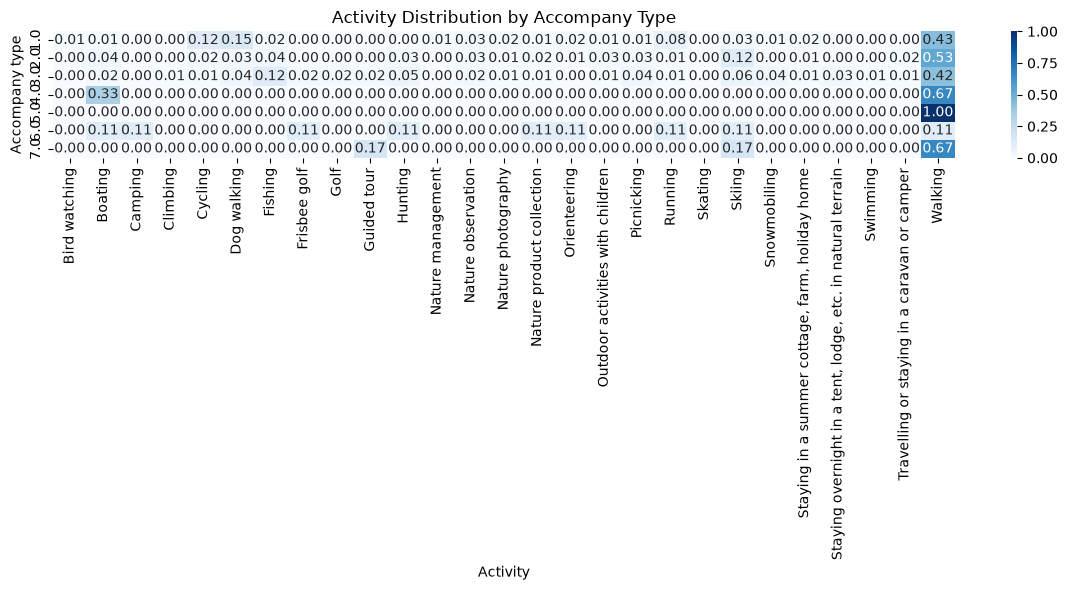

In [137]:
table = (
    df.groupby('B_2_accompany')['activity']
    .value_counts(normalize=True)
    .unstack()
    .fillna(0)
)

plt.figure(figsize=(12, 6))
sns.heatmap(
    table,
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.xlabel('Activity')
plt.ylabel('Accompany type')
plt.title('Activity Distribution by Accompany Type')
plt.tight_layout()
plt.show()

# Demographics across activities

## Gender

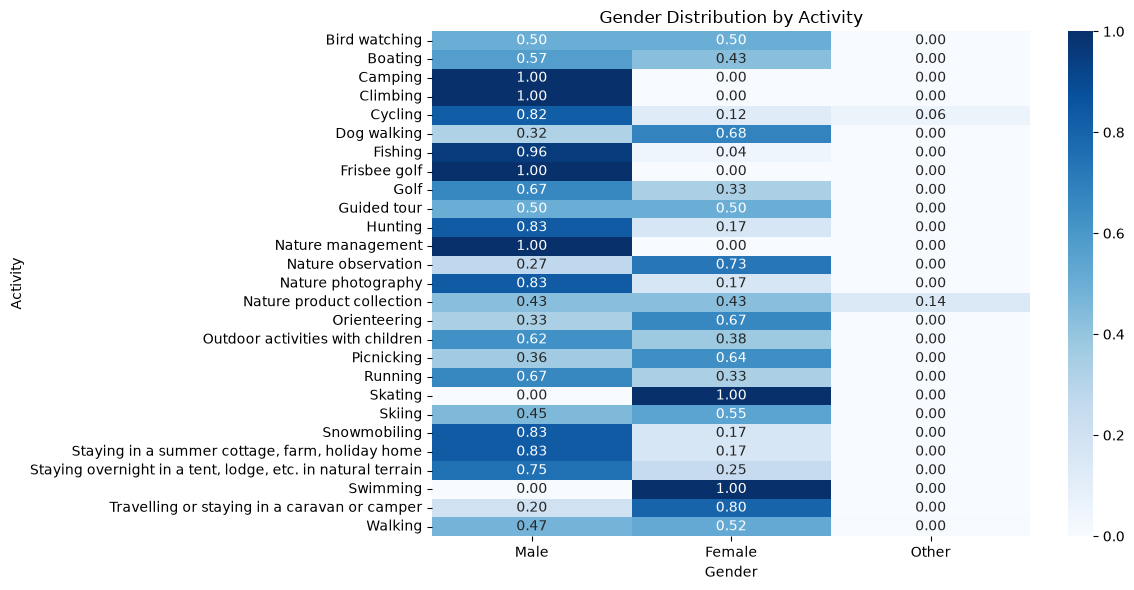

In [138]:
table = (
    df.groupby('activity')['gender']
    .value_counts(normalize=True)
    .unstack()
    .fillna(0)
)

# Enforce original order
table = table.reindex(columns=['Male', 'Female', 'Other'])

plt.figure(figsize=(12, 6))
sns.heatmap(
    table,
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.xlabel('Gender')
plt.ylabel('Activity')
plt.title('Gender Distribution by Activity')
plt.tight_layout()
plt.show()

## Age

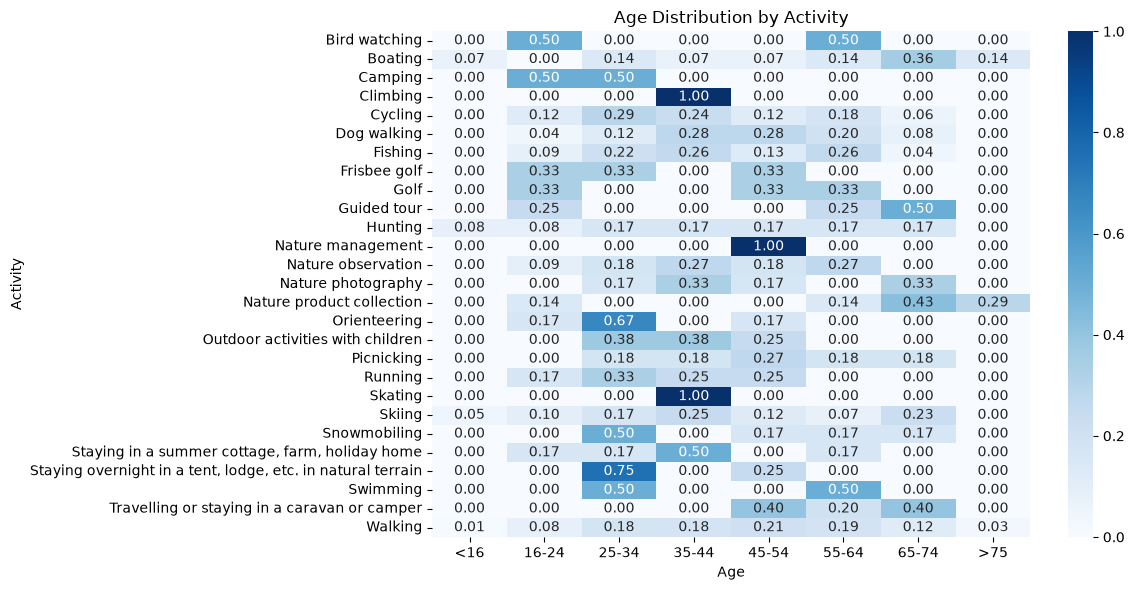

In [139]:
table = (
    df.groupby('activity')['age']
    .value_counts(normalize=True)
    .unstack()
    .fillna(0)
)

# Enforce original order
table = table.reindex(columns=['<16', '16-24', '25-34', '35-44', '45-54', '55-64', '65-74', '>75'])

plt.figure(figsize=(12, 6))
sns.heatmap(
    table,
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.xlabel('Age')
plt.ylabel('Activity')
plt.title('Age Distribution by Activity')
plt.tight_layout()
plt.show()

# Motivations across visiting groups

In [140]:
df.groupby('B_2_accompany')[motivation_col].mean()

,motivation_1_peace,motivation_2_natural_products,motivation_3_landscapes,motivation_4_experiences,motivation_5_fitness,motivation_6_recovery,motivation_7_time,motivation_8_social,motivation_9_personal_skills,motivation_10_adventure
B_2_accompany,,,,,,,,,,
1.0,3.451613,1.806452,3.365591,3.172043,3.397849,3.462366,3.494624,2.032258,2.322581,2.430108
2.0,3.680672,1.949580,3.710084,3.626050,3.151261,3.500000,3.319328,3.680672,2.474790,2.857143
3.0,3.591837,1.867347,3.479592,3.520408,3.030612,3.418367,3.244898,3.581633,2.561224,3.020408
4.0,4.000000,1.666667,4.333333,4.000000,3.333333,4.000000,4.000000,4.333333,3.000000,3.000000
5.0,3.750000,2.000000,4.000000,3.500000,3.750000,4.000000,3.250000,3.250000,3.000000,4.000000
6.0,2.888889,2.000000,3.444444,3.333333,3.444444,3.444444,3.111111,3.444444,3.111111,3.000000
7.0,3.333333,2.166667,3.833333,3.333333,2.666667,3.166667,2.833333,3.500000,2.500000,3.166667


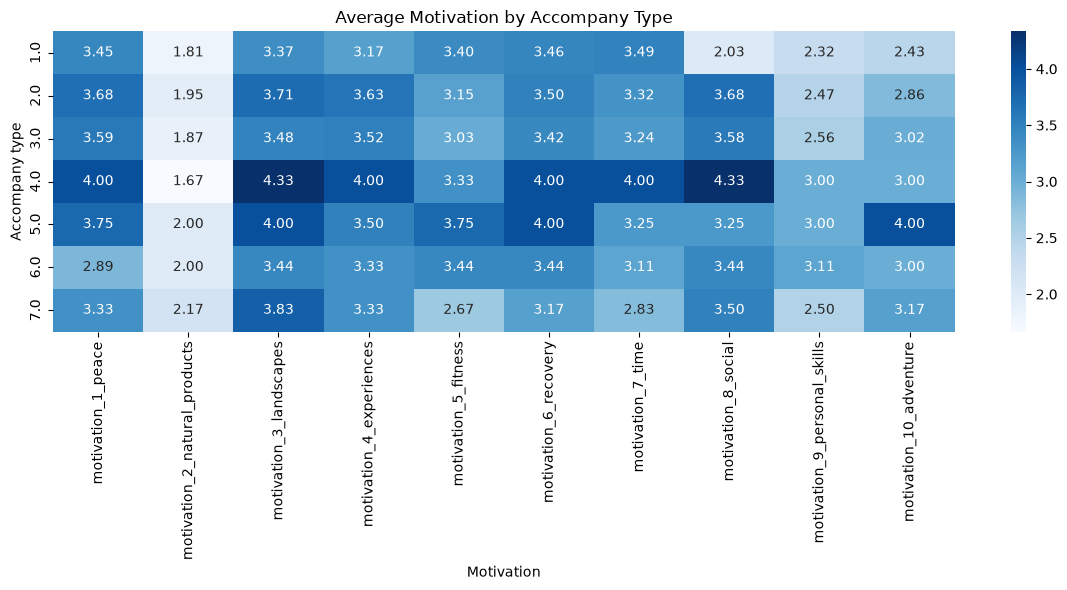

In [141]:
table = df.groupby('B_2_accompany')[motivation_col].mean()

plt.figure(figsize=(12, 6))
sns.heatmap(
    table,
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.xlabel('Motivation')
plt.ylabel('Accompany type')
plt.title('Average Motivation by Accompany Type')
plt.tight_layout()
plt.show()

# Municipality map

In [142]:
import geopandas as gpd
import pyogrio

# List layers (geopandas 1.x uses pyogrio; fiona is not installed)
path_gpkg = '../../../data/boundaries/SuomenHallinnollisetKuntajakopohjaisetAluejaot_2026_10k.gpkg'
layers = pyogrio.list_layers(path_gpkg)
print(layers)

[['Maakunta' 'Unknown']
 ['Elinvoimakeskus' 'Unknown']
 ['Valtakunta' 'Unknown']
 ['Kunta' 'Unknown']
 ['Hyvinvointialue' 'Unknown']]


In [143]:
gdf_municipality = gpd.read_file(path_gpkg, layer='Kunta')
gdf_municipality.shape

(308, 9)

In [144]:
gdf_municipality['lvvi3_count'] = (gdf_municipality['namefin'].map(df['area_municipality'].value_counts()))
gdf_municipality[['namefin', 'lvvi3_count']]

,namefin,lvvi3_count
0,Parainen,4.0
1,Outokumpu,1.0
2,Rauma,8.0
3,Alajärvi,NaN
4,Posio,7.0
...,...,...
303,Teuva,1.0
304,Hankasalmi,NaN
305,Soini,1.0
306,Kauhava,1.0


In [145]:
df['area_municipality'].value_counts()[:20].to_frame()

,count
area_municipality,
Kuusamo,28
Inari,26
Kolari,25
Espoo,24
Enontekiö,13
Lieksa,12
Muonio,10
Helsinki,9
Hämeenlinna,9


In [146]:
gdf_municipality["lvvi3_count"].max()

np.float64(28.0)

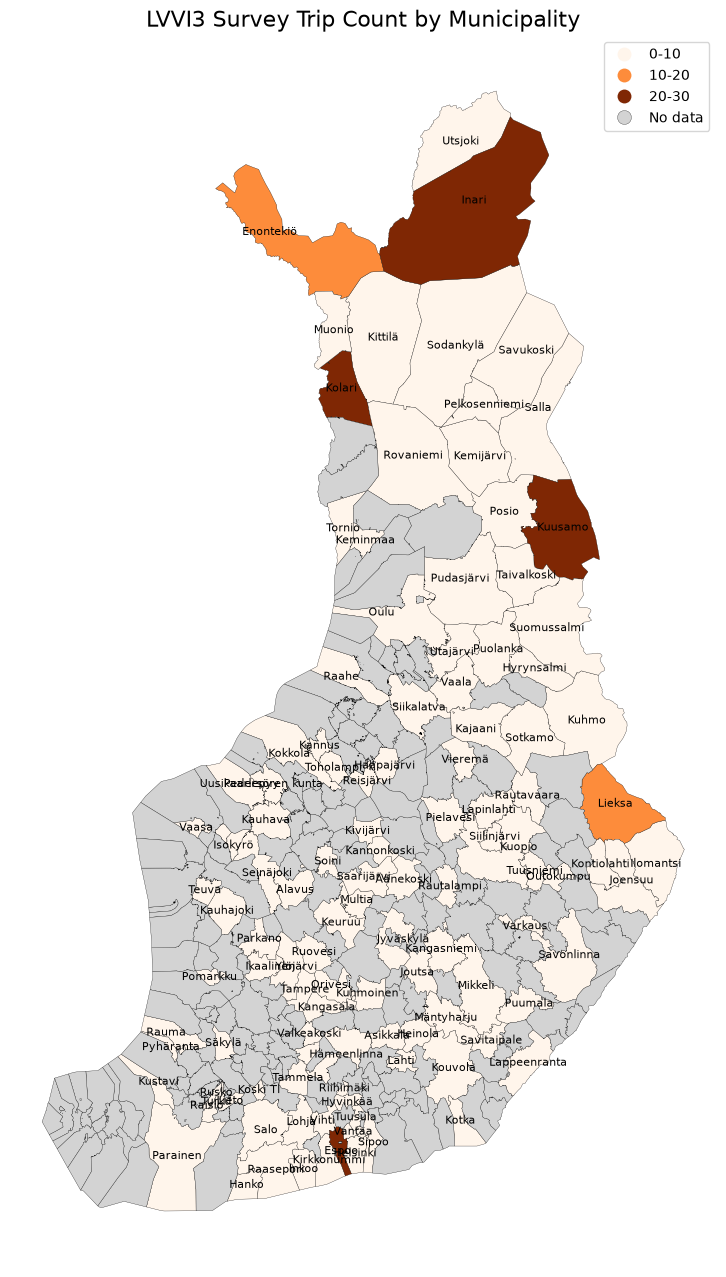

In [147]:
bins = [0, 10, 20, 30]
labels = ["0-10", "10-20", "20-30"]

gdf_municipality["lvvi3_cat"] = pd.cut(gdf_municipality["lvvi3_count"], bins=bins, labels=labels)

fig, ax = plt.subplots(1, 1, figsize=(12, 16))

gdf_municipality.plot(
    column="lvvi3_cat",
    categorical=True,
    cmap="Oranges",
    legend=True,
    ax=ax,
    edgecolor="black",
    linewidth=0.2,
    missing_kwds={"color": "lightgrey", "label": "No data"}
)

# Label municipalities with at least one survey trip
for _, row in gdf_municipality.iterrows():
    if row.geometry is not None and pd.notna(row["lvvi3_cat"]):
        point = row.geometry.representative_point()
        ax.annotate(
            row["namefin"],
            xy=(point.x, point.y),
            ha="center",
            va="center",
            fontsize=8,
            color="black"
        )

ax.set_title("LVVI3 Survey Trip Count by Municipality", fontsize=16)
ax.axis("off")

plt.show()